# LandCoverNet Asia — Semantic Segmentation with SAM 2.1 (Hiera-B+) · Kaggle T4 ×2 · *Save & Run All*

SAM 2.1 Hiera-B+ image encoder + light multi-scale semantic head, `ce_dice` loss (sqrt-inverse class weights, label smoothing 0.1), AdamW with layer-wise LR decay, warm-up + cosine, `rs_strong` augmentation, ImageNet normalisation, AMP, EMA weights, real 2-process DDP with `torchrun`, early stopping. **v3 = regularisation / evaluation fixes against overfitting (see next cell).**

**Before pressing *Save Version → Save & Run All (Commit)*:**
1. *Add Input* → attach the **LandCoverNet Asia** dataset (it is read directly from `/kaggle/input`; nothing is downloaded).
2. *Settings* → Accelerator **GPU T4 ×2**, Internet **ON** (needed only to `pip install` SAM 2 and fetch its 323 MB pretrained checkpoint).

**What you get in the Output zip** (`/kaggle/working`): **`bestmodel.pt`** (self-contained: weights + config + class names + normalisation), `inference/` (`predict.py` + the 3 small modules it needs), and `lulc_research/` (logs, metrics CSVs, figures, splits). Big scratch files (SAM checkpoint, RGB composites, optimiser checkpoints) are kept out of the zip.

**Data handling (verified at run time, printed in the logs, never silently assumed).**
* Layout is auto-detected: original LandCoverNet (`labels.tif` + multi-date Sentinel-2 band TIFs) *or* ready-made image/mask folders.
* Original layout: one training image per chip = **per-pixel percentile composite over the dates (see `COMPOSITE_PCT`, `USE_NIR`)**, scaled by a fixed reflectance stretch (`REFL_MAX`) to 8-bit RGB, so the rest of the pipeline is identical to the Sen-2 run.
* Classes (official LandCoverNet documentation, same as `io_utils.py`): 1 Water · 2 Artificial bare ground · 3 Natural bare ground · 4 Permanent snow/ice · 5 Woody vegetation · 6 Cultivated vegetation · 7 (Semi) natural vegetation; **0 = no data → ignored**; labels 1–7 → model ids 0–6.
* Split: seeded **tile-level, class-stratified** ~70/15/15 split (best of 2000 candidate tile permutations; the dataset's own STAC split is not downloaded). Tile counts and per-split class shares are printed. The test split is only touched once, after training.


## What changed in v3 (overfitting fixes; previous run: train mIoU 0.66 vs val 0.43, test 0.396)
Diagnosis from the previous run's log: val mIoU plateaued at ~0.42 from epoch ~20 while train mIoU kept rising (gap 0.12 → 0.23); val loss was lowest at epoch 29 and then rose; the "best" epoch (71) was the maximum of a noisy series (±0.016 epoch-to-epoch).

| Area | Change |
|---|---|
| Capacity | `freeze_blocks=5` (patch-embed + Hiera stages 1-2 frozen), `enc_lr_mult` 0.1→0.05, `drop_path` 0.1→0.2, `head_drop` 0.2→0.3 |
| Selection / stopping | `ema_decay=0.998` (**EMA weights are now evaluated *and* saved**; before, enabling EMA would have scored raw weights but saved EMA weights), `epochs` 150→60, `patience` 50→15, warm-up 5→3 |
| Split | tile-level split now **class-stratified** (val/test class shares ≈ train); tile counts and class shares printed; overlap check against train chips |
| Class weights | `median` (≈17x spread) → `sqrt` (≈4x). Dice already handles imbalance |
| Logging | per-class val IoU every epoch (`val_iou_1..7`); every 5 epochs mIoU on 500 un-augmented *train* chips (`clean_train_miou`) = the true train/val gap |
| Safety | smoke test + 2-epoch DDP + resume test **enabled** (`RUN_SMOKE`), so a code error fails in minutes, not after the download |
| Optional | `RUN_ABLATIONS` cell (validation-only runs, off by default); per-tile error table after the test evaluation |

Unchanged on purpose: dataset, composites, architecture, ImageNet normalisation, `rs_strong` augmentation, batch 8 x 2 GPUs, loss = CE + Dice. **Because the split changed, v3 numbers are NOT comparable to the previous run's** (new tiles in val/test).

**Before *Save Version → Save & Run All*:** Add the Input is *not* needed (data is downloaded). Settings → GPU T4 x2, Internet ON. Expected: download as before, smoke test ~5 min, training ~25-35 min, test eval < 1 min.
**Run order:** download → layout → calibration → composites → diagnostic → split → overlap check → scan → ... If you change `DATES_PER_CHIP` or `USE_NIR`, delete `/kaggle/temp/landcovernet_as` first.

## 1. Environment, GPUs and scratch space

In [1]:
import os, sys, json, time, shutil, platform, subprocess, random, datetime, re, hashlib, warnings, glob, copy, zipfile, tarfile
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

ROOT = "/kaggle/working/lulc_research"      # small, useful files only -> part of the downloadable Output zip
for d in ["dataset_analysis", "splits", "preprocessing", "experiments", "reproducibility", "code"]:
    os.makedirs(f"{ROOT}/{d}", exist_ok=True)
os.makedirs("/kaggle/working/inference", exist_ok=True)       # bestmodel.pt helper code is written here later
os.environ["LULC_ROOT"] = ROOT

# Big scratch files (SAM checkpoint, extracted archives, RGB composites) live in /kaggle/temp: NOT saved in the Output zip.
TEMP = "/kaggle/temp"
try: os.makedirs(TEMP, exist_ok=True)
except Exception: TEMP = "/tmp/kaggle_temp"; os.makedirs(TEMP, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
RUN_STARTED = datetime.datetime.now().isoformat(timespec="seconds")

print("Python", platform.python_version(), "|", platform.platform())
_smi = subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout
print(_smi)
N_GPUS = len([l for l in _smi.splitlines() if l.strip().startswith("GPU")])
assert N_GPUS >= 1, "No GPU found: Settings > Accelerator > GPU T4 x2"
if N_GPUS < 2:
    print("WARNING: only 1 GPU visible. Training will run single-process (effective batch halves). Select GPU T4 x2 for the intended setup.")
import torch
print("torch", torch.__version__, "| CUDA", torch.version.cuda, "| GPUs (nvidia-smi):", N_GPUS)
print("CPU cores:", os.cpu_count())
du = shutil.disk_usage("/kaggle/working"); print(f"/kaggle/working free: {du.free/2**30:.1f} GiB of {du.total/2**30:.1f} GiB | scratch dir: {TEMP}")


Python 3.13.16 | Linux-6.18.55+-x86_64-with-glibc2.39
GPU 0: Tesla T4 (UUID: GPU-75361b84-ebc4-b767-5295-8888ca58906d)
GPU 1: Tesla T4 (UUID: GPU-ec313675-f735-70f8-845a-de6859be98b5)

torch 2.11.0+cu130 | CUDA 13.0 | GPUs (nvidia-smi): 2
CPU cores: 4
/kaggle/working free: 19.5 GiB of 19.5 GiB | scratch dir: /kaggle/temp


## 2. Dependencies (SAM 2.1 + pretrained Hiera-B+ checkpoint)
Only *adds* packages; PyTorch/CUDA are never replaced. Needs **Internet = ON**.

In [2]:
!pip install -q rasterio tifffile 2>&1 | tail -2
try:
    import rasterio; print("rasterio", rasterio.__version__)
except Exception as e:
    print("rasterio unavailable ->", repr(e), "(tifffile fallback is used for reading GeoTIFFs)")


rasterio 1.5.2


In [3]:
# SAM 2.1 (official facebookresearch/sam2). --no-deps so PyTorch/CUDA are NEVER replaced (sam2 needs torch >= 2.5.1: checked below).
!pip install -q --no-deps "git+https://github.com/facebookresearch/sam2.git"
!pip install -q hydra-core iopath
import torch, requests
assert tuple(int(x) for x in torch.__version__.split("+")[0].split(".")[:2]) >= (2, 5), f"SAM 2 needs torch>=2.5.1, found {torch.__version__}"
SAM_CK_DIR = f"{TEMP}/sam_ckpt"; os.makedirs(SAM_CK_DIR, exist_ok=True)     # scratch: keeps the 323 MB checkpoint out of the Output zip
SAM_CKPT = f"{SAM_CK_DIR}/sam2.1_hiera_base_plus.pt"
MIN_BYTES = 300 * 2**20
# Same file, two hosts. The Meta CDN is tried first, Hugging Face is the fallback if its TLS certificate chain is rejected on this machine.
SAM_URLS = ["https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_base_plus.pt",
            "https://huggingface.co/facebook/sam2.1-hiera-base-plus/resolve/main/sam2.1_hiera_base_plus.pt"]

def _ok(): return os.path.exists(SAM_CKPT) and os.path.getsize(SAM_CKPT) > MIN_BYTES

def _dl_requests(url, verify=True):                      # requests validates with certifi's CA bundle (urllib used the OS bundle, which failed)
    tmp = SAM_CKPT + ".part"
    with requests.get(url, stream=True, timeout=(15, 120), verify=verify) as r:
        r.raise_for_status()
        with open(tmp, "wb") as f:
            for chunk in r.iter_content(1 << 20): f.write(chunk)
    os.replace(tmp, SAM_CKPT)

def _dl_cli(url):                                          # wget / curl use the OS CA store directly
    for cmd in (["wget", "-q", "-O", SAM_CKPT + ".part", url], ["curl", "-sSfL", "-o", SAM_CKPT + ".part", url]):
        try:
            if subprocess.run(cmd, capture_output=True, timeout=1800).returncode == 0:
                os.replace(SAM_CKPT + ".part", SAM_CKPT); return
        except Exception as e: print("  ", cmd[0], "failed:", repr(e)[:150])
    raise RuntimeError("wget/curl failed")

if not _ok():
    # 1) normal, verified downloads (requests -> wget/curl), each URL in turn
    for url in SAM_URLS:
        for name, fn in (("requests", _dl_requests), ("wget/curl", _dl_cli)):
            if _ok(): break
            try: print(f"downloading via {name}: {url}"); fn(url)
            except Exception as e: print("   failed:", repr(e)[:200])
        if _ok(): break
    # 2) refresh the CA bundle and retry once
    if not _ok():
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "certifi"])
        for url in SAM_URLS:
            try: _dl_requests(url); break
            except Exception as e: print("   failed after certifi update:", repr(e)[:200])
    # 3) LAST RESORT: skip certificate verification (only for this public, size-checked weights file)
    if not _ok():
        print("WARNING: all verified downloads failed -> retrying WITHOUT certificate verification (size-checked).")
        for url in SAM_URLS:
            try: _dl_requests(url, verify=False); break
            except Exception as e: print("   failed:", repr(e)[:200])
assert _ok(), ("SAM 2.1 checkpoint download failed. Check Internet = ON, or add the file as a Kaggle dataset and set SAM_CKPT to its /kaggle/input path.")
import sam2; print("sam2 import OK | checkpoint:", SAM_CKPT, f"{os.path.getsize(SAM_CKPT)/2**20:.0f} MiB")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
downloading via requests: https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_base_plus.pt
   failed: SSLError(MaxRetryError("HTTPSConnectionPool(host='dl.fbaipublicfiles.com', port=443): Max retries exceeded with url: /segment_anything_2/092824/sam2.1_hiera_base_plus.pt (Caused by SSLError(SSLCertVer
downloading via wget/curl: https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_base_plus.pt
   failed: RuntimeError('wget/curl failed')
downloading via requests: https://huggingface.co/facebook/sam2.1-hiera-base-plus/resolve/main/sam2.1_hiera_base_plus.pt


## 3. Shared I/O module (`io_utils.py`)
One reader / label-mapping implementation used by dataset scanning **and** training. Classes are LandCoverNet's 7; source label 0 (no data) is ignored.

In [4]:
%%writefile /kaggle/working/lulc_research/code/io_utils.py
"""io_utils.py -- image/mask readers and label mapping shared by Part 1 (scan) and Part 2 (training).
LandCoverNet source labels: 0 = no data (ignored), 1..7 = 7 land-cover classes.  Model labels: 0..6, 255 = ignore.
"""
import os
import numpy as np
from PIL import Image

NUM_CLASSES = 7
IGNORE_INDEX = 255
#CLASS_NAMES_SRC = {1: "Water", 2: "Natural Bare Ground", 3: "Artificial Bare Ground", 4: "Woody Vegetation", 5: "Cultivated Vegetation", 6: "(Semi) Natural Vegetation", 7: "Permanent Snow/Ice"}

CLASS_NAMES_SRC = {
    1: "Water",
    2: "Artificial Bare Ground",
    3: "Natural Bare Ground",
    4: "Permanent Snow/Ice",
    5: "Woody Vegetation",
    6: "Cultivated Vegetation",
    7: "(Semi) Natural Vegetation"
}

MODEL_CLASS_NAMES = [CLASS_NAMES_SRC[i] for i in range(1, 8)]

# source id -> model id.  source 0 (Unclassified) and anything unexpected -> IGNORE_INDEX
LUT_SRC2MODEL = np.full(256, IGNORE_INDEX, dtype=np.uint8)
for _s in range(1, 8):
    LUT_SRC2MODEL[_s] = _s - 1
SRC_FROM_MODEL = np.arange(1, 8, dtype=np.uint8)   # model id k -> source id k+1


def read_image(path):
    """Return HxWx3 array (native dtype), channel order R,G,B. Original mode is NOT hidden from Part 1
    inspection (which opens the file separately)."""
    ext = os.path.splitext(path)[1].lower()
    if ext in (".tif", ".tiff"):
        import rasterio
        with rasterio.open(path) as ds:
            arr = ds.read([1, 2, 3]).transpose(1, 2, 0)
        return arr
    im = Image.open(path)
    if im.mode != "RGB":
        im = im.convert("RGB")
    return np.asarray(im)


def read_mask_raw(path):
    ext = os.path.splitext(path)[1].lower()
    if ext in (".tif", ".tiff"):
        import rasterio
        with rasterio.open(path) as ds:
            a = ds.read()
        return a[0] if a.shape[0] == 1 else a.transpose(1, 2, 0)
    return np.asarray(Image.open(path))   # 'P' images yield palette INDICES (what we want)


def decode_mask(arr, enc):
    """Raw mask array -> uint8 array of SOURCE class ids (0..7). Unmapped colours -> 255.
    enc: {"type": "indexed"} or {"type": "rgb", "color_map": {"<packed_rgb_int>": source_id}}"""
    if arr.ndim == 3:
        if enc.get("type") == "rgb":
            a = arr.astype(np.uint32)
            packed = (a[..., 0] << 16) | (a[..., 1] << 8) | a[..., 2]
            out = np.full(packed.shape, 255, np.uint8)
            for k, v in enc["color_map"].items():
                out[packed == int(k)] = v
            return out
        arr = arr[..., 0]
    return np.clip(arr, 0, 255).astype(np.uint8)


def src_to_model(src):
    return LUT_SRC2MODEL[src]

Writing /kaggle/working/lulc_research/code/io_utils.py


## 4. Locate LandCoverNet Asia 

In [5]:

# ================================================================
# CELL 9 — DOWNLOAD LANDCOVERNET ASIA FROM OFFICIAL RADIANT EARTH
# Compatible with the existing SAM2 Kaggle notebook
# ================================================================

import os
import re
import time
import random
import shutil
import threading
import requests
import xml.etree.ElementTree as ET

from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
from urllib.parse import quote
from tqdm.auto import tqdm

# ================================================================
# 1. SETTINGS EXPECTED BY THE LATER NOTEBOOK CELLS
# ================================================================

REFL_MAX = 0.30
LABELS_ZERO_BASED = False
SPLIT_FRACTIONS = (0.70, 0.15, 0.15)
KEY_REGEX = None
EXTS = {".tif", ".tiff", ".png", ".jpg", ".jpeg"}

# ================================================================
# 2. USER SETTINGS — CHANGE THESE WHEN NEEDED
# ================================================================

MAX_CHIPS = None          # None = every Asia chip (~2,700). Use 1000 for a faster run.
DATES_PER_CHIP = 8        # dates per chip, spread over 2018 (the official labels use 24 scenes)
USE_NIR = True           # True = false-colour input (B08 NIR, B04 red, B03 green): ~1/3 more download, best for vegetation classes
COMPOSITE_PCT = 30        # per-pixel percentile over the dates (30 suppresses clouds / seasonal snow; 50 = median)
S2_NEEDED = (2, 3, 4, 8) if USE_NIR else (2, 3, 4)      # Sentinel-2 bands to download
COMP_BANDS = (8, 4, 3) if USE_NIR else (4, 3, 2)        # bands -> image channels 1, 2, 3
COMP_DESC = "false colour (B08,B04,B03)" if USE_NIR else "RGB (B04,B03,B02)"
DOWNLOAD_WORKERS = 8

# ================================================================
# 3. OFFICIAL REPOSITORY CONFIGURATION
# ================================================================

# TEMP and SEED are normally defined in Cell 2
TEMP = globals().get("TEMP", "/kaggle/temp")
SEED = globals().get("SEED", 42)

BASE = (
    "https://data.source.coop/"
    "radiantearth/landcovernet"
)

PREFIX = "landcovernet_as/data/v1.0/2018/"

DATA_DIR = os.path.join(TEMP, PREFIX.rstrip("/"))
os.makedirs(DATA_DIR, exist_ok=True)


# ================================================================
# 4. NORMALIZE SOURCE COOPERATIVE OBJECT KEYS
# ================================================================

def normal_key(key):
    """
    Normalize keys that may contain an extra landcovernet/
    prefix returned by the repository listing endpoint.
    """
    key = str(key).lstrip("/")

    marker = "landcovernet_as/"
    pos = key.find(marker)

    if pos < 0:
        raise ValueError(
            f"Unexpected Source Cooperative key: {key}"
        )

    return key[pos:]


def object_url(key):
    """Construct a valid official download URL."""
    return BASE + "/" + quote(
        normal_key(key),
        safe="/"
    )


# ================================================================
# 5. HTTP REQUEST WITH RETRIES
# ================================================================

def get_with_retries(
    url,
    *,
    stream=False,
    attempts=4
):
    last_error = None

    for attempt in range(attempts):
        try:
            response = requests.get(
                url,
                stream=stream,
                timeout=(15, 90)
            )

            response.raise_for_status()
            return response

        except requests.HTTPError as e:
            status = (
                e.response.status_code
                if e.response is not None
                else None
            )

            last_error = e

            if status in (403, 404):
                raise

        except requests.RequestException as e:
            last_error = e

        time.sleep(min(10, 1.5 * (2 ** attempt)))

    raise RuntimeError(
        f"Request failed: {url}\n{last_error}"
    )


# ================================================================
# 6. LIST OFFICIAL DATASET FOLDERS
# ================================================================

def list_folders(prefix):
    """
    Retrieve directory prefixes from Source Cooperative's
    public S3-compatible listing API.
    """

    result = []
    continuation = None

    while True:

        params = {
            "list-type": "2",
            "prefix": normal_key(prefix),
            "delimiter": "/",
            "max-keys": 1000
        }

        if continuation:
            params["continuation-token"] = continuation

        for attempt in range(4):
            try:
                response = requests.get(
                    BASE,
                    params=params,
                    timeout=(15, 90)
                )

                response.raise_for_status()

                root = ET.fromstring(response.content)

                if not root.tag.endswith("ListBucketResult"):
                    raise ValueError(
                        "Unexpected listing response: "
                        + response.text[:200]
                    )

                break

            except Exception as e:
                if attempt == 3:
                    raise RuntimeError(
                        f"Failed listing {prefix}: {e}"
                    )

                time.sleep(2 ** attempt)

        for node in root.findall(
            ".//{*}CommonPrefixes/{*}Prefix"
        ):
            if node.text:
                result.append(normal_key(node.text))

        continuation = root.findtext(
            "{*}NextContinuationToken"
        )

        if not continuation:
            break

    return sorted(set(result))


# ================================================================
# 7. VERIFY OFFICIAL REPOSITORY CONNECTION
# ================================================================

print("Connecting to Radiant Earth...")

test_url = object_url(
    "landcovernet_as/README.md"
)

response = get_with_retries(test_url)
response.close()

print("Official repository connection: OK")


# ================================================================
# 8. DISCOVER SENTINEL-2 TILES
# ================================================================

tiles = list_folders(PREFIX)

tiles = [
    tile
    for tile in tiles
    if re.fullmatch(
        re.escape(PREFIX) + r"\d{2}[A-Z]{3}/",
        tile
    )
]

assert tiles, (
    "No Sentinel-2 tile folders found. "
    "Check Internet access and repository paths."
)

print("Total tile folders:", len(tiles))
print("Example tiles:", tiles[:3])


# ================================================================
# 9. GENERATE CHIP CANDIDATES
# ================================================================

# LandCoverNet uses chip IDs 00 to 29 within each tile.
# Some chips are absent from the published dataset.

candidates = [
    f"{tile}{i:02d}/"
    for tile in tiles
    for i in range(30)
]

random.Random(SEED).shuffle(candidates)

if MAX_CHIPS is not None:

    assert MAX_CHIPS >= 1

    candidates = candidates[
        :min(len(candidates), MAX_CHIPS + 30)
    ]

print("Candidate chips:", len(candidates))


# ================================================================
# 10. DISCOVER VALID CHIP METADATA
# ================================================================

def inspect_chip(chip):
    """
    Read official labeling_dates.csv.

    If CSV parsing fails, try discovering S2 dates directly.
    """

    tile, chip_id = chip.rstrip("/").split("/")[-2:]
    stem = f"{tile}_{chip_id}"

    csv_key = (
        f"{chip}{stem}_labeling_dates.csv"
    )

    dates = []
    error_message = None

    try:
        response = get_with_retries(
            object_url(csv_key),
            attempts=3
        )

        raw = response.text
        response.close()

        # Support YYYYMMDD
        dates = re.findall(
            r"(?<!\d)20\d{6}(?!\d)",
            raw
        )

        # Support YYYY-MM-DD
        dates += [
            x.replace("-", "")
            for x in re.findall(
                r"(?<!\d)20\d{2}-\d{2}-\d{2}(?!\d)",
                raw
            )
        ]

        dates = sorted(set(
            date
            for date in dates
            if date.startswith("2018")
        ))

    except Exception as e:
        error_message = str(e)

    # Fallback: list actual S2 observation folders
    if not dates:

        try:
            folders = list_folders(
                chip + "S2/"
            )

            dates = sorted(set(
                match.group(1)
                for folder in folders
                if (
                    match := re.search(
                        rf"/{re.escape(stem)}_(2018\d{{4}})/$",
                        folder
                    )
                )
            ))

        except Exception as e:
            error_message = (
                f"{error_message}; S2 listing: {e}"
            )

    if not dates:
        return (
            chip,
            None,
            [],
            error_message or "No S2 dates"
        )

    return chip, stem, dates, None


# ================================================================
# 11. VALIDATE CHIPS CONCURRENTLY
# ================================================================

found = []
rejected = []

with ThreadPoolExecutor(
    max_workers=min(DOWNLOAD_WORKERS, 12)
) as pool:

    futures = {
        pool.submit(inspect_chip, chip): chip
        for chip in candidates
    }

    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Checking chip metadata"
    ):

        chip, stem, dates, error = future.result()

        if dates:
            found.append((chip, stem, dates))
        else:
            rejected.append((chip, error))


# Preserve reproducible seeded selection
positions = {
    chip: i
    for i, chip in enumerate(candidates)
}

found.sort(
    key=lambda item: positions[item[0]]
)

if MAX_CHIPS is not None:
    found = found[:MAX_CHIPS]

assert found, (
    "No valid chips found. "
    f"Example errors: {rejected[:3]}"
)

print("\nDiscovery complete")
print("Valid chips:", len(found))
print("Unavailable candidates:", len(rejected))


# ================================================================
# 12. LIST THE REAL FILES OF EACH CHIP (no file names are guessed)
# ================================================================

# The 404 came from *guessing* "<tile>_<chip>_LC_10m.tif".  The actual file names in the
# Asia repository are not guaranteed to follow that pattern, so we LIST every chip folder
# and pick the label / B02-B03-B04 files that really exist.

def list_keys(prefix):
    """All object keys below `prefix` (recursive, paginated S3-style listing)."""
    keys, continuation = [], None
    while True:
        params = {"list-type": "2", "prefix": normal_key(prefix), "max-keys": 1000}
        if continuation:
            params["continuation-token"] = continuation
        for attempt in range(4):
            try:
                r = requests.get(BASE, params=params, timeout=(15, 90))
                r.raise_for_status()
                root = ET.fromstring(r.content)
                break
            except Exception as e:
                if attempt == 3:
                    raise RuntimeError(f"Failed listing {prefix}: {e}")
                time.sleep(2 ** attempt)
        keys += [normal_key(n.text) for n in root.findall(".//{*}Contents/{*}Key") if n.text]
        continuation = root.findtext("{*}NextContinuationToken")
        if not continuation:
            break
    return keys


LABEL_FILE_RE = re.compile(r"_LC_10m\.tif$", re.I)                     # <stem>_LC_10m.tif  or  <stem>_2018_LC_10m.tif
S2_BAND_RE = re.compile(r"_(\d{8})_B0([2348])_10m\.tif$", re.I)         # ..._YYYYMMDD_B02_10m.tif


def pick_files(keys):
    """-> (label_key or None, {date: {2: key, 3: key, 4: key}} for dates having all of B02/B03/B04)."""
    labels = [k for k in keys
              if LABEL_FILE_RE.search(k) and not any(f"/{p}/" in k for p in ("S1", "S2", "L8"))]
    label = sorted(labels, key=lambda k: (len(k), k))[0] if labels else None
    by_date = defaultdict(dict)
    for k in keys:
        m = S2_BAND_RE.search(k)
        if m and "/S2/" in k:
            by_date[m.group(1)][int(m.group(2))] = k
    complete = {d: b for d, b in by_date.items() if d.startswith("2018") and all(x in b for x in S2_NEEDED)}
    return label, complete


assert DATES_PER_CHIP >= 1
print("\nListing the real files of each chip ...")

listed, skipped = {}, []
with ThreadPoolExecutor(max_workers=min(DOWNLOAD_WORKERS, 12)) as pool:
    futs = {pool.submit(list_keys, chip): (chip, stem) for chip, stem, _ in found}
    for fut in tqdm(as_completed(futs), total=len(futs), desc="Listing chip files"):
        chip, stem = futs[fut]
        try:
            keys = fut.result()
        except Exception as e:
            skipped.append((chip, f"listing failed: {e}"))
            continue
        label, complete = pick_files(keys)
        if label is None or not complete:
            skipped.append((chip, f"label={label} | complete S2 dates={len(complete)} | "
                                  f"{len(keys)} keys, e.g. {keys[:3]}"))
            continue
        listed[chip] = (stem, label, complete)

if skipped:
    print(f"Skipped {len(skipped)} chips without a label or without a complete B02/B03/B04 date. Examples:")
    for chip, why in skipped[:3]:
        print("  ", chip, "->", why[:300])

assert listed, ("No chip has both a label file and complete B02/B03/B04 files. See the skipped-chip "
                "examples above: they show the real key names in the repository.")

# Keep the reproducible seeded order, then choose dates spread across the year
order = {chip: i for i, chip in enumerate(candidates)}
found = [(chip, listed[chip][0], sorted(listed[chip][2])) for chip in sorted(listed, key=order.get)]
if MAX_CHIPS is not None:
    found = found[:MAX_CHIPS]

requests_by_chip = {}
for chip, stem, dates in found:
    _, label, complete = listed[chip]
    if len(dates) > DATES_PER_CHIP:
        if DATES_PER_CHIP == 1:
            idx = [len(dates) // 2]
        else:
            idx = [round(i * (len(dates) - 1) / (DATES_PER_CHIP - 1)) for i in range(DATES_PER_CHIP)]
        dates = [dates[i] for i in sorted(set(idx))]
    files = [label]                                              # real label key, exactly as it exists
    for date in dates:
        files += [complete[date][b] for b in S2_NEEDED]          # real B02, B03, B04 keys
    requests_by_chip[chip] = files

print("\nChips ready:", len(requests_by_chip), "| files scheduled:", sum(len(v) for v in requests_by_chip.values()))
example = next(iter(requests_by_chip.values()))
print("Example label:", example[0])
print("Example RGB file:", example[1])


# ================================================================
# 13. VERIFY A REAL LABEL AND RGB FILE BEFORE DOWNLOADING
# ================================================================

for key in (example[0], example[1]):
    with get_with_retries(object_url(key), stream=True) as response:
        print("Verified:", response.status_code, key.rsplit("/", 1)[-1])


# ================================================================
# 14. DOWNLOAD GEOTIFF FILES
# ================================================================

_local = threading.local()


def fetch_one(key):

    key = normal_key(key)

    target = os.path.join(TEMP, key)

    os.makedirs(
        os.path.dirname(target),
        exist_ok=True
    )

    # Resume previously downloaded complete files
    if (
        os.path.isfile(target)
        and os.path.getsize(target) > 1024
    ):
        return key, None

    if not hasattr(_local, "session"):
        _local.session = requests.Session()

    url = object_url(key)
    partial = target + ".part"

    for attempt in range(5):

        try:
            with _local.session.get(
                url,
                stream=True,
                timeout=(15, 90)
            ) as response:

                response.raise_for_status()

                with open(partial, "wb") as f:

                    for chunk in response.iter_content(
                        chunk_size=262144
                    ):

                        if chunk:
                            f.write(chunk)

            if os.path.getsize(partial) <= 1024:
                raise IOError(
                    f"Downloaded file too small: {key}"
                )

            os.replace(partial, target)

            return key, None

        except Exception as e:

            if os.path.exists(partial):
                os.remove(partial)

            if attempt == 4:
                return key, str(e)

            time.sleep(min(10, 2 ** attempt))


# ================================================================
# 15. EXECUTE DOWNLOADS
# ================================================================

jobs = [
    (chip, key)
    for chip, keys in requests_by_chip.items()
    for key in keys
]

print(
    f"\nDownloading {len(jobs):,} GeoTIFF files..."
)

failures = defaultdict(list)

with ThreadPoolExecutor(
    max_workers=DOWNLOAD_WORKERS
) as pool:

    futures = {
        pool.submit(fetch_one, key): chip
        for chip, key in jobs
    }

    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Downloading GeoTIFFs"
    ):

        key, error = future.result()

        if error:
            failures[futures[future]].append(
                (key, error)
            )


# ================================================================
# 16. REMOVE INCOMPLETE CHIPS
# ================================================================

for chip, errors in failures.items():

    shutil.rmtree(
        os.path.join(TEMP, chip),
        ignore_errors=True
    )

    print(
        "Skipped incomplete chip:",
        chip,
        "|",
        errors[0][1][:200]
    )


completed = (
    len(requests_by_chip) - len(failures)
)

assert completed >= 60, (
    f"Only {completed} complete chips. "
    "The notebook needs at least 60 for its split. "
    f"Example errors: {list(failures.items())[:2]}"
)


# ================================================================
# 17. LABEL ALIASES: no longer needed
# ================================================================

# Cell 11's is_label() already recognises "*_LC_10m.tif" (with or without the year),
# so no alias files are created and the official files stay untouched.
# `found` was rebuilt in section 12 so it only holds chips that exist and have labels.

# ================================================================
# 18. INDEX FILES FOR LATER NOTEBOOK CELLS
# ================================================================

def index_files(root):
    return [
        os.path.join(directory, name)
        for directory, _, names in os.walk(root)
        for name in names
    ]


ALL_FILES = index_files(DATA_DIR)

n_img = sum(
    os.path.splitext(path)[1].lower() in EXTS
    for path in ALL_FILES
)

assert n_img > 0, (
    f"No image files found under {DATA_DIR}"
)


# ================================================================
# 19. FINAL DATASET VERIFICATION
# ================================================================

labels = [
    p for p in ALL_FILES
    if p.endswith("_LC_10m.tif")
]

rgb_files = [
    p for p in ALL_FILES
    if re.search(
        r"_B0[2348]_10m\.tif$",
        p
    )
]

print("\n" + "=" * 60)
print("LANDCOVERNET ASIA DOWNLOAD COMPLETE")
print("=" * 60)

print("DATA_DIR:", DATA_DIR)
print("Complete chips:", completed)
print("Original label files:", len(labels))
print("RGB band files:", len(rgb_files))
print("Indexed raster files:", n_img)

assert len(labels) == completed, (
    "Number of labels does not match complete chips."
)

assert len(rgb_files) >= completed * len(S2_NEEDED), (
    "Some chips may lack complete RGB bands."
)

print("\nExample label:")
print(labels[0])

print("\nExample RGB band:")
print(rgb_files[0])

print("\nDataset is ready for Cell 11.")
print("=" * 60)


Connecting to Radiant Earth...
Official repository connection: OK
Total tile folders: 92
Example tiles: ['landcovernet_as/data/v1.0/2018/36SWF/', 'landcovernet_as/data/v1.0/2018/36SXH/', 'landcovernet_as/data/v1.0/2018/37SFU/']
Candidate chips: 2760


Checking chip metadata:   0%|          | 0/2760 [00:00<?, ?it/s]


Discovery complete
Valid chips: 2753
Unavailable candidates: 7

Listing the real files of each chip ...


Listing chip files:   0%|          | 0/2753 [00:00<?, ?it/s]


Chips ready: 2753 | files scheduled: 90849
Example label: landcovernet_as/data/v1.0/2018/47UNS/09/47UNS_09_2018_LC_10m.tif
Example RGB file: landcovernet_as/data/v1.0/2018/47UNS/09/S2/47UNS_09_20180102/47UNS_09_20180102_B02_10m.tif
Verified: 200 47UNS_09_2018_LC_10m.tif
Verified: 200 47UNS_09_20180102_B02_10m.tif




LANDCOVERNET ASIA DOWNLOAD COMPLETE
DATA_DIR: /kaggle/temp/landcovernet_as/data/v1.0/2018
Complete chips: 2753
Original label files: 2753
RGB band files: 88096
Indexed raster files: 90849

Example label:
/kaggle/temp/landcovernet_as/data/v1.0/2018/52TDL/27/52TDL_27_2018_LC_10m.tif

Example RGB band:
/kaggle/temp/landcovernet_as/data/v1.0/2018/52TDL/27/S2/52TDL_27_20180930/52TDL_27_20180930_B08_10m.tif

Dataset is ready for Cell 11.


## 5. Layout detection and chip pairing (nothing hard-coded; everything is printed)

In [6]:
# ------------------------------------------------------------------ layout detection: "stac" (original LandCoverNet) or "pairs" (image/mask folders)
BAND_RE = re.compile(r"(?<![A-Za-z0-9])[Bb]0?([2348])(?![0-9])")        # B02 / B03 / B04 (also B2, b4 ...)
CHIP_RE = re.compile(r"(\d{1,2}[A-Z]{3}_\d{1,4})(?![0-9])")             # MGRS tile + chip index, e.g. 44PKR_17
BAD_LABEL = ("conf", "count", "anno", "uncert", "prob", "dist", "cloud")
GENERIC = {"", "labels", "label", "source", "images", "image", "masks", "mask", "train", "test", "val", "validation"}
_STRIP = re.compile(r"ref_landcovernet(_[a-z]{2,4})?(_v\d+)?|landcovernet|labels?|source|\d{8}|\d{4}-\d{2}-\d{2}"
                    r"|(?<![a-z0-9])b\d{1,2}a?(?![a-z0-9])|10m|20m|60m|scl", re.I)

def _clean(s): return re.sub(r"[^A-Za-z0-9]+", "_", _STRIP.sub("_", s)).strip("_").lower()

def key_of(path):
    """Chip identifier shared by a chip's label file and all of its band files."""
    rel = os.path.relpath(path, DATA_DIR)
    m = (re.search(KEY_REGEX, rel) if KEY_REGEX else CHIP_RE.search(rel))
    if m: return m.group(0) if KEY_REGEX else m.group(1)
    parts = [os.path.splitext(os.path.basename(path))[0], os.path.basename(os.path.dirname(path)),
             os.path.basename(os.path.dirname(os.path.dirname(path)))]
    for part in parts:
        c = _clean(part)
        if c and c not in GENERIC: return c
    return os.path.dirname(path)

def band_of(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    m = BAND_RE.search(stem)
    if m: return int(m.group(1))
    m = re.fullmatch(r"[Bb]0?([2348])(_10m)?", os.path.basename(os.path.dirname(path)))
    return int(m.group(1)) if m else None


def is_label(path):
    stem = os.path.splitext(os.path.basename(path))[0].lower()

    if any(b in stem for b in BAD_LABEL):
        return False

    if band_of(path) is not None:
        return False

    # Official Radiant Earth filename: <tile>_<chip>_LC_10m.tif
    if re.search(r"_lc_10m$", stem):
        return True

    # Support alternative label layouts
    return (
        "label" in stem
        or "label" in os.path.basename(
            os.path.dirname(path)
        ).lower()
    )

rasters = [p for p in ALL_FILES if os.path.splitext(p)[1].lower() in EXTS]
label_cands, band_files = defaultdict(list), defaultdict(lambda: defaultdict(list))
for p in rasters:
    if is_label(p): label_cands[key_of(p)].append(p)
    elif band_of(p): band_files[key_of(p)][band_of(p)].append(p)
label_choice = {k: sorted(v, key=lambda q: len(os.path.basename(q)))[0] for k, v in label_cands.items()}
stac_chips = [k for k in label_choice if k in band_files and all(b in band_files[k] for b in S2_NEEDED)]
print(f"label files (distinct chips): {len(label_choice)} | chips with band files: {len(band_files)} | chips with label + B02/B03/B04: {len(stac_chips)}")
LAYOUT = "stac" if len(stac_chips) >= 10 else "pairs"
print("DETECTED LAYOUT:", LAYOUT.upper())

if LAYOUT == "stac":
    print("label file name examples:", pd.Series([os.path.basename(p) for p in label_choice.values()]).value_counts().head(5).to_dict())
    nd = pd.Series([len(band_files[k][4]) for k in stac_chips]); print("dates per chip (B04 files): min/median/max =", nd.min(), nd.median(), nd.max())
    lost = [k for k in label_choice if k not in stac_chips]
    if lost: print(f"WARNING: {len(lost)} labelled chips have no matching B02/B03/B04 set (skipped). Examples:", lost[:5], "| band-side keys:", list(band_files)[:5])
    ex = stac_chips[0]; print("example chip:", ex, "\n  label:", label_choice[ex], "\n  B04  :", band_files[ex][4][:2])
else:
    print("Not the multi-date band layout -> treating the dataset as ready-made image/mask folders.")
    def classify(rel):
        toks = re.split(r"[^a-z0-9]+", rel.lower())
        kind = "mask" if any(t.startswith(("mask", "label", "gt", "annot", "msk")) for t in toks) else "image"
        sp = {s for s, pre in (("train", "train"), ("validation", "val"), ("test", "test")) if any(t.startswith(pre) for t in toks)}
        return (sp.pop() if len(sp) == 1 else None), kind
    groups = defaultdict(list)
    for p in rasters: groups[os.path.dirname(p)].append(os.path.basename(p))
    rows = []
    for dp, f in sorted(groups.items()):
        rel = os.path.relpath(dp, DATA_DIR); sp, kind = classify(rel)
        rows.append({"dir": dp, "rel": rel, "n_files": len(f), "example": f[0], "split": sp, "kind": kind})
    dirs_df = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 90); display(dirs_df)
    assert (dirs_df.kind == "mask").any() and (dirs_df.kind == "image").any(), "Could not tell image folders from mask folders; see the table above."


label files (distinct chips): 2753 | chips with band files: 2753 | chips with label + B02/B03/B04: 2753
DETECTED LAYOUT: STAC
label file name examples: {'46UGV_14_2018_LC_10m.tif': 1, '48TXL_10_2018_LC_10m.tif': 1, '48TXL_19_2018_LC_10m.tif': 1, '48TXL_26_2018_LC_10m.tif': 1, '48TXL_25_2018_LC_10m.tif': 1}
dates per chip (B04 files): min/median/max = 8 8.0 8
example chip: 52TDL_27 
  label: /kaggle/temp/landcovernet_as/data/v1.0/2018/52TDL/27/52TDL_27_2018_LC_10m.tif 
  B04  : ['/kaggle/temp/landcovernet_as/data/v1.0/2018/52TDL/27/S2/52TDL_27_20180930/52TDL_27_20180930_B04_10m.tif', '/kaggle/temp/landcovernet_as/data/v1.0/2018/52TDL/27/S2/52TDL_27_20180103/52TDL_27_20180103_B04_10m.tif']


## 6. Calibrate the stretch, then build training images: per-pixel percentile composite per chip
Composites are cached in scratch (`/kaggle/temp`), not in the Output zip. **The calibration cell must run before the composites cell** (it sets `REFL_MAX` from the data).

In [7]:
# ------------------------------------------------------------------ calibrate REFL_MAX on the SAME composite that is built next (must run BEFORE the composites cell)
def nanpct(st, q):
    """Fast per-pixel nearest-rank percentile over axis 0, ignoring NaN."""
    s = np.sort(st, axis=0)                                   # NaNs sort to the end
    n = np.isfinite(st).sum(0)                                # valid dates per pixel
    idx = np.clip(np.rint((n - 1) * q / 100.0).astype(np.int64), 0, st.shape[0] - 1)
    out = np.take_along_axis(s, idx[None], 0)[0]
    out[n == 0] = np.nan
    return out
import rasterio, warnings
if LAYOUT == "stac":
    rng = np.random.RandomState(SEED); vals = []
    for k in rng.choice(sorted(stac_chips), min(60, len(stac_chips)), replace=False):
        ch = []
        for b in COMP_BANDS:
            st = []
            for p in band_files[k][b]:
                with rasterio.open(p) as ds: st.append(ds.read(1).astype(np.float32))
            st = np.stack(st); st[st <= 0] = np.nan
            with warnings.catch_warnings():
                warnings.simplefilter("ignore"); ch.append(np.nanpercentile(st, COMPOSITE_PCT, axis=0))
        v = np.nan_to_num(np.stack(ch, -1).reshape(-1, 3))
        if v.max() > 2.0: v = v / 10000.0
        vals.append(v[rng.choice(len(v), min(3000, len(v)), replace=False)])
    v = np.concatenate(vals)
    print(f"{COMP_DESC} composite ({COMPOSITE_PCT}th percentile) reflectance percentiles 1/50/90/99:", np.round(np.percentile(v, [1, 50, 90, 99]), 3))
    REFL_MAX = round(float(np.clip(np.percentile(v, 99), 0.2, 0.6)), 2)
    print(f"REFL_MAX set to {REFL_MAX} -> {(v > REFL_MAX).mean():.1%} of sampled pixels will saturate (target: ~1%)")
else:
    print("pairs layout: images are ready-made, REFL_MAX is not used")


false colour (B08,B04,B03) composite (30th percentile) reflectance percentiles 1/50/90/99: [0.019 0.206 0.373 0.894]
REFL_MAX set to 0.6 -> 2.9% of sampled pixels will saturate (target: ~1%)


In [8]:
from PIL import Image
from multiprocessing import Pool

SPLIT_ALIASES = {"train": "train", "training": "train", "val": "validation", "valid": "validation", "validate": "validation",
                 "validation": "validation", "test": "test", "testing": "test"}

def read_raster(path):
    """First band of a raster as a 2-D array (rasterio, falling back to tifffile / PIL)."""
    ext = os.path.splitext(path)[1].lower()
    if ext in (".tif", ".tiff"):
        try:
            import rasterio
            with rasterio.open(path) as ds: return ds.read(1)
        except ImportError:
            import tifffile; a = tifffile.imread(path); return a if a.ndim == 2 else a.reshape(-1, *a.shape[-2:])[0]
    a = np.asarray(Image.open(path)); return a if a.ndim == 2 else a[..., 0]

def official_split(label_path):
    """STAC chip metadata (ml-aoi:split) stored next to labels.tif, if present."""
    for jf in glob.glob(os.path.join(os.path.dirname(label_path), "*.json"))[:5]:
        try:
            props = json.load(open(jf)).get("properties", {})
            for k, v in props.items():
                if k.lower().endswith("split") and isinstance(v, str) and v.lower() in SPLIT_ALIASES: return SPLIT_ALIASES[v.lower()]
        except Exception: pass
    return None

COMP_DIR = f"{TEMP}/chips"; os.makedirs(COMP_DIR, exist_ok=True)

def nanpct(st, q):
    """Fast per-pixel nearest-rank percentile over axis 0, ignoring NaN."""
    s = np.sort(st, axis=0)                                   # NaNs sort to the end
    n = np.isfinite(st).sum(0)                                # valid dates per pixel
    idx = np.clip(np.rint((n - 1) * q / 100.0).astype(np.int64), 0, st.shape[0] - 1)
    out = np.take_along_axis(s, idx[None], 0)[0]
    out[n == 0] = np.nan
    return out

def build_chip(a):
    """Label -> uint8 source ids 0..7 ; B04/B03/B02 -> per-pixel COMPOSITE_PCT-th percentile over the dates -> 8-bit RGB. Cached as PNG in scratch."""
    i, chip, label_path, bands = a
    r = {"i": i, "ok": False, "err": ""}
    try:
        safe = re.sub(r"[^A-Za-z0-9_.-]", "_", str(chip)); ip, mp = f"{COMP_DIR}/{safe}_img.png", f"{COMP_DIR}/{safe}_mask.png"
        lab = np.asarray(read_raster(label_path)).astype(np.int64)
        valid = (lab >= 0) & (lab <= (6 if LABELS_ZERO_BASED else 7))
        r["out_of_range_px"] = int((~valid).sum())
        lab = np.where(valid, lab + (1 if LABELS_ZERO_BASED else 0), 0).astype(np.uint8)      # anything unexpected -> 0 (no data, ignored)
        chans, kind0, n_dates = [], None, 0
        for b in COMP_BANDS:                                                                  # channel order = COMP_BANDS
            stack = []
            for p in bands[b]:
                raw = read_raster(p)
                kind0 = kind0 or raw.dtype.kind
                x = raw.astype(np.float32)
                if x.shape != lab.shape:
                    import cv2; x = cv2.resize(x, (lab.shape[1], lab.shape[0]), interpolation=cv2.INTER_LINEAR)
                stack.append(x)
            st = np.stack(stack); st[st <= 0] = np.nan                                         # 0 = no-data fill
            with warnings.catch_warnings():
                warnings.simplefilter("ignore"); med = nanpct(st, COMPOSITE_PCT)
            chans.append(np.nan_to_num(med, nan=0.0)); n_dates = max(n_dates, len(stack))
        rgb = np.stack(chans, -1)
        refl = rgb / 10000.0 if (kind0 in "ui" or float(rgb.max()) > 2.0) else rgb           # L2A DN (x10000) or already reflectance
        img8 = np.rint(np.clip(refl / REFL_MAX, 0, 1) * 255).astype(np.uint8)
        Image.fromarray(img8).save(ip); Image.fromarray(lab).save(mp)
        r.update(ok=True, image_path=ip, mask_path=mp, n_dates=n_dates, black_frac=float((img8.sum(-1) == 0).mean()),
                 split=official_split(label_path))
    except Exception as e:
        r["err"] = repr(e)[:300]
    return r

if LAYOUT == "stac":
    work = [(i, k, label_choice[k], {b: band_files[k][b] for b in S2_NEEDED}) for i, k in enumerate(sorted(stac_chips))]
    t0 = time.time()
    with Pool(min(4, os.cpu_count() or 2)) as p:
        res = list(tqdm(p.imap(build_chip, work, chunksize=4), total=len(work), desc="median RGB composites"))
    res = pd.DataFrame(res).set_index("i"); print(f"composites built in {(time.time()-t0)/60:.1f} min")
    bad = res[~res.ok]; print("failed chips:", len(bad)); display(bad.head())
    assert len(bad) < 0.05 * len(res), "more than 5% of chips failed: read the errors above"
    ok = res[res.ok].copy(); ok["id"] = [work[i][1] for i in ok.index]
    pairs_df = ok[["id", "image_path", "mask_path", "split"]].reset_index(drop=True)
    print(f"chips: {len(pairs_df)} | dates per composite: min/median/max = {ok.n_dates.min()}/{ok.n_dates.median()}/{ok.n_dates.max()}"
          f" | mean all-black pixel share: {ok.black_frac.mean():.4f} | chips with out-of-range label values: {int((ok.out_of_range_px > 0).sum())}")
else:
    def norm_stem(s):
        s = s.lower()
        for t in ("_mask", "mask_", "_label", "label_", "_gt", "_msk", "-mask", "mask-", "_labels", "labels_"): s = s.replace(t, "")
        return s
    pair_rows = []
    split_list = [s for s in dirs_df.split.dropna().unique()] or [None]
    for sp in (split_list if len(split_list) >= 1 else [None]):
        sub = dirs_df if sp is None else dirs_df[dirs_df.split == sp]
        imgs = {os.path.splitext(f)[0]: os.path.join(r.dir, f) for r in sub[sub.kind == "image"].itertuples() for f in groups[r.dir]}
        msks = {norm_stem(os.path.splitext(f)[0]): os.path.join(r.dir, f) for r in sub[sub.kind == "mask"].itertuples() for f in groups[r.dir]}
        for k, ip in imgs.items():
            if norm_stem(k) in msks:
                pair_rows.append({"id": f"{sp or 'all'}_{k}", "image_path": ip, "mask_path": msks[norm_stem(k)], "split": sp})
    pairs_df = pd.DataFrame(pair_rows)
    assert len(pairs_df) > 0, "image/mask pairing failed: inspect the folder table above"
    if pairs_df.split.notna().all() and set(pairs_df.split) != {"train", "validation", "test"}: pairs_df["split"] = None   # incomplete folder split -> re-split
    print("paired image/mask files:", len(pairs_df), "| folder-derived split counts:", pairs_df.split.value_counts(dropna=False).to_dict())
display(pairs_df.head(3))


median RGB composites:   0%|          | 0/2753 [00:00<?, ?it/s]

composites built in 1.6 min
failed chips: 0


,ok,err,out_of_range_px,image_path,mask_path,n_dates,black_frac,split
i,,,,,,,,


chips: 2753 | dates per composite: min/median/max = 8/8.0/8 | mean all-black pixel share: 0.0000 | chips with out-of-range label values: 0


,id,image_path,mask_path,split
0,36SWF_00,/kaggle/temp/chips/36SWF_00_img.png,/kaggle/temp/chips/36SWF_00_mask.png,None
1,36SWF_01,/kaggle/temp/chips/36SWF_01_img.png,/kaggle/temp/chips/36SWF_01_mask.png,None
2,36SWF_02,/kaggle/temp/chips/36SWF_02_img.png,/kaggle/temp/chips/36SWF_02_mask.png,None


chips with >50% saturated pixels: 41 of 2753 | mean saturated share: 2.7%
tiles with the most saturated chips:
tile
47RLN    0.207
57UWA    0.188
47RPQ    0.174
46REU    0.173
44RKV    0.155
42SXG    0.136
48QZM    0.126
43SGA    0.118
Name: sat, dtype: float64


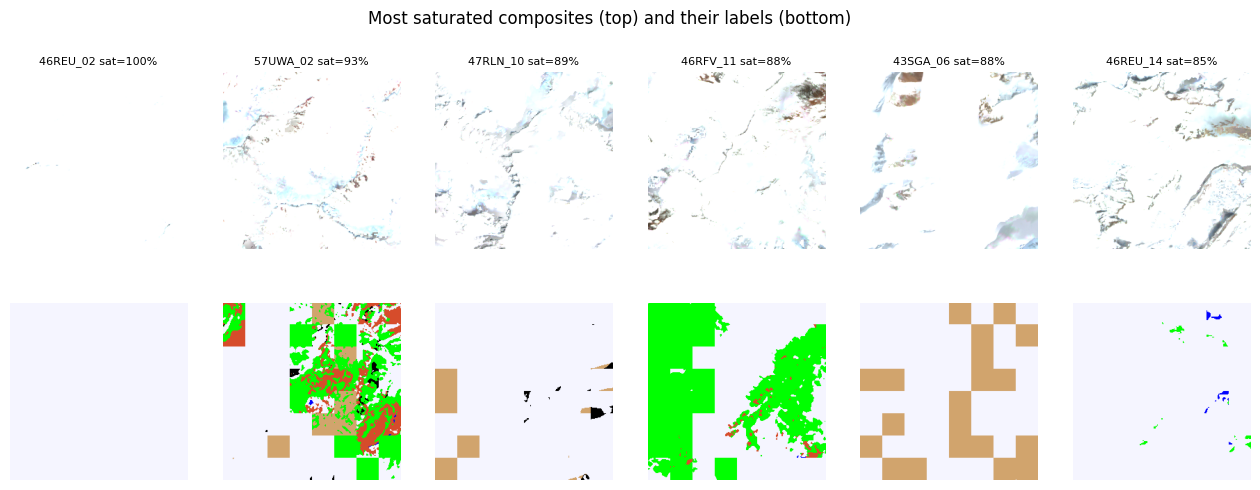

In [9]:
# ------------------------------------------------------------------ diagnostic: how many composites are washed out (saturated)?
import matplotlib.pyplot as plt
from PIL import Image
PAL = {1: (0, 0, 255), 2: (136, 136, 136), 3: (209, 164, 109), 4: (245, 245, 255), 5: (214, 76, 43), 6: (24, 104, 24), 7: (0, 255, 0)}
rows = [(r.id, float((np.asarray(Image.open(r.image_path)) == 255).any(-1).mean())) for r in pairs_df.itertuples()]
d = pd.DataFrame(rows, columns=["id", "sat"]).sort_values("sat", ascending=False)
print(f"chips with >50% saturated pixels: {int((d.sat > .5).sum())} of {len(d)} | mean saturated share: {d.sat.mean():.1%}")
print("tiles with the most saturated chips:"); print(d.assign(tile=d.id.str.split("_").str[0]).groupby("tile").sat.mean().sort_values(ascending=False).head(8).round(3))
if d.sat.mean() > 0.10: print("WARNING: >10% of pixels are saturated: lower COMPOSITE_PCT (e.g. 20), raise DATES_PER_CHIP, or inspect the images below.")
P = pairs_df.set_index("id"); fig, ax = plt.subplots(2, 6, figsize=(16, 5.5))
for j, cid in enumerate(d.id.head(6)):
    m = np.asarray(Image.open(P.loc[cid].mask_path)); o = np.zeros(m.shape + (3,), np.uint8)
    for k, c in PAL.items(): o[m == k] = c
    ax[0, j].imshow(Image.open(P.loc[cid].image_path)); ax[1, j].imshow(o); ax[0, j].set_title(f"{cid} sat={d.set_index('id').sat[cid]:.0%}", fontsize=8); ax[0, j].axis("off"); ax[1, j].axis("off")
plt.suptitle("Most saturated composites (top) and their labels (bottom)"); plt.show()


## 7. Train / validation / test split

In [10]:
# ------------------------------------------------------------------ train / validation / test split (v3: tile-level AND class-stratified)
have = pairs_df.split.notna()
if have.any(): print("Ignoring partial split labels -> making a seeded, class-stratified tile-level split.")
sys.path.insert(0, f"{ROOT}/code"); from io_utils import MODEL_CLASS_NAMES as _CN
pairs_df["tile"] = pairs_df.id.str.split("_").str[0]
n = len(pairs_df); t1, t2 = SPLIT_FRACTIONS[0] * n, (SPLIT_FRACTIONS[0] + SPLIT_FRACTIONS[1]) * n
# per-chip class pixel counts (small 256x256 PNG masks, source ids 0..7) -> per-tile totals
chip_px = np.stack([np.bincount(np.asarray(Image.open(p)).ravel(), minlength=256)[1:8] for p in pairs_df.mask_path]).astype(np.float64)
tile_px = pd.DataFrame(chip_px, index=pairs_df.tile.values).groupby(level=0).sum()
tiles = tile_px.index.values; T_px = tile_px.values; T_n = pairs_df.tile.value_counts().reindex(tiles).values.astype(np.float64)
P_ALL = T_px.sum(0) / T_px.sum()
NAMES = ("train", "validation", "test")

def make_split(seed):                       # greedy fill of train -> validation -> test over a seeded tile permutation (tiles are never split)
    code = np.zeros(len(tiles), int); run = 0
    for i in np.random.RandomState(seed).permutation(len(tiles)):
        code[i] = 0 if run < t1 else (1 if run < t2 else 2); run += T_n[i]
    return code

def split_score(code):                      # relative deviation of val/test class shares from the global shares (rare classes count fully) + chip-share error
    tot = 0.0
    for c, frac in ((1, SPLIT_FRACTIONS[1]), (2, SPLIT_FRACTIONS[2])):
        px = T_px[code == c].sum(0)
        tot += np.abs(px / px.sum() / P_ALL - 1).sum() + 10 * abs(T_n[code == c].sum() / n - frac)
    return tot

SPLIT_SEED = min(range(2000), key=lambda s: split_score(make_split(s)))
code = make_split(SPLIT_SEED); assign = {t: NAMES[c] for t, c in zip(tiles, code)}
pairs_df["split"] = pairs_df.tile.map(assign)
SPLIT_SOURCE = f"class-stratified tile-level split ~{SPLIT_FRACTIONS}, seed {SPLIT_SEED} (best of 2000 candidate tile permutations)"
print("SPLIT SOURCE:", SPLIT_SOURCE); print("chips per split:", pairs_df.split.value_counts().to_dict(), "| tiles per split:", {nm: int((code == k).sum()) for k, nm in enumerate(NAMES)})
share = pd.DataFrame({nm: T_px[code == k].sum(0) / T_px[code == k].sum() for k, nm in enumerate(NAMES)}, index=_CN)
display((share * 100).round(2).rename(columns=lambda c: c + " %"))
for nm in ("validation", "test"):
    r = share[nm] / share["train"]
    if ((r < 0.5) | (r > 2.0)).any(): print(f"WARNING: {nm} class share differs >2x from train for:", list(r.index[(r < 0.5) | (r > 2.0)]))
pd.Series(assign, name="split").rename_axis("tile").to_csv(f"{ROOT}/splits/tile_assignment.csv")
assert (pairs_df.split == "train").sum() >= 40 and (pairs_df.split == "validation").sum() >= 8 and (pairs_df.split == "test").sum() >= 8, \
    "dataset too small for the training setup (need >= 40 train, >= 8 val/test chips: batch 8 x 2 GPUs)"
for name in ("train", "validation", "test"):
    pairs_df[pairs_df.split == name][["id", "image_path", "mask_path", "split"]].to_csv(f"{ROOT}/splits/{name}_manifest.csv", index=False)
print("Saved train/validation/test manifests.")


SPLIT SOURCE: class-stratified tile-level split ~(0.7, 0.15, 0.15), seed 1819 (best of 2000 candidate tile permutations)
chips per split: {'train': 1946, 'validation': 419, 'test': 388} | tiles per split: {'train': 65, 'validation': 14, 'test': 13}


,train %,validation %,test %
Water,4.52,4.35,5.14
Artificial Bare Ground,3.62,3.74,2.89
Natural Bare Ground,21.89,24.85,23.14
Permanent Snow/Ice,1.75,1.90,3.01
Woody Vegetation,23.88,26.16,21.41
Cultivated Vegetation,15.96,15.31,16.63
(Semi) Natural Vegetation,28.38,23.69,27.78


Saved train/validation/test manifests.


In [11]:
# ------------------------------------------------------------------ informational: do val/test chips spatially overlap train chips? (MGRS tiles overlap at their edges)
try:
    from rasterio.warp import transform_bounds
    B = []
    for k in pairs_df.id:
        with rasterio.open(label_choice[k]) as ds: B.append(transform_bounds(ds.crs, "EPSG:4326", *ds.bounds))
    B = np.array(B); spl_ = pairs_df.split.values; trb = B[spl_ == "train"]
    for nm in ("validation", "test"):
        v = B[spl_ == nm]
        ox = np.minimum(v[:, None, 2], trb[None, :, 2]) - np.maximum(v[:, None, 0], trb[None, :, 0])
        oy = np.minimum(v[:, None, 3], trb[None, :, 3]) - np.maximum(v[:, None, 1], trb[None, :, 1])
        n_ov = int(((ox > 0) & (oy > 0)).any(1).sum())
        print(f"{nm}: {n_ov} of {len(v)} chips overlap a train chip" + ("   <-- WARNING: leakage; consider dropping them from the manifest" if n_ov > 0.02 * len(v) else ""))
except Exception as e:
    print("overlap check skipped (non-essential):", repr(e)[:200])


validation: 0 of 419 chips overlap a train chip
test: 0 of 388 chips overlap a train chip


## 8. Integrity scan, class statistics, normalisation statistics, encodings

scanning:   0%|          | 0/2753 [00:00<?, ?it/s]

corrupt/unreadable pairs: 0


,id,image_path,mask_path,split,tile,ok,err,img_h,img_w,img_c,...,shape_ok,m0,m1,m2,m3,m4,m5,m6,m7,m_other


image size distribution: {(256, 256): 2753} | dtype: ['uint8'] | channels: [3]
chips whose mask has ONLY no-data (0): 0 | chips with mask values outside 0..7 (treated as ignored): 0
constant image size: True


,class,train_pixels,proportion,chips_with_class
0,Water,5764194.0,0.045209,666
1,Artificial Bare Ground,4621746.0,0.036249,970
2,Natural Bare Ground,27904993.0,0.218863,732
3,Permanent Snow/Ice,2232508.0,0.017510,556
4,Woody Vegetation,30442086.0,0.238762,1271
5,Cultivated Vegetation,20351584.0,0.159620,1020
6,(Semi) Natural Vegetation,36182816.0,0.283787,1629


ignored (no-data) share of all train pixels: 0.026%


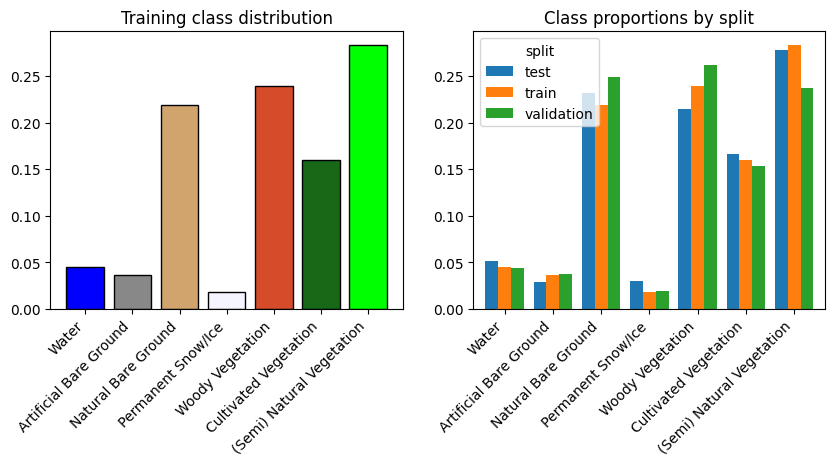

normalisation:   0%|          | 0/1946 [00:00<?, ?it/s]

train mean/std: [0.4759 0.3013 0.278 ] [0.1813 0.2161 0.2089]


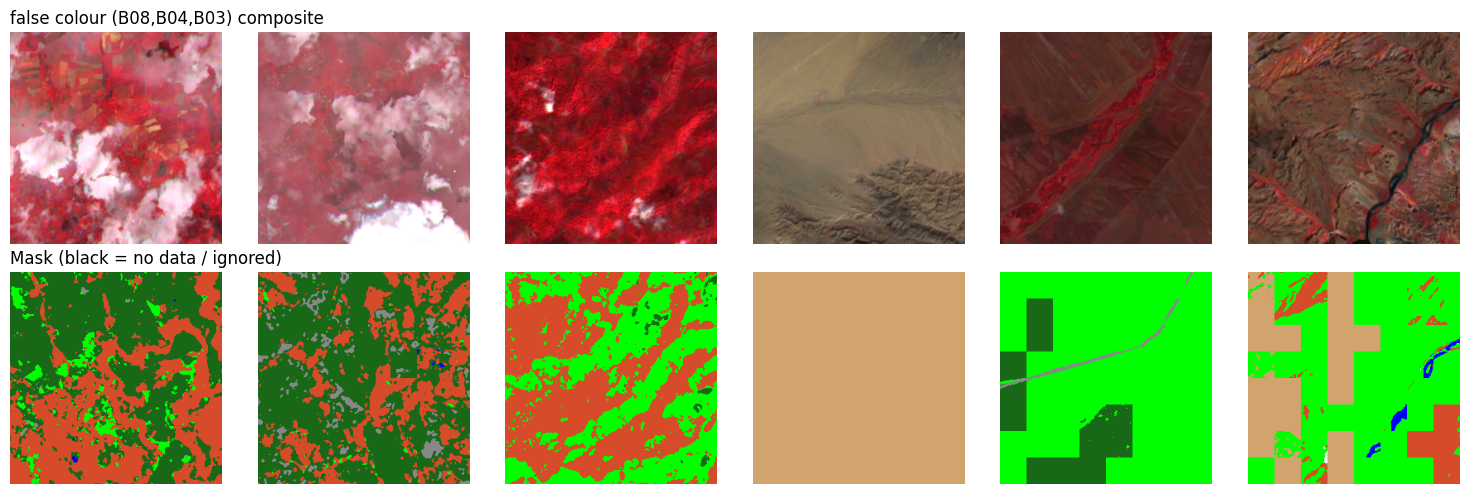

{
 "layout": "stac",
 "split_source": "class-stratified tile-level split ~(0.7, 0.15, 0.15), seed 1819 (best of 2000 candidate tile permutations)",
 "clean_pairs": {
  "test": 388,
  "train": 1946,
  "validation": 419
 },
 "image_sizes": {
  "256x256": 2753
 }
}

DATA PREPARATION COMPLETE.


In [12]:
import matplotlib.pyplot as plt
sys.path.insert(0, f"{ROOT}/code")
from io_utils import *            # NUM_CLASSES, CLASS_NAMES_SRC, MODEL_CLASS_NAMES, read_image, read_mask_raw, decode_mask, ...

#CLASS_COLORS = {1: (0, 112, 192), 2: (210, 180, 140), 3: (128, 128, 128), 4: (0, 100, 0), 5: (154, 205, 50), 6: (144, 238, 144), 7: (200, 235, 255)}

CLASS_COLORS = {
    1: (0, 0, 255),       # Water
    2: (136, 136, 136),   # Artificial Bare Ground
    3: (209, 164, 109),   # Natural Bare Ground
    4: (245, 245, 255),   # Permanent Snow/Ice
    5: (214, 76, 43),     # Woody Vegetation
    6: (24, 104, 24),    # Cultivated Vegetation
    7: (0, 255, 0)       # (Semi) Natural Vegetation
}

trm = pd.read_csv(f"{ROOT}/splits/train_manifest.csv")

# ------------------------------------------------------------------ encodings (same JSON files the training code reads)
MASK_ENC = {"type": "indexed"}
for _, r in pd.concat([pairs_df.sample(min(60, len(pairs_df)), random_state=SEED)]).iterrows():
    a = read_mask_raw(r.mask_path)
    if a.ndim == 3:
        assert np.array_equal(a[..., 0], a[..., 1]), "RGB colour masks are not supported here (expected index masks with values 0..7)."
    im = read_image(r.image_path)
    assert im.dtype == np.uint8 and im.ndim == 3 and im.shape[2] == 3, f"expected uint8 RGB images, got {im.dtype} {im.shape}"
IMAGE_SCALE_MAX = 255.0
json.dump(MASK_ENC, open(f"{ROOT}/preprocessing/mask_encoding.json", "w"), indent=2)
json.dump({"scale_max": IMAGE_SCALE_MAX, "channels": f"{COMP_DESC}, per-pixel {COMPOSITE_PCT}th-percentile over the dates, reflectance stretched 0..{REFL_MAX:.2f} -> 0..255",
           "refl_max": REFL_MAX, "input_channels": 3}, open(f"{ROOT}/preprocessing/image_encoding.json", "w"), indent=2)
LABEL_MAPPING = {"source_classes": {str(k): v for k, v in CLASS_NAMES_SRC.items()}, "source_unclassified": 0,
                 "source_to_model": {"0": 255, **{str(s): s - 1 for s in range(1, 8)}}, "model_to_source": {str(k): k + 1 for k in range(7)},
                 "ignore_index_model": 255, "model_class_names": MODEL_CLASS_NAMES}
json.dump(LABEL_MAPPING, open(f"{ROOT}/preprocessing/label_mapping.json", "w"), indent=2)
json.dump({str(i): list(c) for i, c in CLASS_COLORS.items()}, open(f"{ROOT}/preprocessing/class_colors.json", "w"), indent=2)

# ------------------------------------------------------------------ full scan: integrity, shapes, per-image class pixel counts
from multiprocessing import Pool
def scan_one(a):
    i, ip, mp = a; r = {"i": i, "ok": True, "err": ""}
    try:
        im = read_image(ip); src = decode_mask(read_mask_raw(mp), MASK_ENC)
        r.update(img_h=im.shape[0], img_w=im.shape[1], img_c=im.shape[2], img_dtype=str(im.dtype), shape_ok=im.shape[:2] == src.shape[:2])
        cnt = np.bincount(src.ravel(), minlength=256)
        for k in range(8): r[f"m{k}"] = int(cnt[k])
        r["m_other"] = int(cnt[8:].sum())
    except Exception as e:
        r.update(ok=False, err=repr(e)[:200])
    return r
work = pairs_df.reset_index(drop=True)
with Pool(min(4, os.cpu_count() or 2)) as p:
    res = list(tqdm(p.imap(scan_one, [(i, r.image_path, r.mask_path) for i, r in work.iterrows()], chunksize=32), total=len(work), desc="scanning"))
inv = work.join(pd.DataFrame(res).set_index("i")); inv.to_csv(f"{ROOT}/dataset_analysis/dataset_inventory.csv", index=False)
bad = inv[~inv.ok]; print("corrupt/unreadable pairs:", len(bad)); display(bad.head())
good = inv[inv.ok & inv.shape_ok.astype(bool)].copy()
print("image size distribution:", good.groupby(["img_h", "img_w"]).size().to_dict(), "| dtype:", good.img_dtype.unique(), "| channels:", good.img_c.unique())
print("chips whose mask has ONLY no-data (0):", int((good[[f"m{k}" for k in range(1, 8)]].sum(axis=1) == 0).sum()),
      "| chips with mask values outside 0..7 (treated as ignored):", int((good.m_other > 0).sum()))
CONST_SIZE = good[["img_h", "img_w"]].drop_duplicates().shape[0] == 1
print("constant image size:", CONST_SIZE)
assert len(good) > 0.95 * len(inv), "too many unreadable / shape-mismatched pairs"

# ------------------------------------------------------------------ class statistics (training split) and label sanity check
cols = [f"m{k}" for k in range(8)]
split_counts = good.groupby("split")[cols].sum(); split_counts.to_csv(f"{ROOT}/dataset_analysis/class_pixels_per_split.csv")
tr = good[good.split == "train"]
px_src = tr[[f"m{k}" for k in range(1, 8)]].sum().values.astype(np.float64); ign = int(tr.m0.sum()); valid = px_src.sum(); beta = 0.9999
stats = {"train_pixels_model_order": px_src.tolist(), "class_names_model_order": MODEL_CLASS_NAMES, "train_ignored_unclassified_pixels": ign,
         "train_ignored_fraction": ign / (ign + valid), "train_class_proportion": (px_src / valid).tolist(),
         "effective_number_beta": beta, "effective_number": ((1 - beta ** px_src) / (1 - beta)).tolist(),
         "image_level_occurrence": {MODEL_CLASS_NAMES[k]: int((tr[f"m{k+1}"] > 0).sum()) for k in range(7)}, "n_train_images": int(len(tr))}
json.dump(stats, open(f"{ROOT}/dataset_analysis/class_stats.json", "w"), indent=2)
tab = pd.DataFrame({"class": MODEL_CLASS_NAMES, "train_pixels": px_src, "proportion": px_src / valid, "chips_with_class": list(stats["image_level_occurrence"].values())})
display(tab); print(f"ignored (no-data) share of all train pixels: {stats['train_ignored_fraction']:.3%}")
if (px_src == 0).any(): print("NOTE: class(es) absent from the training split:", [MODEL_CLASS_NAMES[i] for i in np.where(px_src == 0)[0]], "(their IoU will be NaN and excluded from the mean)")
if stats["train_ignored_fraction"] > 0.5: print("WARNING: >50% of train pixels are class 0. If your copy stores classes as 0..6, set LABELS_ZERO_BASED=True in the 'locate' cell and re-run from there.")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(MODEL_CLASS_NAMES, px_src / valid, color=[tuple(c / 255 for c in CLASS_COLORS[i]) for i in range(1, 8)], edgecolor="k"); ax[0].set_title("Training class distribution")
plt.setp(ax[0].get_xticklabels(), rotation=45, ha="right")
prop = split_counts[[f"m{k}" for k in range(1, 8)]]; prop = prop.div(prop.sum(axis=1), axis=0)
prop.T.plot.bar(ax=ax[1], width=.8); ax[1].set_xticklabels(MODEL_CLASS_NAMES, rotation=45, ha="right"); ax[1].set_title("Class proportions by split")
fig.savefig(f"{ROOT}/dataset_analysis/class_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

# ------------------------------------------------------------------ training-split normalisation statistics (ImageNet stats are what the model uses)
def norm_one(p):
    a = read_image(p).astype(np.float64) / IMAGE_SCALE_MAX; return a.sum((0, 1)), (a ** 2).sum((0, 1)), a.shape[0] * a.shape[1]
with Pool(min(4, os.cpu_count() or 2)) as p: out = list(tqdm(p.imap(norm_one, tr.image_path.tolist(), chunksize=32), total=len(tr), desc="normalisation"))
s1 = sum(o[0] for o in out); s2 = sum(o[1] for o in out); n_px = sum(o[2] for o in out); mean = s1 / n_px; std = np.sqrt(s2 / n_px - mean ** 2)
NORM = {"computed_on": "training split only", "n_images_used": len(tr), "n_pixels": int(n_px), "scale_max": IMAGE_SCALE_MAX, "channel_order": [f"ch{i+1}=B0{b}" for i, b in enumerate(COMP_BANDS)],
        "train_mean": mean.tolist(), "train_std": std.tolist(), "imagenet_mean": [0.485, 0.456, 0.406], "imagenet_std": [0.229, 0.224, 0.225]}
json.dump(NORM, open(f"{ROOT}/preprocessing/normalization_stats.json", "w"), indent=2); print("train mean/std:", np.round(mean, 4), np.round(std, 4))

# ------------------------------------------------------------------ sample pairs + summary
def colour_src(src):
    o = np.zeros(src.shape + (3,), np.uint8)
    for k in range(1, 8): o[src == k] = CLASS_COLORS[k]
    return o
sm = tr.sample(6, random_state=SEED); fig, ax = plt.subplots(2, 6, figsize=(15, 5))
for j, (_, r) in enumerate(sm.iterrows()):
    ax[0, j].imshow(read_image(r.image_path)); ax[1, j].imshow(colour_src(decode_mask(read_mask_raw(r.mask_path), MASK_ENC))); ax[0, j].axis("off"); ax[1, j].axis("off")
ax[0, 0].set_title(f"{COMP_DESC} composite", loc="left"); ax[1, 0].set_title("Mask (black = no data / ignored)", loc="left"); plt.tight_layout()
fig.savefig(f"{ROOT}/dataset_analysis/sample_pairs.png", dpi=120); plt.show()
summary = {"dataset": "LandCoverNet Asia", "data_dir": DATA_DIR, "layout": LAYOUT, "split_source": SPLIT_SOURCE, "clean_pairs": good.groupby("split").size().to_dict(),
           "image_sizes": {f"{h}x{w}": int(c) for (h, w), c in good.groupby(["img_h", "img_w"]).size().items()}, "refl_max": REFL_MAX,
           "labels_zero_based": LABELS_ZERO_BASED, "input_channels": 3, "ignored_source_label": 0, "run_started": RUN_STARTED}
json.dump(summary, open(f"{ROOT}/dataset_analysis/dataset_summary.json", "w"), indent=2, default=str)
print(json.dumps({k: summary[k] for k in ("layout", "split_source", "clean_pairs", "image_sizes")}, indent=1)); print("\nDATA PREPARATION COMPLETE.")


# PART 2 - Model, genuine 2-GPU DDP training, evaluation (v3: regularisation fixes)

## 9. Experiment configuration
v3 settings (**starting points, not tuned optima**): SAM 2.1 Hiera-B+ encoder (patch-embed + stages 1-2 frozen) + semantic head, `ce_dice` with sqrt-inverse class weights, AdamW lr 2e-4 (encoder x0.05 with layer-wise decay), 3-epoch warm-up + cosine over 60 epochs, `rs_strong` augmentation, ImageNet normalisation, AMP, EMA 0.998, batch 8 per GPU x 2 GPUs (effective 16), early-stopping patience 15 on EMA val mIoU, 9 h wall-clock guard.

In [13]:
CFG = dict(
    model="sam2_semantic", encoder="hiera_bplus", pretrained=True,      # official SAM 2.1 Hiera-B+ encoder weights; False = random init
    segformer_checkpoint="nvidia/mit-b0",                               # unused here (kept for helper compatibility)
    sam_ckpt=SAM_CKPT, sam_input_size=256,                              # SAM 2.1 checkpoint (downloaded in Section 2); chips are resized to this size inside the model, logits returned at native size
    enc_lr_mult=0.05, freeze_encoder=False, freeze_blocks=5,            # v3: encoder LR = lr*0.05 (x layer-wise decay); freeze patch_embed + Hiera stages 1-2 (blocks 0-4). 21 = only last stage + neck train; freeze_encoder=True = fully frozen
    input_channels=3, num_classes=7, input_size=None,                   # None = native resolution (256x256 chips)
    epochs=150, patience=50, monitor="val_miou", seed=42,                  # v3: was 150 / 50 (val plateaued at ~epoch 20-30)
    optimizer="adamw", lr=2e-4, weight_decay=0.05, min_lr=1e-6,
    scheduler="warmup_cosine", warmup_epochs=3, plateau_patience=10,
    loss="ce_dice", focal_gamma=2.0, class_weighting="sqrt", custom_class_weights=None,   # v3: "sqrt" (was "median", ~17x spread). "none"/"median" = ablations
    drop_path=0.2, head_drop=0.3,                                        # v3: encoder stochastic depth / head dropout (were 0.1 / 0.2)
    label_smoothing=0.1, ema_decay=0.998,                                # v3: EMA weights are evaluated AND saved (~4-epoch horizon at 121 steps/epoch)
    clean_eval_every=5, clean_eval_samples=500,                          # v3: every 5 epochs, mIoU on 500 un-augmented TRAIN chips (true train/val gap)
    augmentation="rs_strong", normalization="imagenet",   # SAM 2 expects ImageNet mean/std

    batch_size=8, eval_batch_size=32, grad_accum=1, grad_clip=1.0,    # batch_size is PER GPU; effective = batch x GPUs x accum
    amp=True, num_workers=2, prefetch=2, sync_bn=False, find_unused_parameters=False, cudnn_benchmark=True,
    time_limit_hours=9.0,                                               # graceful stop well before Kaggle's 12 h limit
    resume=None, max_train_samples=None, max_eval_samples=None,        # sub-sampling ONLY for smoke tests
    nproc=min(2, N_GPUS),                                               # processes = GPUs (2 on T4 x2). 1 => single-GPU fallback
    nccl_p2p_disable=False,                                             # set True if NCCL hangs at start-up on your T4 pair
)
json.dump(CFG, open(f"{ROOT}/reproducibility/default_config.json", "w"), indent=2)
print(json.dumps(CFG, indent=1))


{
 "model": "sam2_semantic",
 "encoder": "hiera_bplus",
 "pretrained": true,
 "segformer_checkpoint": "nvidia/mit-b0",
 "sam_ckpt": "/kaggle/temp/sam_ckpt/sam2.1_hiera_base_plus.pt",
 "sam_input_size": 256,
 "enc_lr_mult": 0.05,
 "freeze_encoder": false,
 "freeze_blocks": 5,
 "input_channels": 3,
 "num_classes": 7,
 "input_size": null,
 "epochs": 150,
 "patience": 50,
 "monitor": "val_miou",
 "seed": 42,
 "optimizer": "adamw",
 "lr": 0.0002,
 "weight_decay": 0.05,
 "min_lr": 1e-06,
 "scheduler": "warmup_cosine",
 "warmup_epochs": 3,
 "plateau_patience": 10,
 "loss": "ce_dice",
 "focal_gamma": 2.0,
 "class_weighting": "sqrt",
 "custom_class_weights": null,
 "drop_path": 0.2,
 "head_drop": 0.3,
 "label_smoothing": 0.1,
 "ema_decay": 0.998,
 "clean_eval_every": 5,
 "clean_eval_samples": 500,
 "augmentation": "rs_strong",
 "normalization": "imagenet",
 "batch_size": 8,
 "eval_batch_size": 32,
 "grad_accum": 1,
 "grad_clip": 1.0,
 "amp": true,
 "num_workers": 2,
 "prefetch": 2,
 "sync_bn": 

## 10. Companion modules written to `/kaggle/working/lulc_research/code/`
`common.py` (dataset/augmentation, losses, metrics, plots) · `train.py` (DDP trainer/evaluator) · `sam_models.py` (SAM 2.1 Hiera encoder + semantic head) · `smoke_test.py`.

In [14]:
%%writefile /kaggle/working/lulc_research/code/common.py
"""common.py -- dataset, models, losses, metrics, plotting for LandCoverNet Asia segmentation."""
import os, sys, json, time, math, random, platform
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from io_utils import (NUM_CLASSES, IGNORE_INDEX, CLASS_NAMES_SRC, MODEL_CLASS_NAMES, LUT_SRC2MODEL,
                      SRC_FROM_MODEL, read_image, read_mask_raw, decode_mask)

ROOT = os.environ.get("LULC_ROOT", "/kaggle/working/lulc_research")
# One fixed palette used in EVERY figure (source id -> RGB). Saved to preprocessing/class_colors.json by Part 2.
#CLASS_COLORS_SRC = {1: (0, 112, 192), 2: (210, 180, 140), 3: (128, 128, 128), 4: (0, 100, 0), 5: (154, 205, 50), 6: (144, 238, 144), 7: (200, 235, 255)}
CLASS_COLORS_SRC = {1: (0, 0, 255), 2: (136, 136, 136), 3: (209, 164, 109), 4: (245, 245, 255), 5: (214, 76, 43), 6: (24, 104, 24), 7: (0, 255, 0)}
MODEL_COLORS = np.array([CLASS_COLORS_SRC[i] for i in range(1, 8)], dtype=np.uint8)
IGNORE_COLOR = (0, 0, 0)


def load_json(p):
    with open(p) as f:
        return json.load(f)


def save_json(obj, p):
    with open(p, "w") as f:
        json.dump(obj, f, indent=2, default=str)


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def colorize(mask_model):
    """model-id mask (255=ignore) -> HxWx3 uint8 using the shared palette."""
    out = np.zeros(mask_model.shape + (3,), np.uint8)
    out[:] = IGNORE_COLOR
    for k in range(NUM_CLASSES):
        out[mask_model == k] = MODEL_COLORS[k]
    return out


# ----------------------------------------------------------------------------- dataset

AUG_LEVELS = {
    "none":     dict(flip=False, rot=False, bc=0.0,  gain=0.0,  noise=0.0,  blur=0.0, crop=1.0, offset=0.0,  gamma=0.0),
    "light":    dict(flip=True,  rot=False, bc=0.0,  gain=0.0,  noise=0.0,  blur=0.0, crop=1.0, offset=0.0,  gamma=0.0),
    "moderate": dict(flip=True,  rot=True,  bc=0.10, gain=0.0,  noise=0.0,  blur=0.0, crop=1.0, offset=0.0,  gamma=0.0),
    "strong":   dict(flip=True,  rot=True,  bc=0.20, gain=0.05, noise=0.01, blur=0.2, crop=1.0, offset=0.0,  gamma=0.0),
    # new: scale/crop jitter + per-channel radiometric jitter (simulates tile-to-tile atmosphere/season shifts)
    "rs_strong": dict(flip=True, rot=True,  bc=0.20, gain=0.15, noise=0.02, blur=0.2, crop=0.6, offset=0.04, gamma=0.25),
}


class LULCDataset(Dataset):
    """Reads (image, mask) pairs from a manifest CSV (columns: id,image_path,mask_path,split).
    Image: RGB scaled to [0,1] by image_encoding.scale_max, then normalised.  Mask: source ids -> model ids (255 ignore).
    Geometric augmentation is applied identically to image and mask; masks are only ever resized with nearest-neighbour."""

    def __init__(self, manifest_csv, cfg, train=False, max_samples=None):
        self.df = pd.read_csv(manifest_csv)
        if max_samples:
            self.df = self.df.sample(n=min(max_samples, len(self.df)), random_state=cfg["seed"]).sort_index().reset_index(drop=True)
        self.ip = self.df["image_path"].tolist(); self.mp = self.df["mask_path"].tolist()
        pre = f"{ROOT}/preprocessing"
        self.enc = load_json(f"{pre}/mask_encoding.json")
        self.scale = float(load_json(f"{pre}/image_encoding.json")["scale_max"])
        nm = cfg["normalization"]
        stats = load_json(f"{ROOT}/preprocessing/normalization_stats.json")
        if nm == "train":
            self.mean, self.std = np.array(stats["train_mean"], np.float32), np.array(stats["train_std"], np.float32)
        elif nm == "imagenet":
            self.mean, self.std = np.array(stats["imagenet_mean"], np.float32), np.array(stats["imagenet_std"], np.float32)
        elif nm == "unit":
            self.mean, self.std = np.zeros(3, np.float32), np.ones(3, np.float32)
        else:
            raise ValueError(nm)
        self.train = train
        self.aug = AUG_LEVELS[cfg["augmentation"]] if train else AUG_LEVELS["none"]
        self.input_size = cfg.get("input_size")  # None = native resolution

    def __len__(self):
        return len(self.ip)

    def _resize(self, img, msk):
        import cv2
        s = self.input_size
        if s and (img.shape[0] != s or img.shape[1] != s):
            img = cv2.resize(img, (s, s), interpolation=cv2.INTER_LINEAR)
            msk = cv2.resize(msk, (s, s), interpolation=cv2.INTER_NEAREST)   # nearest: never creates new class ids
        return img, msk

    def __getitem__(self, i):
        import cv2
        img = read_image(self.ip[i]).astype(np.float32) / self.scale
        msk = LUT_SRC2MODEL[decode_mask(read_mask_raw(self.mp[i]), self.enc)]
        if img.shape[:2] != msk.shape[:2]:
            raise ValueError(f"image/mask shape mismatch: {self.ip[i]} {img.shape} vs {msk.shape}")
        img, msk = self._resize(img, msk)
        a = self.aug
        if self.train:
            # --- geometric (identical for image and mask)
            if a["flip"]:
                if random.random() < 0.5: img, msk = img[:, ::-1], msk[:, ::-1]
                if random.random() < 0.5: img, msk = img[::-1], msk[::-1]
            if a["rot"]:
                k = random.choice([0, 1, 2, 3] if img.shape[0] == img.shape[1] else [0, 2])
                if k: img, msk = np.rot90(img, k), np.rot90(msk, k)
            if a["crop"] < 1.0 and random.random() < 0.7:          # random resized crop (zoom in up to 1/crop x)
                H, W = msk.shape
                s = random.uniform(a["crop"], 1.0)
                ch, cw = max(32, int(H * s)), max(32, int(W * s))
                y0, x0 = random.randint(0, H - ch), random.randint(0, W - cw)
                img = cv2.resize(np.ascontiguousarray(img[y0:y0 + ch, x0:x0 + cw]), (W, H), interpolation=cv2.INTER_LINEAR)
                msk = cv2.resize(np.ascontiguousarray(msk[y0:y0 + ch, x0:x0 + cw]), (W, H), interpolation=cv2.INTER_NEAREST)
            # --- radiometric (image only)
            if a["bc"] > 0 and random.random() < 0.8:
                c = 1 + random.uniform(-a["bc"], a["bc"]); b = random.uniform(-a["bc"], a["bc"]) * 0.5
                img = (img - 0.5) * c + 0.5 + b
            if a["gain"] > 0 and random.random() < 0.8:             # per-channel gain
                img = img * (1 + np.random.uniform(-a["gain"], a["gain"], size=(1, 1, 3))).astype(np.float32)
            if a["offset"] > 0 and random.random() < 0.5:           # per-channel additive offset (haze-like)
                img = img + np.random.uniform(-a["offset"], a["offset"], size=(1, 1, 3)).astype(np.float32)
            if a["gamma"] > 0 and random.random() < 0.5:            # per-channel gamma
                g = np.exp(np.random.uniform(-a["gamma"], a["gamma"], size=(1, 1, 3))).astype(np.float32)
                img = np.clip(img, 0.0, 1.0) ** g
            if a["blur"] > 0 and random.random() < a["blur"]:
                img = cv2.GaussianBlur(np.ascontiguousarray(img, dtype=np.float32), (3, 3), 0)
            if a["noise"] > 0:
                img = img + np.random.normal(0, a["noise"], img.shape).astype(np.float32)
            img = np.clip(img, 0.0, 1.0).astype(np.float32)
        img = (img - self.mean) / self.std
        x = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1), dtype=np.float32))
        y = torch.from_numpy(np.ascontiguousarray(msk).astype(np.int64))
        return x, y, i


class ShardSampler(torch.utils.data.Sampler):
    """Evaluation sampler: rank r takes indices r, r+W, r+2W, ... with NO padding/duplication
    (DistributedSampler pads with repeats, which would double-count samples in the confusion matrix)."""
    def __init__(self, n, rank, world):
        self.idx = list(range(rank, n, world))
    def __iter__(self):
        return iter(self.idx)
    def __len__(self):
        return len(self.idx)


# ----------------------------------------------------------------------------- models
class SegWrapper(nn.Module):
    """Uniform interface: [B,3,H,W] -> [B,7,H,W]. Reflect-pads to a multiple of `multiple`, crops back, and
    bilinearly resizes logits (differentiable) if the net outputs a lower resolution."""
    def __init__(self, net, kind, multiple=32):
        super().__init__(); self.net, self.kind, self.m = net, kind, multiple

    def forward(self, x):
        H, W = x.shape[-2:]
        ph, pw = (-H) % self.m, (-W) % self.m
        if ph or pw:
            x = F.pad(x, (0, pw, 0, ph), mode="reflect")
        out = self.net(pixel_values=x) if self.kind == "segformer" else self.net(x)
        out = out.logits if hasattr(out, "logits") else out
        if out.shape[-2:] != x.shape[-2:]:
            out = F.interpolate(out, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return out[..., :H, :W]


def _smp(arch, cfg, pretrained):
    import segmentation_models_pytorch as smp
    cls = {"unet": smp.Unet, "unetplusplus": smp.UnetPlusPlus, "deeplabv3plus": smp.DeepLabV3Plus}[arch]
    w = "imagenet" if pretrained else None
    net = cls(encoder_name=cfg["encoder"], encoder_weights=w, in_channels=3, classes=NUM_CLASSES)
    expected = {"unet": "Unet", "unetplusplus": "UnetPlusPlus", "deeplabv3plus": "DeepLabV3Plus"}[arch]
    assert type(net).__name__ == expected, f"expected {expected}, got {type(net).__name__}"
    return net


def build_model(cfg, pretrained=None):
    """Registry. Heavy imports happen only for the selected model. Raises (never substitutes) for unimplemented ones."""
    name = cfg["model"]
    pre = cfg["pretrained"] if pretrained is None else pretrained
    meta = {"model": name, "pretrained_requested": bool(pre)}
    if name in ("unet", "unetplusplus", "deeplabv3plus"):
        net = _smp(name, cfg, pre)
        meta["source"] = "segmentation_models_pytorch " + __import__("segmentation_models_pytorch").__version__
        meta["pretrained_provenance"] = f"smp encoder weights 'imagenet' for {cfg['encoder']}" if pre else "random init"
        if name == "deeplabv3plus":
            mods = [n.lower() for n, _ in net.named_modules()]
            meta["has_aspp"] = any("aspp" in m for m in mods)
            assert meta["has_aspp"], "DeepLabV3+ decoder without ASPP?"
        model = SegWrapper(net, "smp", 32)
    elif name == "segformer":
        from transformers import SegformerForSemanticSegmentation, SegformerConfig
        id2label = {i: n for i, n in enumerate(MODEL_CLASS_NAMES)}
        if pre:
            net = SegformerForSemanticSegmentation.from_pretrained(
                cfg["segformer_checkpoint"], num_labels=NUM_CLASSES, id2label=id2label,
                label2id={v: k for k, v in id2label.items()}, ignore_mismatched_sizes=True)
            meta["pretrained_provenance"] = f"HF hub '{cfg['segformer_checkpoint']}' (encoder; classifier re-initialised for 7 classes)"
        else:
            c = SegformerConfig.from_pretrained(cfg["segformer_checkpoint"], num_labels=NUM_CLASSES)
            net = SegformerForSemanticSegmentation(c); meta["pretrained_provenance"] = "random init"
        import transformers; meta["source"] = "transformers " + transformers.__version__
        model = SegWrapper(net, "segformer", 32)
    elif name == "sam2_semantic":
        # Official SAM 2.1 Hiera image encoder (facebookresearch/sam2) + light semantic head (sam_models.py)
        from sam_models import build_sam2_semantic
        net, extra = build_sam2_semantic(cfg, pre)
        meta.update(extra)
        model = SegWrapper(net, "sam2", 1)     # multiple=1: no padding; the net resizes internally and returns native-size logits
    elif name in ("rs3mamba", "samba", "sam_rs", "sasam"):
        raise NotImplementedError(f"'{name}' is implemented in Part 4 (requires inspecting the official repository and "
                                  f"verifying mamba_ssm/CUDA compatibility). It is deliberately NOT replaced by another model.")
    else:
        raise ValueError(f"unknown model '{name}'")
    meta["params_total"] = sum(p.numel() for p in model.parameters())
    meta["params_trainable"] = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return model, meta

class ModelEMA:
    """Exponential moving average of weights; evaluate/export with .module."""
    def __init__(self, model, decay=0.998):
        import copy
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters(): p.requires_grad_(False)
        self.decay, self.n = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))      # warm-up so early steps aren't dominated by init weights
        msd = model.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point: v.mul_(d).add_(msd[k].detach(), alpha=1 - d)
            else: v.copy_(msd[k])
# ----------------------------------------------------------------------------- losses
class SegLoss(nn.Module):
    """ce | wce | dice | ce_dice | focal | focal_dice.   'wce' = CE with class weights.
    Dice: soft dice computed over the batch, averaged over classes PRESENT in the batch ground truth; ignore pixels excluded.
    Lovasz-Softmax is intentionally not offered (not implemented here)."""
    def __init__(self, name, weights=None, gamma=2.0, label_smoothing=0.0):
        super().__init__()
        self.name, self.gamma, self.ls = name, gamma, label_smoothing
        self.register_buffer("w", None if weights is None else torch.as_tensor(weights, dtype=torch.float32))
        assert name in ("ce", "wce", "dice", "ce_dice", "focal", "focal_dice"), name
        if name == "wce": assert weights is not None, "wce needs class weights"

    def dice(self, logits, y):
        valid = (y != IGNORE_INDEX)
        t = y.clone(); t[~valid] = 0
        p = logits.softmax(1) * valid.unsqueeze(1)
        oh = F.one_hot(t, NUM_CLASSES).permute(0, 3, 1, 2).float() * valid.unsqueeze(1)
        inter = (p * oh).sum((0, 2, 3)); card = (p + oh).sum((0, 2, 3)); present = oh.sum((0, 2, 3)) > 0
        d = 1 - (2 * inter + 1e-6) / (card + 1e-6)
        return d[present].mean() if present.any() else logits.sum() * 0

    def focal(self, logits, y):
        ce = F.cross_entropy(logits, y, weight=self.w, ignore_index=IGNORE_INDEX, reduction="none")
        valid = (y != IGNORE_INDEX)
        pt = torch.exp(-F.cross_entropy(logits, y, ignore_index=IGNORE_INDEX, reduction="none"))
        f = ((1 - pt) ** self.gamma) * ce
        return f[valid].sum() / valid.sum().clamp(min=1)

    def forward(self, logits, y):
        logits = logits.float(); n = self.name
        if n in ("ce", "wce"): return F.cross_entropy(logits, y, weight=self.w, ignore_index=IGNORE_INDEX, label_smoothing=self.ls)
        if n == "dice": return self.dice(logits, y)
        if n == "ce_dice": return F.cross_entropy(logits, y, weight=self.w, ignore_index=IGNORE_INDEX, label_smoothing=self.ls) + self.dice(logits, y)
        if n == "focal": return self.focal(logits, y)
        return self.focal(logits, y) + self.dice(logits, y)


def class_weights(mode, stats_json, custom=None, beta=0.9999):
    """Weights in MODEL class order (mean-normalised to 1). Treated as an experimental factor, not a default."""
    if mode in (None, "none"): return None
    if mode == "custom": return np.array(custom, np.float32)
    px = np.array(load_json(stats_json)["train_pixels_model_order"], np.float64)
    if mode == "inverse": w = 1.0 / px
    elif mode == "median": f = px / px.sum(); w = np.median(f) / f
    elif mode == "effective": w = (1 - beta) / (1 - beta ** px)      # NOTE: ~uniform here (beta**px = 0 for px >= 1e6)
    elif mode == "sqrt": w = 1.0 / np.sqrt(px / px.sum())            # v3: milder than "median" (~4x instead of ~17x spread)
    else: raise ValueError(mode)
    return (w / w.mean()).astype(np.float32)


# ----------------------------------------------------------------------------- metrics (global confusion matrix)
def confusion_from(pred, target):
    """rows = ground truth, cols = prediction; ignore pixels dropped."""
    v = target != IGNORE_INDEX
    idx = target[v] * NUM_CLASSES + pred[v]
    return torch.bincount(idx, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)


def per_image_stats(pred, target):
    """Per-image OA / mIoU / macro-F1 from per-image confusion matrices (classes with GT+pred pixels==0 are skipped)."""
    B = pred.shape[0]; C = NUM_CLASSES
    v = target != IGNORE_INDEX
    off = torch.arange(B, device=pred.device).view(B, 1, 1) * C * C
    idx = (off + target * C + pred)[v]
    cm = torch.bincount(idx, minlength=B * C * C).reshape(B, C, C).double()
    tp = torch.diagonal(cm, dim1=1, dim2=2); gt = cm.sum(2); pr = cm.sum(1); un = gt + pr - tp
    iou = torch.where(un > 0, tp / un.clamp(min=1), torch.full_like(tp, float("nan")))
    f1d = gt + pr
    f1 = torch.where(f1d > 0, 2 * tp / f1d.clamp(min=1), torch.full_like(tp, float("nan")))
    tot = cm.sum((1, 2))
    acc = torch.where(tot > 0, tp.sum(1) / tot.clamp(min=1), torch.full_like(tot, float("nan")))
    return (torch.nanmean(iou, 1).cpu().numpy(), torch.nanmean(f1, 1).cpu().numpy(),
            acc.cpu().numpy(), tot.cpu().numpy())


def metrics_from_cm(cm):
    """All metrics from the *aggregate* confusion matrix. Conventions: a class's IoU/F1 is NaN if it has neither GT nor
    predicted pixels; precision NaN if never predicted; recall NaN if absent from GT. Macro means use nanmean over
    classes that are defined (i.e. averaged over the full dataset, never over per-batch values)."""
    cm = np.asarray(cm, np.float64)
    tp = np.diag(cm); gt = cm.sum(1); pr = cm.sum(0); un = gt + pr - tp; tot = cm.sum()
    with np.errstate(divide="ignore", invalid="ignore"):
        iou = np.where(un > 0, tp / un, np.nan)
        prec = np.where(pr > 0, tp / pr, np.nan)
        rec = np.where(gt > 0, tp / gt, np.nan)
        f1 = np.where(gt + pr > 0, 2 * tp / (gt + pr), np.nan)
        oa = tp.sum() / tot if tot > 0 else np.nan
        pe = (gt * pr).sum() / tot ** 2 if tot > 0 else np.nan
        kappa = (oa - pe) / (1 - pe) if tot > 0 and pe < 1 else np.nan
        fw = np.nansum((gt / tot) * iou) if tot > 0 else np.nan
    g = dict(oa=oa, miou=np.nanmean(iou), macro_f1=np.nanmean(f1), macro_precision=np.nanmean(prec),
             macro_recall=np.nanmean(rec), fw_iou=fw, kappa=kappa, valid_pixels=int(tot))
    pc = pd.DataFrame({"class_id": np.arange(1, 8), "class_name": MODEL_CLASS_NAMES, "support_pixels": gt.astype(np.int64),
                       "predicted_pixels": pr.astype(np.int64), "iou": iou, "f1_dice": f1, "precision": prec, "recall": rec})
    return g, pc


# ----------------------------------------------------------------------------- plotting
def _save(fig, base, dpi=300):
    fig.savefig(base + ".png", dpi=dpi, bbox_inches="tight")
    fig.savefig(base + ".eps", bbox_inches="tight")   # EPS has no transparency; figures use opaque backgrounds
    import matplotlib.pyplot as plt; plt.close(fig)


def history_figures(hist, outdir):
    import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
    os.makedirs(outdir, exist_ok=True)
    for key, ttl, ylab in [("loss", "Loss", "Loss"), ("miou", "Mean IoU", "mIoU"), ("macro_f1", "Macro F1 (Dice)", "F1")]:
        fig, ax = plt.subplots(figsize=(5, 3.4))
        ax.plot(hist["epoch"], hist[f"train_{key}"], label="Train"); ax.plot(hist["epoch"], hist[f"val_{key}"], label="Validation")
        ax.set_xlabel("Epoch"); ax.set_ylabel(ylab); ax.set_title(ttl); ax.legend(); ax.grid(alpha=.3)
        _save(fig, f"{outdir}/curve_{key}")
    fig, ax = plt.subplots(figsize=(5, 3.4)); ax.plot(hist["epoch"], hist["lr"]); ax.set_yscale("log")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Learning rate"); ax.set_title("Learning-rate schedule"); ax.grid(alpha=.3)
    _save(fig, f"{outdir}/curve_lr")


def eval_figures(cm, pc, outdir, prefix):
    import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
    os.makedirs(outdir, exist_ok=True)
    cm = np.asarray(cm, np.float64)
    for norm in (False, True):
        m = cm / np.maximum(cm.sum(1, keepdims=True), 1) if norm else cm
        fig, ax = plt.subplots(figsize=(6.2, 5.4)); im = ax.imshow(m, cmap="Blues")
        ax.set_xticks(range(7)); ax.set_yticks(range(7))
        ax.set_xticklabels(MODEL_CLASS_NAMES, rotation=45, ha="right"); ax.set_yticklabels(MODEL_CLASS_NAMES)
        ax.set_xlabel("Predicted"); ax.set_ylabel("Reference"); ax.set_title(f"{prefix} confusion matrix" + (" (row-normalised)" if norm else ""))
        for i in range(7):
            for j in range(7):
                v = m[i, j]; txt = f"{v:.2f}" if norm else (f"{v:.2e}" if v >= 1e5 else f"{int(v)}")
                ax.text(j, i, txt, ha="center", va="center", fontsize=6, color="white" if v > m.max() * .6 else "black")
        fig.colorbar(im, ax=ax, fraction=.046); _save(fig, f"{outdir}/{prefix}_confusion_{'normalized' if norm else 'raw'}")
    cols = [tuple(c / 255 for c in CLASS_COLORS_SRC[i]) for i in range(1, 8)]
    for key, ttl in [("iou", "Per-class IoU"), ("f1_dice", "Per-class F1 / Dice")]:
        fig, ax = plt.subplots(figsize=(6, 3.6)); ax.bar(MODEL_CLASS_NAMES, pc[key].fillna(0), color=cols, edgecolor="k")
        ax.set_ylim(0, 1); ax.set_ylabel(key.upper()); ax.set_title(f"{prefix}: {ttl}"); plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
        _save(fig, f"{outdir}/{prefix}_per_class_{key}")
    fig, ax = plt.subplots(figsize=(6.5, 3.6)); x = np.arange(7)
    ax.bar(x - .2, pc["precision"].fillna(0), .4, label="Precision"); ax.bar(x + .2, pc["recall"].fillna(0), .4, label="Recall")
    ax.set_xticks(x); ax.set_xticklabels(MODEL_CLASS_NAMES, rotation=45, ha="right"); ax.set_ylim(0, 1); ax.legend(); ax.set_title(f"{prefix}: precision / recall")
    _save(fig, f"{outdir}/{prefix}_per_class_precision_recall")


def save_eval_outputs(prefix, cm, loss, per_img_df, meta, outdir, fig_dir):
    """Writes {prefix}_metrics.csv, _per_class_metrics.csv, _confusion_matrix.csv, _confusion_matrix_normalized.csv,
    _per_image_results.csv and figures. prefix is 'validation' or 'test'."""
    cm = np.asarray(cm); g, pc = metrics_from_cm(cm)
    row = {**meta, "split": prefix, "loss": loss, **g}
    pd.DataFrame([row]).to_csv(f"{outdir}/{prefix}_metrics.csv", index=False)
    pc.to_csv(f"{outdir}/{prefix}_per_class_metrics.csv", index=False)
    lab = [f"{i}:{n}" for i, n in zip(range(1, 8), MODEL_CLASS_NAMES)]
    pd.DataFrame(cm, index=[f"ref_{l}" for l in lab], columns=[f"pred_{l}" for l in lab]).to_csv(f"{outdir}/{prefix}_confusion_matrix.csv")
    nm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    pd.DataFrame(nm, index=[f"ref_{l}" for l in lab], columns=[f"pred_{l}" for l in lab]).to_csv(f"{outdir}/{prefix}_confusion_matrix_normalized.csv")
    if per_img_df is not None:
        per_img_df.to_csv(f"{outdir}/{prefix}_per_image_results.csv", index=False)
    eval_figures(cm, pc, fig_dir, prefix)
    return g, pc


def env_info():
    info = {"python": platform.python_version(), "platform": platform.platform(), "torch": torch.__version__,
            "cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(), "n_gpus": torch.cuda.device_count(),
            "gpus": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]}
    for m in ("segmentation_models_pytorch", "transformers", "timm", "numpy", "pandas", "cv2", "rasterio"):
        try: info[m] = __import__(m).__version__
        except Exception: info[m] = None
    return info

Writing /kaggle/working/lulc_research/code/common.py


In [15]:
%%writefile /kaggle/working/lulc_research/code/train.py
"""train.py -- DDP training / evaluation for LandCoverNet Asia semantic segmentation.
Launch (2 GPUs):  torchrun --standalone --nproc_per_node=2 train.py --config <exp>/config.json --mode train
Single-GPU / CPU debugging fallback:  python train.py --config <exp>/config.json --mode train
Modes: train (train + validation, uses VAL only) | test (evaluates best checkpoint on the held-out TEST split)."""
import os, sys, json, time, math, argparse, subprocess, contextlib, datetime
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.distributed as dist
from torch.utils.data import DataLoader
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import common as C
from common import ROOT, load_json, save_json


def setup_dist():
    ddp = "RANK" in os.environ and "WORLD_SIZE" in os.environ and int(os.environ["WORLD_SIZE"]) > 1
    if torch.cuda.is_available():
        local = int(os.environ.get("LOCAL_RANK", 0)); torch.cuda.set_device(local); dev = torch.device("cuda", local)
    else:
        local = 0; dev = torch.device("cpu")
    if ddp:
        dist.init_process_group("nccl" if dev.type == "cuda" else "gloo", timeout=datetime.timedelta(minutes=30))
    rank = dist.get_rank() if ddp else 0; world = dist.get_world_size() if ddp else 1
    return ddp, rank, world, local, dev


def allreduce(t, ddp):
    if ddp: dist.all_reduce(t, op=dist.ReduceOp.SUM)
    return t


def gather_obj(obj, ddp, world):
    if not ddp: return [obj]
    out = [None] * world; dist.all_gather_object(out, obj); return out


def nvidia_smi_snapshot():
    try:
        r = subprocess.run(["nvidia-smi", "--query-gpu=index,name,utilization.gpu,memory.used,memory.total", "--format=csv,noheader"],
                           capture_output=True, text=True, timeout=20)
        return r.stdout.strip().splitlines()
    except Exception as e:
        return [f"nvidia-smi failed: {e!r}"]


def make_scheduler(cfg, opt, steps_per_epoch):
    s, E = cfg["scheduler"], cfg["epochs"]
    if s == "cosine": return torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=E, eta_min=cfg["min_lr"]), "epoch"
    if s == "plateau": return torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=cfg["plateau_patience"]), "plateau"
    if s == "onecycle": return torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=E * steps_per_epoch), "step"
    if s == "constant": return torch.optim.lr_scheduler.LambdaLR(opt, lambda e: 1.0), "epoch"
    if s == "warmup_cosine":
        W = cfg["warmup_epochs"]; floor = cfg["min_lr"] / cfg["lr"]
        f = lambda e: (e + 1) / W if e < W else max(floor, 0.5 * (1 + math.cos(math.pi * (e - W) / max(1, E - W))))
        return torch.optim.lr_scheduler.LambdaLR(opt, f), "epoch"
    raise ValueError(s)


@torch.no_grad()
def evaluate(core, loader, criterion, dev, amp, ddp, world, per_image=False):
    """core = UNWRAPPED model (a DDP forward would broadcast buffers = a collective that deadlocks with uneven shards)."""
    core.eval(); N = C.NUM_CLASSES
    cm = torch.zeros(N, N, dtype=torch.long, device=dev); ls = torch.zeros(2, dtype=torch.float64, device=dev); recs = []
    if dev.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for x, y, idx in loader:
        x = x.to(dev, non_blocking=True); y = y.to(dev, non_blocking=True)
        with torch.autocast(dev.type, dtype=torch.float16, enabled=amp):
            logits = core(x)
        loss = criterion(logits, y); pred = logits.argmax(1)
        ls += torch.tensor([loss.item() * x.size(0), x.size(0)], dtype=torch.float64, device=dev)
        cm += C.confusion_from(pred, y)
        if per_image:
            mi, f1, acc, vp = C.per_image_stats(pred, y)
            recs.append(pd.DataFrame({"ds_index": idx.numpy(), "iou": mi, "f1": f1, "accuracy": acc, "valid_pixels": vp}))
    if dev.type == "cuda": torch.cuda.synchronize()
    wall = time.time() - t0
    allreduce(cm, ddp); allreduce(ls, ddp)
    walls = gather_obj(wall, ddp, world)
    df = None
    if per_image:
        mine = pd.concat(recs) if recs else pd.DataFrame(columns=["ds_index", "iou", "f1", "accuracy", "valid_pixels"])
        parts = gather_obj(mine, ddp, world); df = pd.concat(parts).sort_values("ds_index").reset_index(drop=True)
    return cm.cpu().numpy(), float(ls[0] / ls[1]), int(ls[1].item()), max(walls), df


def main():
    ap = argparse.ArgumentParser(); ap.add_argument("--config", required=True); ap.add_argument("--mode", default="train", choices=["train", "test"])
    args = ap.parse_args(); cfg = load_json(args.config)
    ddp, rank, world, local, dev = setup_dist(); is0 = rank == 0
    amp = bool(cfg["amp"]) and dev.type == "cuda"
    C.seed_everything(cfg["seed"])
    torch.backends.cudnn.benchmark = bool(cfg["cudnn_benchmark"])
    exp = cfg["exp_dir"]; os.makedirs(exp, exist_ok=True); fig_dir = f"{exp}/figures"
    log = lambda *a: print(f"[r{rank}]", *a, flush=True) if is0 else None
    if is0 and args.mode == "train": save_json(C.env_info(), f"{exp}/environment.json")
    log(f"mode={args.mode} ddp={ddp} world={world} device={dev} amp={amp} model={cfg['model']}/{cfg.get('encoder')} exp={os.path.basename(exp)}")

    # ---------------- data
    spl = f"{ROOT}/splits"
    def loader_for(split, train, ms=None):
        ds = C.LULCDataset(f"{spl}/{split}_manifest.csv", cfg, train=train,
                           max_samples=ms or (cfg.get("max_train_samples") if train else cfg.get("max_eval_samples")))
        nw = cfg["num_workers"]
        kw = dict(num_workers=nw, pin_memory=dev.type == "cuda", persistent_workers=nw > 0, prefetch_factor=cfg["prefetch"] if nw > 0 else None)
        g = torch.Generator(); g.manual_seed(cfg["seed"] + rank)
        wif = lambda wid: (np.random.seed(cfg["seed"] + rank * 1000 + wid), __import__("random").seed(cfg["seed"] + rank * 1000 + wid))
        if train:
            smp_ = torch.utils.data.distributed.DistributedSampler(ds, world, rank, shuffle=True, seed=cfg["seed"], drop_last=True) if ddp else None
            ld = DataLoader(ds, batch_size=cfg["batch_size"], sampler=smp_, shuffle=smp_ is None, drop_last=True,
                            worker_init_fn=wif, generator=g, **kw)
            return ds, smp_, ld
        return ds, None, DataLoader(ds, batch_size=cfg["eval_batch_size"], sampler=C.ShardSampler(len(ds), rank, world),
                                    worker_init_fn=wif, **kw)

    # ---------------- model / loss
    model, meta = C.build_model(cfg, pretrained=False if args.mode == "test" else None)
    model = model.to(dev)
    if ddp and cfg["sync_bn"] and dev.type == "cuda": model = nn.SyncBatchNorm.convert_sync_batchnorm(model)
    w = C.class_weights(cfg["class_weighting"], f"{ROOT}/dataset_analysis/class_stats.json", cfg.get("custom_class_weights"))
    criterion = C.SegLoss(cfg["loss"], w, cfg["focal_gamma"], cfg.get("label_smoothing", 0.0)).to(dev)
    model_id = f"{cfg['model']}_{cfg.get('encoder', '')}".strip("_")
    base_meta = {"experiment_id": cfg["exp_id"], "model_id": model_id, "seed": cfg["seed"], "params_total": meta["params_total"]}

    # ======================================================================= TEST MODE
    if args.mode == "test":
        ck = torch.load(cfg.get("checkpoint") or f"{exp}/checkpoints/best.pt", map_location=dev, weights_only=False)
        model.load_state_dict(ck["model"]); core = model
        ds, _, ld = loader_for("test", False)
        cm, loss, n, wall, df = evaluate(core, ld, criterion, dev, amp, ddp, world, per_image=True)
        if is0:
            df = df.join(ds.df[["id", "image_path", "mask_path"]], on="ds_index"); df.insert(1, "split", "test"); df.insert(2, "model_id", model_id)
            df = df.rename(columns={"id": "image_id"})
            g, pc = C.save_eval_outputs("test", cm, loss, df, {**base_meta, "best_epoch": ck["epoch"] + 1, "n_images": n}, exp, fig_dir)
            rt = load_json(f"{exp}/runtime.json") if os.path.exists(f"{exp}/runtime.json") else {}
            rt.update({"test_eval_wall_s": wall, "test_images": n, "inference_throughput_img_per_s": n / wall, "inference_world_size": world})
            save_json(rt, f"{exp}/runtime.json")
            print(f"TEST  OA={g['oa']:.4f} mIoU={g['miou']:.4f} F1={g['macro_f1']:.4f} kappa={g['kappa']:.4f}", flush=True)
        if ddp: dist.barrier(); dist.destroy_process_group()
        return

    # ======================================================================= TRAIN MODE
    tr_ds, tr_sampler, tr_ld = loader_for("train", True)
    va_ds, _, va_ld = loader_for("validation", False)
    clean_every = int(cfg.get("clean_eval_every", 0))      # v3: un-augmented TRAIN subset, evaluated like validation (true train/val gap)
    clean_ld = loader_for("train", False, ms=int(cfg.get("clean_eval_samples", 500)))[2] if clean_every > 0 else None
    steps_per_epoch = math.ceil(len(tr_ld) / cfg["grad_accum"])
    log(f"train samples={len(tr_ds)} (per-rank batches={len(tr_ld)}), val samples={len(va_ds)}, effective batch="
        f"{cfg['batch_size'] * world * cfg['grad_accum']} (= {cfg['batch_size']} x {world} GPUs x {cfg['grad_accum']} accum), params={meta['params_total']:,}")
    core = model
    ema = C.ModelEMA(core, cfg["ema_decay"]) if cfg.get("ema_decay", 0.0) > 0 else None     # v3: built BEFORE the DDP wrap
    if ddp: model = nn.parallel.DistributedDataParallel(core, device_ids=[local] if dev.type == "cuda" else None,
                                                         find_unused_parameters=cfg["find_unused_parameters"])
    params = [p for p in core.parameters() if p.requires_grad]          # used for gradient clipping
    # SAM-style nets expose param_groups() -> lower LR for the pretrained encoder (enc_lr_mult); all other models unchanged
    groups = (core.net.param_groups(cfg["lr"], cfg.get("enc_lr_mult", 0.1), cfg["weight_decay"])
              if hasattr(core.net, "param_groups") else params)
    if cfg["optimizer"] == "adamw": opt = torch.optim.AdamW(groups, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    elif cfg["optimizer"] == "adam": opt = torch.optim.Adam(groups, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    elif cfg["optimizer"] == "sgd": opt = torch.optim.SGD(groups, lr=cfg["lr"], momentum=0.9, weight_decay=cfg["weight_decay"], nesterov=True)
    else: raise ValueError(cfg["optimizer"])
    sched, sched_kind = make_scheduler(cfg, opt, steps_per_epoch)
    try: scaler = torch.amp.GradScaler("cuda", enabled=amp)
    except Exception: scaler = torch.cuda.amp.GradScaler(enabled=amp)
    ck_dir = f"{exp}/checkpoints"; os.makedirs(ck_dir, exist_ok=True)
    hist, start, best, best_ep, bad, cum_samples = [], 0, -1e9, -1, 0, 0
    if cfg.get("resume"):
        ck = torch.load(cfg["resume"], map_location=dev, weights_only=False)
        core.load_state_dict(ck["model"]); opt.load_state_dict(ck["optimizer"]); sched.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
        hist, start, best, best_ep, bad, cum_samples = ck["history"], ck["epoch"] + 1, ck["best_score"], ck["best_epoch"], ck["bad_epochs"], ck["cum_samples"]
        if ema is not None and ck.get("ema"): ema.module.load_state_dict(ck["ema"])
        torch.set_rng_state(ck["rng"]["torch"].cpu()); np.random.set_state(ck["rng"]["numpy"]); __import__("random").setstate(ck["rng"]["python"])
        log(f"RESUMED from {cfg['resume']} -> starting at epoch {start + 1}")

    N = C.NUM_CLASSES; accum = cfg["grad_accum"]; t_start = time.time(); my_samples = 0; smi = None; mon = cfg["monitor"]
    if dev.type == "cuda": torch.cuda.reset_peak_memory_stats()
    stop_flag = torch.zeros(1, device=dev)
    for epoch in range(start, cfg["epochs"]):
        t_ep = time.time(); model.train()
        if tr_sampler is not None: tr_sampler.set_epoch(epoch)       # different shuffle every epoch
        cm_tr = torch.zeros(N, N, dtype=torch.long, device=dev); ls = torch.zeros(2, dtype=torch.float64, device=dev)
        opt.zero_grad(set_to_none=True)
        for i, (x, y, _) in enumerate(tr_ld):
            x = x.to(dev, non_blocking=True); y = y.to(dev, non_blocking=True)
            do_step = ((i + 1) % accum == 0) or (i + 1 == len(tr_ld))
            ctx = model.no_sync() if (ddp and not do_step) else contextlib.nullcontext()
            with ctx:
                with torch.autocast(dev.type, dtype=torch.float16, enabled=amp):
                    logits = model(x)
                loss = criterion(logits, y)
                scaler.scale(loss / accum).backward()
                if epoch == start and i == 0 and is0:
                    n_all = sum(p.requires_grad for p in core.parameters())            # trainable only (some encoder blocks are frozen)
                    n_g = sum(p.requires_grad and p.grad is not None for p in core.parameters())
                    n_og = sum(p.grad is not None for g in opt.param_groups for p in g["params"])
                    n_o = sum(len(g["params"]) for g in opt.param_groups)
                    log(f"DEBUG grads: model {n_g}/{n_all} | optimizer {n_og}/{n_o} | loss={loss.item():.4f}")                
            if do_step:
                if cfg["grad_clip"] > 0:
                    scaler.unscale_(opt)
                    torch.nn.utils.clip_grad_norm_(params, cfg["grad_clip"])
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
                if ema is not None: ema.update(core)
                if sched_kind == "step": sched.step()
            with torch.no_grad():
                cm_tr += C.confusion_from(logits.argmax(1), y); ls += torch.tensor([loss.item() * x.size(0), x.size(0)], dtype=torch.float64, device=dev)
            my_samples += x.size(0)
            if epoch == start and i == min(20, len(tr_ld) - 1) and is0 and dev.type == "cuda":
                smi = nvidia_smi_snapshot(); log("nvidia-smi snapshot during training (all GPUs):\n  " + "\n  ".join(smi))
        allreduce(cm_tr, ddp); allreduce(ls, ddp)
        tr_g, _ = C.metrics_from_cm(cm_tr.cpu().numpy()); tr_loss = float(ls[0] / ls[1]); ep_samples = int(ls[1].item()); cum_samples += ep_samples
        eval_model = ema.module if ema is not None else core          # v3: the model that is scored is the model that best.pt stores
        cm_v, v_loss, _, _, _ = evaluate(eval_model, va_ld, criterion, dev, amp, ddp, world)
        v_g, v_pc = C.metrics_from_cm(cm_v)
        c_g = c_loss = None
        if clean_ld is not None and (epoch + 1) % clean_every == 0:   # all ranks take part (collectives)
            cm_c, c_loss, _, _, _ = evaluate(eval_model, clean_ld, criterion, dev, amp, ddp, world)
            c_g, _ = C.metrics_from_cm(cm_c)
        score = {"val_miou": v_g["miou"], "val_f1": v_g["macro_f1"], "val_oa": v_g["oa"], "val_loss": -v_loss}[mon]
        lr_now = opt.param_groups[0]["lr"]
        if sched_kind == "epoch": sched.step()
        elif sched_kind == "plateau": sched.step(v_g["miou"])
        peaks = gather_obj(torch.cuda.max_memory_allocated() / 2**20 if dev.type == "cuda" else 0.0, ddp, world)
        improved = score > best + 1e-6
        if is0:
            if improved: best, best_ep, bad = score, epoch, 0
            else: bad += 1
            row = dict(epoch=epoch + 1, train_loss=tr_loss, val_loss=v_loss, train_oa=tr_g["oa"], val_oa=v_g["oa"], train_miou=tr_g["miou"],
                       val_miou=v_g["miou"], train_macro_f1=tr_g["macro_f1"], val_macro_f1=v_g["macro_f1"], lr=lr_now,
                       epoch_time_s=time.time() - t_ep, peak_mem_mb_max=max(peaks), peak_mem_mb_per_rank=json.dumps([round(p) for p in peaks]),
                       samples_this_epoch=ep_samples, cum_samples=cum_samples, best_epoch=best_ep + 1, bad_epochs=bad)
            row.update({f"val_iou_{i + 1}": float(v) for i, v in enumerate(v_pc["iou"])})
            if c_g is not None: row.update(clean_train_miou=c_g["miou"], clean_train_oa=c_g["oa"], clean_train_loss=c_loss)
            hist.append(row); pd.DataFrame(hist).to_csv(f"{exp}/train_history.csv", index=False)
            state = dict(model=core.state_dict(), optimizer=opt.state_dict(), scheduler=sched.state_dict(), scaler=scaler.state_dict(), epoch=epoch,
                         best_score=best, best_epoch=best_ep, bad_epochs=bad, cum_samples=cum_samples, history=hist, cfg=cfg, model_meta=meta,
                         label_mapping=load_json(f"{ROOT}/preprocessing/label_mapping.json"),
                         normalization=load_json(f"{ROOT}/preprocessing/normalization_stats.json"),
                         rng=dict(torch=torch.get_rng_state(), numpy=np.random.get_state(), python=__import__("random").getstate()))
            state["ema"] = ema.module.state_dict() if ema is not None else None
            def _atomic_save(obj, path):
                tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)
            if improved:
                slim = {k: state[k] for k in ("model", "epoch", "best_score", "best_epoch", "cfg", "model_meta", "label_mapping", "normalization")}
                if ema is not None: slim["model"] = ema.module.state_dict()
                _atomic_save(slim, f"{ck_dir}/best.pt")
            _atomic_save(state, f"{ck_dir}/latest.pt")
            bestmark = "*best*" if improved else "bad %d/%d" % (bad, cfg["patience"])
            print(f"Ep {epoch + 1:3d}/{cfg['epochs']} | loss {tr_loss:.4f}/{v_loss:.4f} | OA {tr_g['oa']:.4f}/{v_g['oa']:.4f} | mIoU {tr_g['miou']:.4f}/"
                  f"{v_g['miou']:.4f} | F1(val) {v_g['macro_f1']:.4f} | lr {lr_now:.2e} | {row['epoch_time_s']:.0f}s | peakMB {[round(p) for p in peaks]} "
                  f"| {bestmark}" + (f" | cleanTrain mIoU {c_g['miou']:.4f} OA {c_g['oa']:.4f}" if c_g is not None else ""), flush=True)
            stop = bad >= cfg["patience"] or (time.time() - t_start) / 3600 > cfg["time_limit_hours"]
            if stop and bad < cfg["patience"]: print("Wall-clock limit reached: stopping gracefully; resume from latest.pt", flush=True)
            stop_flag.fill_(1.0 if stop else 0.0)
        if ddp: dist.broadcast(stop_flag, src=0)                       # synchronized early stopping
        if stop_flag.item() > 0: break

    train_time = time.time() - t_start
    # ---------------- per-rank participation report (proof that BOTH GPUs did work)
    rep = dict(rank=rank, local_rank=local, world_size=world, pid=os.getpid(), device=str(dev),
               cuda_current_device=torch.cuda.current_device() if dev.type == "cuda" else None,
               gpu_name=torch.cuda.get_device_name(local) if dev.type == "cuda" else "cpu",
               train_samples_processed_by_this_rank=my_samples,
               peak_mem_allocated_mb=torch.cuda.max_memory_allocated() / 2**20 if dev.type == "cuda" else 0.0)
    reps = gather_obj(rep, ddp, world)
    # ---------------- final validation with best checkpoint (VALIDATION only)
    ck = torch.load(f"{ck_dir}/best.pt", map_location=dev, weights_only=False); core.load_state_dict(ck["model"])
    cm, vl, n, wall, df = evaluate(core, va_ld, criterion, dev, amp, ddp, world, per_image=True)
    if is0:
        df = df.join(va_ds.df[["id", "image_path", "mask_path"]], on="ds_index"); df.insert(1, "split", "validation"); df.insert(2, "model_id", model_id)
        df = df.rename(columns={"id": "image_id"})
        g, pc = C.save_eval_outputs("validation", cm, vl, df, {**base_meta, "best_epoch": ck["epoch"] + 1, "n_images": n}, exp, fig_dir)
        C.history_figures(pd.DataFrame(hist), fig_dir)
        flops = None
        try:
            from torch.utils.flop_counter import FlopCounterMode
            core.eval(); x0 = va_ds[0][0].unsqueeze(0).to(dev)
            with torch.no_grad(), FlopCounterMode(display=False) as fc: core(x0)
            flops = fc.get_total_flops()
        except Exception as e: print("FLOP counting unavailable:", repr(e))
        save_json({"ranks": reps, "nvidia_smi_snapshot": smi, "world_size": world}, f"{exp}/rank_report.json")
        save_json({"train_time_s": train_time, "epochs_run": len(hist), "best_epoch": best_ep + 1, "avg_epoch_time_s": float(np.mean([h["epoch_time_s"] for h in hist])) if hist else None,
                   "peak_mem_mb_max": max(r["peak_mem_allocated_mb"] for r in reps), "params_total": meta["params_total"], "params_trainable": meta["params_trainable"],
                   "forward_flops_per_image": flops, "forward_macs_per_image_approx": flops / 2 if flops else None, "val_eval_wall_s": wall,
                   "val_images": n, "val_throughput_img_per_s": n / wall, "world_size": world, "effective_batch": cfg["batch_size"] * world * accum,
                   "samples_per_rank": [r["train_samples_processed_by_this_rank"] for r in reps], "model_meta": meta}, f"{exp}/runtime.json")
        print(f"\nBEST epoch {ck['epoch'] + 1} | VAL OA={g['oa']:.4f} mIoU={g['miou']:.4f} F1={g['macro_f1']:.4f} kappa={g['kappa']:.4f} | train {train_time / 60:.1f} min", flush=True)
        print("RANK REPORT:\n" + "\n".join(json.dumps(r) for r in reps), flush=True)
    if ddp: dist.barrier(); dist.destroy_process_group()


if __name__ == "__main__":
    main()

Writing /kaggle/working/lulc_research/code/train.py


In [16]:
%%writefile /kaggle/working/lulc_research/code/sam_models.py
"""sam_models.py -- SAM 2.1 Hiera image encoder + light semantic head, with drop-path and layer-wise LR decay."""
import re
import torch, torch.nn as nn, torch.nn.functional as F

SAM2_CFG = {"hiera_t": "configs/sam2.1/sam2.1_hiera_t.yaml",
            "hiera_s": "configs/sam2.1/sam2.1_hiera_s.yaml",
            "hiera_bplus": "configs/sam2.1/sam2.1_hiera_b+.yaml"}


def _cgn(i, o, k):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=k // 2, bias=False), nn.GroupNorm(16, o), nn.ReLU(True))


class SamHieraSeg(nn.Module):
    def __init__(self, cfg_yaml, ckpt, num_classes, in_size=256, dec_ch=128, freeze=False, drop_path=0.1, head_drop=0.2, freeze_blocks=0):
        super().__init__()
        from sam2.build_sam import build_sam2
        extra = [f"++model.image_encoder.trunk.drop_path_rate={drop_path}"] if drop_path > 0 else []
        try:
            sam = build_sam2(cfg_yaml, ckpt_path=ckpt, device="cpu", hydra_overrides_extra=extra)
        except Exception as e:
            print("drop_path override failed -> building WITHOUT stochastic depth:", repr(e)[:200])
            sam = build_sam2(cfg_yaml, ckpt_path=ckpt, device="cpu")
        self.encoder, self.in_size = sam.image_encoder, in_size
        del sam
        n_dp = sum(type(m).__name__ == "DropPath" for m in self.encoder.modules())
        print(f"[sam_models] drop_path_rate={drop_path} -> {n_dp} DropPath modules in the encoder (0 means it was NOT applied)")
        with torch.no_grad():
            out = self.encoder(torch.zeros(1, 3, in_size, in_size))
            assert "backbone_fpn" in out, f"unexpected encoder output keys: {list(out.keys())}"
            feats = out["backbone_fpn"]
        self.proj = nn.ModuleList([_cgn(f.shape[1], dec_ch, 1) for f in feats])
        self.fuse = _cgn(dec_ch * len(feats), dec_ch, 3)
        self.cls = nn.Sequential(nn.Dropout2d(head_drop), nn.Conv2d(dec_ch, num_classes, 1))
        if freeze:
            for p in self.encoder.parameters(): p.requires_grad_(False)
        elif freeze_blocks:                    # Hiera-B+ stages = [2,3,16,3] blocks: 5 -> patch_embed + stages 1-2; 21 -> through stage 3
            for n, p in self.encoder.named_parameters():
                m = re.match(r"trunk\.blocks\.(\d+)\.", n)
                if n.startswith(("trunk.patch_embed", "trunk.pos_embed")) or (m and int(m.group(1)) < freeze_blocks):
                    p.requires_grad_(False)
            n_tr = sum(p.numel() for p in self.encoder.parameters() if p.requires_grad); n_all = sum(p.numel() for p in self.encoder.parameters())
            print(f"[sam_models] frozen: patch_embed/pos_embed + blocks 0..{freeze_blocks - 1} -> trainable encoder params {n_tr / 1e6:.1f}M / {n_all / 1e6:.1f}M")

    def forward(self, x):
        H, W = x.shape[-2:]
        x = F.interpolate(x, size=(self.in_size,) * 2, mode="bilinear", align_corners=False)
        feats = self.encoder(x)["backbone_fpn"]
        sz = feats[0].shape[-2:]
        y = torch.cat([F.interpolate(p(f), size=sz, mode="bilinear", align_corners=False)
                       for p, f in zip(self.proj, feats)], 1)
        y = self.cls(self.fuse(y))
        return F.interpolate(y, size=(H, W), mode="bilinear", align_corners=False)

    def param_groups(self, lr, enc_mult, wd, llrd=0.9):
        """Decoder at `lr`; encoder at lr*enc_mult*llrd^(depth below the top). Norm/bias/pos-embed get no weight decay.
        Group 0 is the decoder (train.py logs opt.param_groups[0]['lr'])."""
        n_blocks = len(getattr(self.encoder.trunk, "blocks", []))

        def layer_id(n):
            m = re.match(r"trunk\.blocks\.(\d+)\.", n)
            if m: return int(m.group(1)) + 1
            if n.startswith("trunk."): return 0            # patch_embed, pos_embed(_window)
            return n_blocks + 1                            # FPN neck
        enc_groups = {}
        for n, p in self.encoder.named_parameters():
            if not p.requires_grad: continue
            lid, nowd = layer_id(n), (p.ndim <= 1 or "pos_embed" in n)
            g = enc_groups.setdefault((lid, nowd), dict(params=[], lr=lr * enc_mult * (llrd ** (n_blocks + 1 - lid)),
                                                        weight_decay=0.0 if nowd else wd))
            g["params"].append(p)
        dec = [(n, p) for n, p in self.named_parameters() if not n.startswith("encoder.") and p.requires_grad]
        out = [dict(params=[p for n, p in dec if p.ndim > 1], lr=lr, weight_decay=wd)]
        if any(p.ndim <= 1 for n, p in dec):
            out.append(dict(params=[p for n, p in dec if p.ndim <= 1], lr=lr, weight_decay=0.0))
        return out + list(enc_groups.values())


def build_sam2_semantic(cfg, pretrained):
    ck = cfg["sam_ckpt"] if pretrained else None
    net = SamHieraSeg(SAM2_CFG[cfg["encoder"]], ck, cfg["num_classes"], cfg.get("sam_input_size", 256),
                      freeze=cfg.get("freeze_encoder", False),
                      drop_path=cfg.get("drop_path", 0.1), head_drop=cfg.get("head_drop", 0.2),
                      freeze_blocks=cfg.get("freeze_blocks", 0))
    return net, {"source": "facebookresearch/sam2 (SAM 2.1 Hiera image encoder) + custom semantic head",
                 "pretrained_provenance": ck or "random init"}

Writing /kaggle/working/lulc_research/code/sam_models.py


In [17]:
%%writefile /kaggle/working/lulc_research/code/smoke_test.py
"""smoke_test.py -- run in a SUBPROCESS (keeps CUDA contexts out of the notebook kernel).
  python smoke_test.py --config cfg.json --stage data
  python smoke_test.py --config cfg.json --stage models --models sam2_semantic"""
import os, sys, json, time, argparse, copy
import numpy as np, pandas as pd, torch
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import common as C
from common import ROOT, load_json

ap = argparse.ArgumentParser(); ap.add_argument("--config", required=True); ap.add_argument("--stage", required=True, choices=["data", "models"])
ap.add_argument("--models", nargs="*", default=["sam2_semantic"]); a = ap.parse_args()
cfg = load_json(a.config)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if a.stage == "data":
    for split in ("train", "validation", "test"):
        ds = C.LULCDataset(f"{ROOT}/splits/{split}_manifest.csv", cfg, train=(split == "train"))
        x, y, i = ds[0]
        u = torch.unique(y).tolist()
        assert x.shape[0] == 3 and x.dtype == torch.float32 and y.dtype == torch.int64 and x.shape[-2:] == y.shape, (x.shape, y.shape)
        assert set(u) <= set(range(7)) | {255}, f"invalid class ids in mask: {u}"
        # augmentation must not create new class ids and must keep image/mask aligned in shape
        if split == "train":
            for k in range(30):
                x2, y2, _ = ds[k % len(ds)]; assert x2.shape[-2:] == y2.shape; assert set(torch.unique(y2).tolist()) <= set(range(7)) | {255}
        b = next(iter(torch.utils.data.DataLoader(ds, batch_size=4, num_workers=0)))
        print(f"[{split}] n={len(ds)} sample x={tuple(x.shape)} mask_ids={u} batch={tuple(b[0].shape)} x.mean={x.mean():.3f} x.std={x.std():.3f}")
    print("DATA SMOKE TEST PASSED")
else:
    rows = []
    for name in a.models:
        c = copy.deepcopy(cfg); c["model"] = name
        if name == "segformer": c["encoder"] = c["segformer_checkpoint"].split("/")[-1]
        elif name != cfg["model"] and c["encoder"].startswith("mit"): c["encoder"] = "resnet34"
        r = {"model": name}
        try:
            torch.cuda.reset_peak_memory_stats() if dev.type == "cuda" else None
            model, meta = C.build_model(c); model = model.to(dev).train()
            H = int(cfg.get("input_size") or 256); x = torch.randn(2, 3, H, H, device=dev); y = torch.randint(0, 7, (2, H, H), device=dev); y[:, :8, :8] = 255
            crit = C.SegLoss(c["loss"], None).to(dev); opt = torch.optim.AdamW(model.parameters(), 1e-4)
            with torch.autocast(dev.type, dtype=torch.float16, enabled=dev.type == "cuda"):
                out = model(x)
            assert out.shape == (2, 7, H, H), out.shape
            loss = crit(out, y); loss.backward(); gn = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            assert torch.isfinite(loss) and torch.isfinite(gn)
            r.update(status="OK", out_shape=str(tuple(out.shape)), loss=float(loss), params_M=meta["params_total"] / 1e6,
                     peak_mb=torch.cuda.max_memory_allocated() / 2**20 if dev.type == "cuda" else None,
                     pretrained=meta["pretrained_provenance"], class_=type(model.net).__name__, aspp=meta.get("has_aspp"))
        except Exception as e:
            r.update(status="FAIL", error=repr(e)[:300])
        rows.append(r); print(r, flush=True)
        del model; torch.cuda.empty_cache() if dev.type == "cuda" else None
    df = pd.DataFrame(rows); print(df.to_string()); df.to_csv(f"{ROOT}/reproducibility/model_smoke_test.csv", index=False)
    print("MODEL SMOKE TEST:", "PASSED" if (df.status == "OK").all() else "SOME MODELS FAILED (see above)")

Writing /kaggle/working/lulc_research/code/smoke_test.py


## 11. Experiment helpers (`new_experiment`, `launch` = real `torchrun` job, `check_dual_gpu`)

In [18]:
import glob, copy
CODE = f"{ROOT}/code"
def new_experiment(overrides=None, tag=""):
    c = copy.deepcopy(CFG); c.update(overrides or {})
    enc = c["segformer_checkpoint"].split("/")[-1] if c["model"] == "segformer" else c["encoder"]
    if c["model"] == "segformer": c["encoder"] = enc
    ts = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    c["exp_id"] = f"{c['model']}_{enc}_seed{c['seed']}{tag}_{ts}"; c["exp_dir"] = f"{ROOT}/experiments/{c['exp_id']}"
    os.makedirs(c["exp_dir"], exist_ok=False); json.dump(c, open(f"{c['exp_dir']}/config.json", "w"), indent=2)
    return c

def launch(c, mode="train"):
    env = dict(os.environ, LULC_ROOT=ROOT, PYTHONUNBUFFERED="1", OMP_NUM_THREADS="1")
    if c.get("nccl_p2p_disable"): env["NCCL_P2P_DISABLE"] = "1"
    cmd = (["torchrun", "--standalone", f"--nproc_per_node={c['nproc']}"] if c["nproc"] > 1 else [sys.executable])
    cmd += [f"{CODE}/train.py", "--config", f"{c['exp_dir']}/config.json", "--mode", mode]
    print("$", " ".join(cmd)); t0 = time.time()
    with open(f"{c['exp_dir']}/{mode}_log.txt", "w") as log:
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env, bufsize=1)
        for line in p.stdout: print(line, end=""); log.write(line)
        p.wait()
    print(f"\nexit code {p.returncode} | {(time.time()-t0)/60:.1f} min")
    return p.returncode

def check_dual_gpu(c):
    """Fail loudly unless every rank processed data on a distinct GPU."""
    r = json.load(open(f"{c['exp_dir']}/rank_report.json")); df = pd.DataFrame(r["ranks"]); display(df)
    print("nvidia-smi snapshot taken during training:"); print("\n".join(r.get("nvidia_smi_snapshot") or ["(none)"]))
    assert len(df) == c["nproc"], "rank report incomplete"
    if c["nproc"] > 1:
        assert df.cuda_current_device.nunique() == len(df), "ranks did not use distinct GPUs"
        assert (df.train_samples_processed_by_this_rank > 0).all(), "a rank processed no samples"
        print(f"VERIFIED: {len(df)} ranks, distinct GPUs {df.cuda_current_device.tolist()}, samples per rank {df.train_samples_processed_by_this_rank.tolist()}, "
              f"peak MB {df.peak_mem_allocated_mb.round().tolist()}")

## 12. Smoke tests: data pipeline, model, 2-epoch DDP run with both-GPU verification, checkpoint resume
Fails fast (minutes) instead of after hours. Smoke artefacts are deleted afterwards.

In [19]:
RUN_SMOKE = True        # ~5 min: data pipeline, model fwd/bwd, 2-epoch DDP run (EMA + frozen blocks + clean-train eval), resume. Set False only if you are re-running unchanged code.
if RUN_SMOKE:
    # (a) data pipeline + (b) SAM 2.1 model forward/backward in subprocesses (no CUDA context in this kernel)
    smoke_cfg = new_experiment({}, tag="_smokecfg")
    for stage, extra in (("data", []), ("models", ["--models", "sam2_semantic"])):
        r = subprocess.run([sys.executable, f"{CODE}/smoke_test.py", "--config", f"{smoke_cfg['exp_dir']}/config.json", "--stage", stage] + extra,
                           capture_output=True, text=True, env=dict(os.environ, LULC_ROOT=ROOT)); print(r.stdout[-3500:]); print(r.stderr[-1500:] if r.returncode else "")
        assert r.returncode == 0, f"{stage} smoke test failed - fix before training"

    # (c) 2-epoch real DDP run on a small subset + proof both GPUs worked + checkpoint-resume test
    SMOKE = dict(epochs=2, max_train_samples=128, max_eval_samples=64, patience=30, clean_eval_every=1, clean_eval_samples=64)
    c_smoke = new_experiment({**SMOKE}, tag="_ddpsmoke")
    assert launch(c_smoke, "train") == 0, "DDP smoke run failed - read the log above (try nccl_p2p_disable=True in CFG if it hung at start-up)"
    check_dual_gpu(c_smoke)
    h0 = pd.read_csv(f"{c_smoke['exp_dir']}/train_history.csv")
    assert {"clean_train_miou", "val_iou_1", "val_iou_7"} <= set(h0.columns), "v3 logging columns missing"
    assert "[sam_models] frozen" in open(f"{c_smoke['exp_dir']}/train_log.txt").read(), "freeze_blocks was not applied"
    c_res = new_experiment({**SMOKE, "epochs": 3, "resume": f"{c_smoke['exp_dir']}/checkpoints/latest.pt"}, tag="_resumetest")
    assert launch(c_res, "train") == 0
    h = pd.read_csv(f"{c_res['exp_dir']}/train_history.csv"); print("history epochs after resume:", h.epoch.tolist()); assert h.epoch.tolist() == [1, 2, 3], "resume did not continue correctly"
    print("SMOKE + RESUME OK.")

    # smoke artefacts are removed so they never end up in the Output zip
    for d in glob.glob(f"{ROOT}/experiments/*/"):
        if any(t in os.path.basename(d.rstrip("/")) for t in ("_smokecfg", "_ddpsmoke", "_resumetest")): shutil.rmtree(d, ignore_errors=True)


[train] n=1946 sample x=(3, 256, 256) mask_ids=[0] batch=(4, 3, 256, 256) x.mean=-1.683 x.std=0.217
[validation] n=419 sample x=(3, 256, 256) mask_ids=[1, 2, 4, 5, 6, 255] batch=(4, 3, 256, 256) x.mean=-0.113 x.std=0.424
[test] n=388 sample x=(3, 256, 256) mask_ids=[0] batch=(4, 3, 256, 256) x.mean=1.570 x.std=0.359
DATA SMOKE TEST PASSED


[sam_models] drop_path_rate=0.2 -> 23 DropPath modules in the encoder (0 means it was NOT applied)
[sam_models] frozen: patch_embed/pos_embed + blocks 0..4 -> trainable encoder params 67.0M / 69.1M
{'model': 'sam2_semantic', 'status': 'OK', 'out_shape': '(2, 7, 256, 256)', 'loss': 2.8941385746002197, 'params_M': 69.649415, 'peak_mb': 1425.52685546875, 'pretrained': '/kaggle/temp/sam_ckpt/sam2.1_hiera_base_plus.pt', 'class_': 'SamHieraSeg', 'aspp': None}
           model status         out_shape      loss   params_M      peak_mb                                       pretrained       class_  aspp
0  sam2_semantic     OK  (2, 7, 256, 256)  2.894139  69

,rank,local_rank,world_size,pid,device,cuda_current_device,gpu_name,train_samples_processed_by_this_rank,peak_mem_allocated_mb
0,0,0,2,336,cuda:0,0,Tesla T4,128,2826.351074
1,1,1,2,337,cuda:1,1,Tesla T4,128,2826.351074


nvidia-smi snapshot taken during training:
0, Tesla T4, 98 %, 3207 MiB, 15360 MiB
1, Tesla T4, 98 %, 3207 MiB, 15360 MiB
VERIFIED: 2 ranks, distinct GPUs [0, 1], samples per rank [128, 128], peak MB [2826.0, 2826.0]
$ torchrun --standalone --nproc_per_node=2 /kaggle/working/lulc_research/code/train.py --config /kaggle/working/lulc_research/experiments/sam2_semantic_hiera_bplus_seed42_resumetest_20261112_180001/config.json --mode train
[sam_models] drop_path_rate=0.2 -> 23 DropPath modules in the encoder (0 means it was NOT applied)
[sam_models] frozen: patch_embed/pos_embed + blocks 0..4 -> trainable encoder params 67.0M / 69.1M
[r0] mode=train ddp=True world=2 device=cuda:0 amp=True model=sam2_semantic/hiera_bplus exp=sam2_semantic_hiera_bplus_seed42_resumetest_20261112_180001
[sam_models] drop_path_rate=0.2 -> 23 DropPath modules in the encoder (0 means it was NOT applied)
[sam_models] frozen: patch_embed/pos_embed + blocks 0..4 -> trainable encoder params 67.0M / 69.1M
[r0] train sa

## 13. FULL TRAINING (2 x T4, DDP)
Model selection / early stopping use the **validation** split only.

In [20]:
c_main = new_experiment({}, tag="")          # defaults from CFG: SAM 2.1 Hiera-B+ semantic segmentation, up to 150 epochs, patience 30, seed 42
print("Experiment:", c_main["exp_id"])
rc = launch(c_main, "train")
assert rc == 0, "training failed - read the log above"
check_dual_gpu(c_main)


Experiment: sam2_semantic_hiera_bplus_seed42_20261112_180029
$ torchrun --standalone --nproc_per_node=2 /kaggle/working/lulc_research/code/train.py --config /kaggle/working/lulc_research/experiments/sam2_semantic_hiera_bplus_seed42_20261112_180029/config.json --mode train
[sam_models] drop_path_rate=0.2 -> 23 DropPath modules in the encoder (0 means it was NOT applied)
[sam_models] frozen: patch_embed/pos_embed + blocks 0..4 -> trainable encoder params 67.0M / 69.1M
[r0] mode=train ddp=True world=2 device=cuda:0 amp=True model=sam2_semantic/hiera_bplus exp=sam2_semantic_hiera_bplus_seed42_20261112_180029
[sam_models] drop_path_rate=0.2 -> 23 DropPath modules in the encoder (0 means it was NOT applied)
[sam_models] frozen: patch_embed/pos_embed + blocks 0..4 -> trainable encoder params 67.0M / 69.1M
[r0] train samples=1946 (per-rank batches=121), val samples=419, effective batch=16 (= 8 x 2 GPUs x 1 accum), params=69,649,415
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.p

,rank,local_rank,world_size,pid,device,cuda_current_device,gpu_name,train_samples_processed_by_this_rank,peak_mem_allocated_mb
0,0,0,2,505,cuda:0,0,Tesla T4,145200,2826.351074
1,1,1,2,506,cuda:1,1,Tesla T4,145200,2826.351074


nvidia-smi snapshot taken during training:
0, Tesla T4, 93 %, 3207 MiB, 15360 MiB
1, Tesla T4, 97 %, 3207 MiB, 15360 MiB
VERIFIED: 2 ranks, distinct GPUs [0, 1], samples per rank [145200, 145200], peak MB [2826.0, 2826.0]


### Optional: validation-only ablations (off by default)
Set `RUN_ABLATIONS = True` to run these **after** the main run (each ~20-30 min on 2 x T4). They never touch the test split. Compare *EMA* `val_mIoU`, `mIoU w/o snow`, and the train/val gap; treat differences below ~0.02 mIoU as noise unless they repeat across seeds.

In [21]:
RUN_ABLATIONS = False
ABLATIONS = {
    "A_old_regularisation": dict(freeze_blocks=0, enc_lr_mult=0.1, drop_path=0.1, head_drop=0.2),   # full fine-tune, old regularisation
    "B_no_class_weights":   dict(class_weighting="none"),
    "C_median_weights":     dict(class_weighting="median"),
    "D_moderate_aug":       dict(augmentation="moderate"),
    "E_seed43":             dict(seed=43),                                                           # noise floor of the main config
}
def _summ(name, exp_dir):
    h = pd.read_csv(f"{exp_dir}/train_history.csv"); b = h.loc[h.val_miou.idxmax()]
    cl = h.dropna(subset=["clean_train_miou"]); gap = (cl.clean_train_miou.iloc[-1] - h.val_miou.iloc[-1]) if len(cl) else np.nan
    return dict(run=name, best_epoch=int(b.epoch), val_miou=round(b.val_miou, 4), val_miou_no_snow=round(np.mean([b[f"val_iou_{k}"] for k in (1, 2, 3, 5, 6, 7)]), 4),
                snow_iou=round(b["val_iou_4"], 4), val_oa=round(b.val_oa, 4), last_clean_train_minus_val_miou=round(gap, 3), epochs_run=len(h))
rows = [_summ("MAIN", c_main["exp_dir"])]
if RUN_ABLATIONS:
    for name, ov in ABLATIONS.items():
        c_a = new_experiment(ov, tag=f"_abl_{name}")
        if launch(c_a, "train") != 0: print("ablation failed:", name); continue
        rows.append(_summ(name, c_a["exp_dir"]))
display(pd.DataFrame(rows))


,run,best_epoch,val_miou,val_miou_no_snow,snow_iou,val_oa,last_clean_train_minus_val_miou,epochs_run
0,MAIN,133,0.5516,0.5616,0.4917,0.7157,0.034,150


## 14. Held-out TEST evaluation (once, after training)

In [22]:
# Held-out TEST evaluation of the best (validation-selected) checkpoint - run once, after training.
c_test = json.load(open(f"{c_main['exp_dir']}/config.json")); c_test["max_eval_samples"] = None; c_test["resume"] = None
assert os.path.exists(f"{c_test['exp_dir']}/checkpoints/best.pt")
assert launch(c_test, "test") == 0
for f in ("validation_metrics", "test_metrics"): display(pd.read_csv(f"{c_test['exp_dir']}/{f}.csv").T)
display(pd.read_csv(f"{c_test['exp_dir']}/test_per_class_metrics.csv").round(4))


$ torchrun --standalone --nproc_per_node=2 /kaggle/working/lulc_research/code/train.py --config /kaggle/working/lulc_research/experiments/sam2_semantic_hiera_bplus_seed42_20261112_180029/config.json --mode test
[r0] mode=test ddp=True world=2 device=cuda:0 amp=True model=sam2_semantic/hiera_bplus exp=sam2_semantic_hiera_bplus_seed42_20261112_180029
[sam_models] drop_path_rate=0.2 -> 23 DropPath modules in the encoder (0 means it was NOT applied)
[sam_models] drop_path_rate=0.2 -> 23 DropPath modules in the encoder (0 means it was NOT applied)
[sam_models] frozen: patch_embed/pos_embed + blocks 0..4 -> trainable encoder params 67.0M / 69.1M
[sam_models] frozen: patch_embed/pos_embed + blocks 0..4 -> trainable encoder params 67.0M / 69.1M
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
TEST  OA=0.6276 mIoU=0.4461 F1=0.5976 kappa=0.5380
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: bar

,0
experiment_id,sam2_semantic_hiera_bplus_seed42_20261112_180029
model_id,sam2_semantic_hiera_bplus
seed,42
params_total,69649415
best_epoch,133
n_images,419
split,validation
loss,1.859456
oa,0.715739
miou,0.551638


,0
experiment_id,sam2_semantic_hiera_bplus_seed42_20261112_180029
model_id,sam2_semantic_hiera_bplus
seed,42
params_total,69649415
best_epoch,133
n_images,388
split,test
loss,2.074299
oa,0.627562
miou,0.446124


,class_id,class_name,support_pixels,predicted_pixels,iou,f1_dice,precision,recall
0,1,Water,1306579,1299248,0.6828,0.8115,0.8138,0.8092
1,2,Artificial Bare Ground,736009,1706379,0.2894,0.4489,0.3213,0.7449
2,3,Natural Bare Ground,5883563,8603608,0.5949,0.7460,0.6281,0.9185
3,4,Permanent Snow/Ice,764685,744861,0.2790,0.4362,0.4420,0.4306
4,5,Woody Vegetation,5442703,5198530,0.5883,0.7408,0.7582,0.7242
5,6,Cultivated Vegetation,4228304,4502453,0.4655,0.6353,0.6159,0.6559
6,7,(Semi) Natural Vegetation,7062240,3369004,0.2230,0.3646,0.5645,0.2693


In [23]:
# ------------------------------------------------------------------ is the error concentrated in a few tiles? + train/val gap summary (no extra computation)
for sp in ("validation", "test"):
    f = f"{c_main['exp_dir']}/{sp}_per_image_results.csv"
    if os.path.exists(f):
        pi = pd.read_csv(f); pi["tile"] = pi.image_id.str.split("_").str[0]
        g = pi.groupby("tile").agg(chips=("iou", "size"), mean_chip_miou=("iou", "mean"), mean_chip_oa=("accuracy", "mean")).sort_values("mean_chip_miou")
        print(f"\n{sp}: {len(g)} tiles | mean chip-mIoU per tile: min {g.mean_chip_miou.min():.3f} / median {g.mean_chip_miou.median():.3f} / max {g.mean_chip_miou.max():.3f}")
        display(g.head(6).round(3))
h = pd.read_csv(f"{c_main['exp_dir']}/train_history.csv")
if "clean_train_miou" in h:
    display(h.dropna(subset=["clean_train_miou"])[["epoch", "train_miou", "clean_train_miou", "val_miou", "train_loss", "val_loss"]].round(4))
print("epoch of minimum val loss:", int(h.loc[h.val_loss.idxmin(), "epoch"]), "| epoch of best val mIoU:", int(h.loc[h.val_miou.idxmax(), "epoch"]), "| epochs run:", len(h))



validation: 14 tiles | mean chip-mIoU per tile: min 0.171 / median 0.255 / max 0.778


,chips,mean_chip_miou,mean_chip_oa
tile,,,
47UMA,30,0.171,0.518
46RFV,30,0.182,0.659
50UMF,30,0.225,0.632
48SVA,30,0.234,0.693
50MLC,30,0.235,0.569
53UMB,30,0.239,0.537



test: 13 tiles | mean chip-mIoU per tile: min 0.077 / median 0.219 / max 0.618


,chips,mean_chip_miou,mean_chip_oa
tile,,,
51TUK,30,0.077,0.213
50TLP,30,0.104,0.321
46REU,30,0.183,0.564
52TES,29,0.185,0.632
48QTK,30,0.195,0.564
45UXT,30,0.214,0.705


,epoch,train_miou,clean_train_miou,val_miou,train_loss,val_loss
4,5,0.3916,0.4254,0.4561,2.1820,2.0064
9,10,0.4284,0.4555,0.4753,2.0834,1.9526
14,15,0.4648,0.4750,0.5065,2.0191,1.9185
19,20,0.4815,0.4851,0.5177,1.9957,1.9017
24,25,0.4907,0.5028,0.5311,1.9630,1.8876
29,30,0.5060,0.5124,0.5291,1.9348,1.8896
34,35,0.5228,0.5211,0.5321,1.8998,1.8780
39,40,0.5285,0.5283,0.5325,1.8925,1.8761
44,45,0.5297,0.5312,0.5277,1.8834,1.8748
49,50,0.5325,0.5379,0.5311,1.8555,1.8721


epoch of minimum val loss: 69 | epoch of best val mIoU: 133 | epochs run: 150


## 15. Export `bestmodel.pt` + inference helper
`bestmodel.pt` is self-contained (weights, config, class names/colours, normalisation, preprocessing stretch). `inference/predict.py` loads it and runs sliding-window inference on GeoTIFFs.

In [24]:
%%writefile /kaggle/working/inference/predict.py
"""predict.py - run bestmodel.pt (SAM 2.1 Hiera-B+ + semantic head, LandCoverNet Asia) on your own Sentinel-2 imagery.

One-time setup:
    pip install torch numpy pandas opencv-python rasterio
    pip install --no-deps "git+https://github.com/facebookresearch/sam2.git" && pip install hydra-core iopath

Command line (GeoTIFF in, GeoTIFF class map out; classes 1..7, 0 = no data):
    python predict.py --ckpt ../bestmodel.pt --input scene.tif --output classes.tif --bands 3 2 1
    (--bands = 1-based band numbers of R,G,B inside the input file; e.g. a stack ordered B02,B03,B04 -> 3 2 1)

Python:
    from predict import load_model, predict_rgb, s2_to_uint8
    model, ck = load_model("../bestmodel.pt")
    classes = predict_rgb(model, ck, s2_to_uint8(rgb_reflectance, ck["refl_max"]))     # HxW uint8, ids 1..7 (ck["class_names"])

IMPORTANT - the model was trained on 8-bit RGB made from Sentinel-2 L2A B04/B03/B02 as: reflectance (DN/10000) clipped to
[0, refl_max] and rescaled to 0..255, with ImageNet mean/std normalisation. s2_to_uint8() reproduces exactly that stretch.
If your imagery is already such an 8-bit image, skip s2_to_uint8().
NOTE: if training ran with USE_NIR=True the 3 channels are B08,B04,B03 in that order (see ck["input_spec"]). The training images are a
per-pixel percentile composite over several dates (not a single scene): feed a multi-date composite built the same way.
"""
import os, sys, argparse
import numpy as np, torch

HERE = os.path.dirname(os.path.abspath(__file__)); sys.path.insert(0, HERE)
os.environ.setdefault("LULC_ROOT", HERE)
import common as C


def load_model(ckpt_path, device=None):
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    model, _ = C.build_model(dict(ck["cfg"]), pretrained=False)       # pretrained=False: weights come from bestmodel.pt
    model.load_state_dict(ck["model"]); model.to(device).eval()
    return model, ck


def s2_to_uint8(rgb, refl_max=0.30):
    """HxWx3 (R,G,B = B04,B03,B02) Sentinel-2 L2A digital numbers (x10000) or reflectance (0..1) -> uint8 stretch used in training."""
    a = np.asarray(rgb); x = a.astype(np.float32)
    if a.dtype.kind in "ui" or float(np.nanmax(x)) > 2.0: x = x / 10000.0
    return np.rint(np.clip(np.nan_to_num(x) / refl_max, 0, 1) * 255).astype(np.uint8)


@torch.no_grad()
def predict_rgb(model, ck, rgb_uint8, tile=256, overlap=64, batch=8, amp=True):
    """Sliding-window inference (softmax averaged over overlaps). Returns HxW uint8 with source class ids 1..7."""
    dev = next(model.parameters()).device; H, W = rgb_uint8.shape[:2]
    mean = np.array(ck["normalization"]["imagenet_mean"], np.float32); std = np.array(ck["normalization"]["imagenet_std"], np.float32)
    x = (rgb_uint8.astype(np.float32) / 255.0 - mean) / std
    stride = tile - overlap
    nH = int(np.ceil(max(H - tile, 0) / stride)) + 1; nW = int(np.ceil(max(W - tile, 0) / stride)) + 1
    PH, PW = (nH - 1) * stride + tile, (nW - 1) * stride + tile
    xp = np.pad(x, ((0, PH - H), (0, PW - W), (0, 0)), mode="reflect")
    probs = np.zeros((7, PH, PW), np.float32); cnt = np.zeros((PH, PW), np.float32)
    coords = [(i * stride, j * stride) for i in range(nH) for j in range(nW)]
    for s in range(0, len(coords), batch):
        cs = coords[s:s + batch]
        xb = torch.from_numpy(np.ascontiguousarray(np.stack([xp[r:r + tile, c:c + tile].transpose(2, 0, 1) for r, c in cs]))).to(dev)
        with torch.autocast(dev.type, dtype=torch.float16, enabled=amp and dev.type == "cuda"):
            lg = model(xb)
        pb = lg.float().softmax(1).cpu().numpy()
        for (r, c), p in zip(cs, pb):
            probs[:, r:r + tile, c:c + tile] += p; cnt[r:r + tile, c:c + tile] += 1
    probs /= np.maximum(cnt, 1)
    return (probs[:, :H, :W].argmax(0) + 1).astype(np.uint8)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--ckpt", default=os.path.join(HERE, "..", "bestmodel.pt")); ap.add_argument("--input"); ap.add_argument("--output")
    ap.add_argument("--bands", type=int, nargs=3, default=[1, 2, 3], help="1-based band numbers of R,G,B in the input file")
    ap.add_argument("--tile", type=int, default=256); ap.add_argument("--overlap", type=int, default=64)
    ap.add_argument("--selftest", action="store_true", help="load the checkpoint and run a random 300x300 image")
    a = ap.parse_args()
    model, ck = load_model(a.ckpt)
    if a.selftest:
        out = predict_rgb(model, ck, np.random.randint(0, 255, (300, 300, 3), dtype=np.uint8), a.tile, a.overlap)
        assert out.shape == (300, 300) and out.min() >= 1 and out.max() <= 7
        print("SELFTEST OK | best epoch", ck["epoch"], "| val mIoU", round(ck["best_val_miou"], 4), "| classes", ck["class_names"]); return
    assert a.input and a.output, "--input and --output are required"
    import rasterio
    with rasterio.open(a.input) as src:
        rgb = src.read(a.bands).transpose(1, 2, 0); prof = src.profile
    cls = predict_rgb(model, ck, s2_to_uint8(rgb, ck.get("refl_max", 0.30)), a.tile, a.overlap)
    cls[(rgb == 0).all(-1)] = 0
    prof.pop("photometric", None); prof.update(count=1, dtype="uint8", nodata=0, compress="deflate")
    with rasterio.open(a.output, "w", **prof) as dst: dst.write(cls, 1)
    print("wrote", a.output)


if __name__ == "__main__":
    main()


Writing /kaggle/working/inference/predict.py


In [25]:
# ------------------------------------------------------------------ export: /kaggle/working/bestmodel.pt  (+ inference/ helper code)
import torch
EXP = c_main["exp_dir"]
ck = torch.load(f"{EXP}/checkpoints/best.pt", map_location="cpu", weights_only=False)
rd = lambda f: pd.read_csv(f"{EXP}/{f}").iloc[0].to_dict() if os.path.exists(f"{EXP}/{f}") else None
best = dict(model=ck["model"], cfg=ck["cfg"], model_meta=ck["model_meta"], epoch=int(ck["epoch"]) + 1, best_val_miou=float(ck["best_score"]),
            class_names=MODEL_CLASS_NAMES, class_ids_source=list(range(1, 8)), class_colors={str(k): list(v) for k, v in CLASS_COLORS.items()},
            label_mapping=ck["label_mapping"], normalization=ck["normalization"], refl_max=REFL_MAX,
            input_spec=f"uint8 3-channel {COMP_DESC}, per-pixel {COMPOSITE_PCT}th-percentile composite over dates; reflectance 0..refl_max -> 0..255; ImageNet mean/std; 256x256 tiles",
            val_metrics=rd("validation_metrics.csv"), test_metrics=rd("test_metrics.csv"), dataset="LandCoverNet Asia")
torch.save(best, "/kaggle/working/bestmodel.pt")
print(f"bestmodel.pt written: {os.path.getsize('/kaggle/working/bestmodel.pt')/2**20:.0f} MiB | best epoch {best['epoch']} | val mIoU {best['best_val_miou']:.4f}")
if best["test_metrics"]: print("test  OA={oa:.4f} mIoU={miou:.4f} macroF1={macro_f1:.4f}".format(**best["test_metrics"]))

os.makedirs("/kaggle/working/inference", exist_ok=True)
for f in ("common.py", "io_utils.py", "sam_models.py"): shutil.copy(f"{ROOT}/code/{f}", "/kaggle/working/inference/")
for f in ("class_colors.json",): shutil.copy(f"{ROOT}/preprocessing/{f}", "/kaggle/working/inference/")
r = subprocess.run([sys.executable, "/kaggle/working/inference/predict.py", "--ckpt", "/kaggle/working/bestmodel.pt", "--selftest"],
                   capture_output=True, text=True, env=dict(os.environ, LULC_ROOT="/kaggle/working/inference"))
print(r.stdout[-800:], r.stderr[-1500:] if r.returncode else "")
print("Inference self-test:", "PASSED" if r.returncode == 0 else "FAILED (bestmodel.pt itself is saved; see the error above)")


bestmodel.pt written: 266 MiB | best epoch 133 | val mIoU 0.5516
test  OA=0.6276 mIoU=0.4461 macroF1=0.5976
[sam_models] drop_path_rate=0.2 -> 23 DropPath modules in the encoder (0 means it was NOT applied)
[sam_models] frozen: patch_embed/pos_embed + blocks 0..4 -> trainable encoder params 67.0M / 69.1M
SELFTEST OK | best epoch 133 | val mIoU 0.5516 | classes ['Water', 'Artificial Bare Ground', 'Natural Bare Ground', 'Permanent Snow/Ice', 'Woody Vegetation', 'Cultivated Vegetation', '(Semi) Natural Vegetation']
 
Inference self-test: PASSED


## 16. Training curves, confusion matrix, qualitative examples

curve_loss


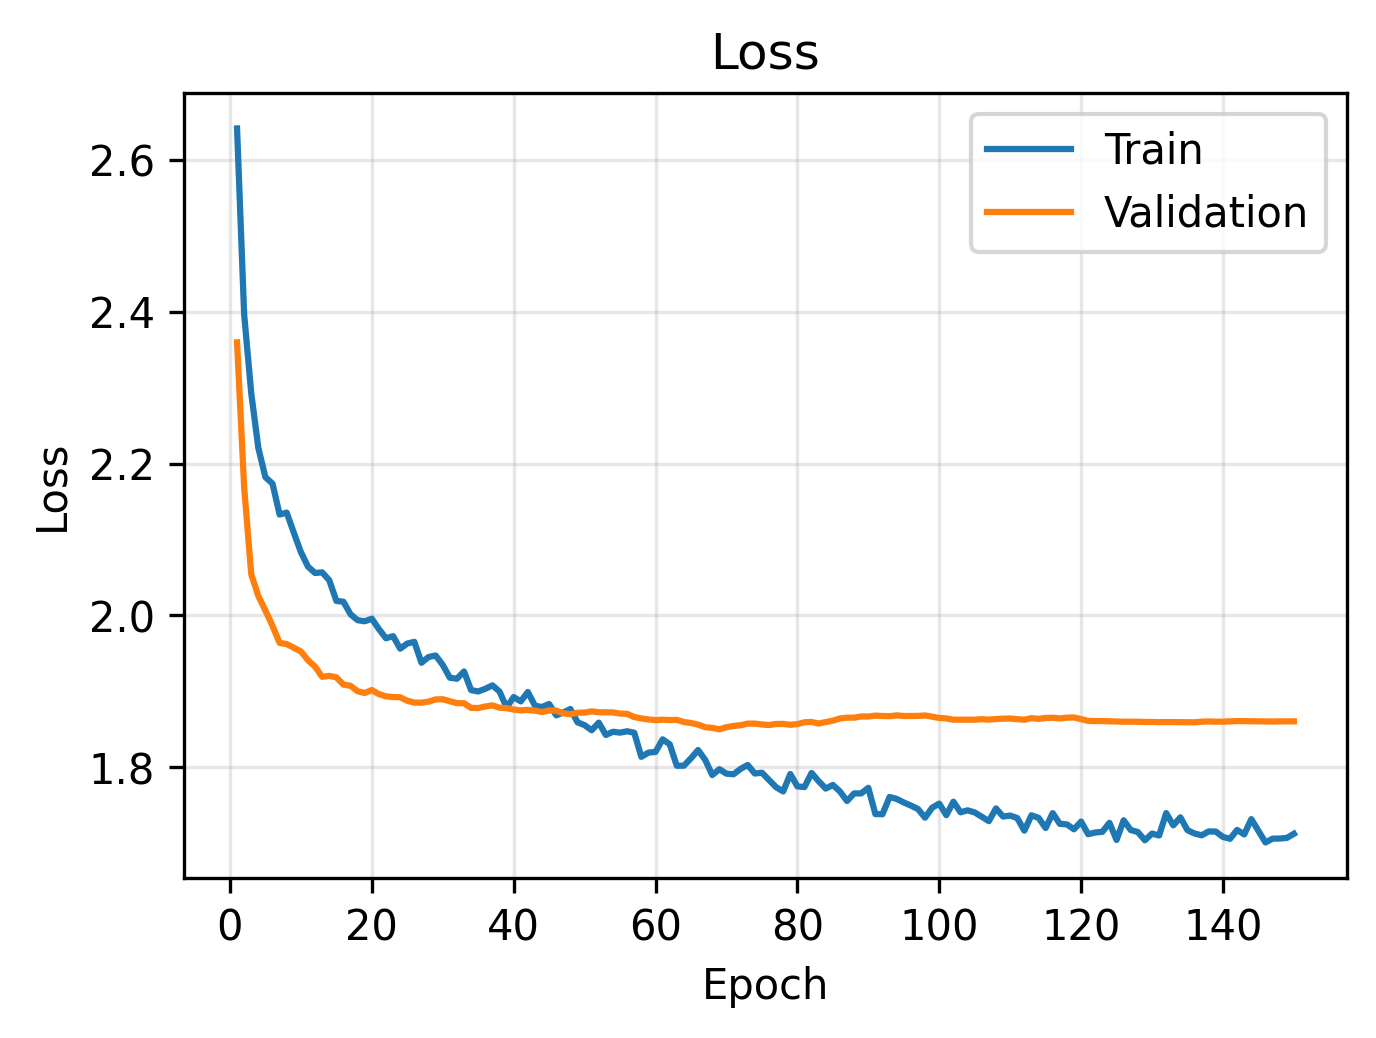

curve_miou


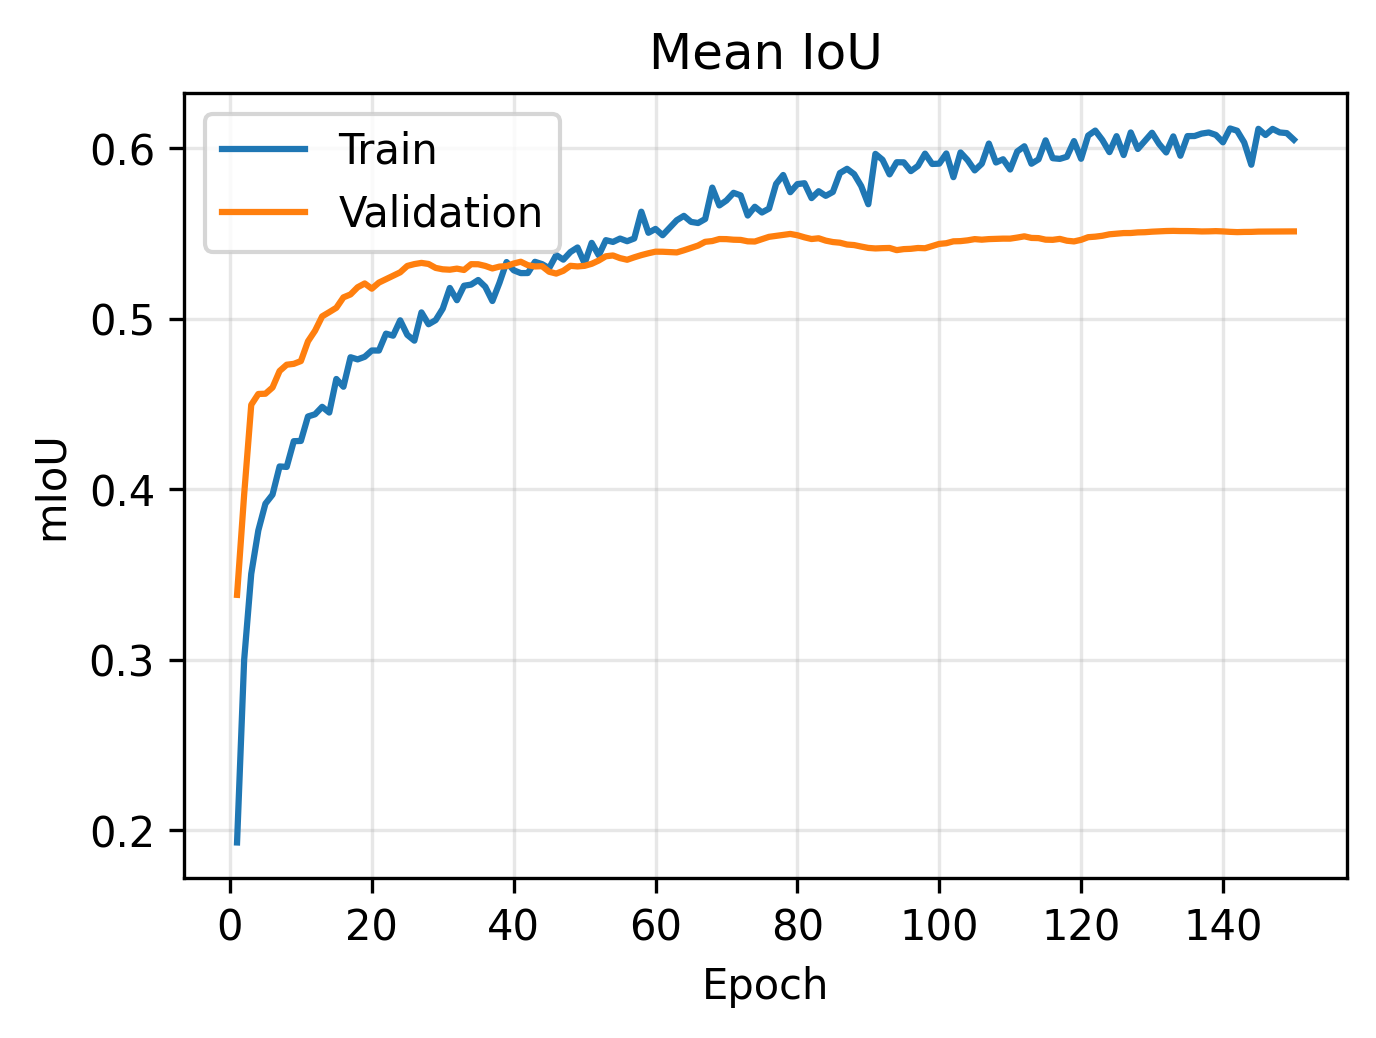

curve_macro_f1


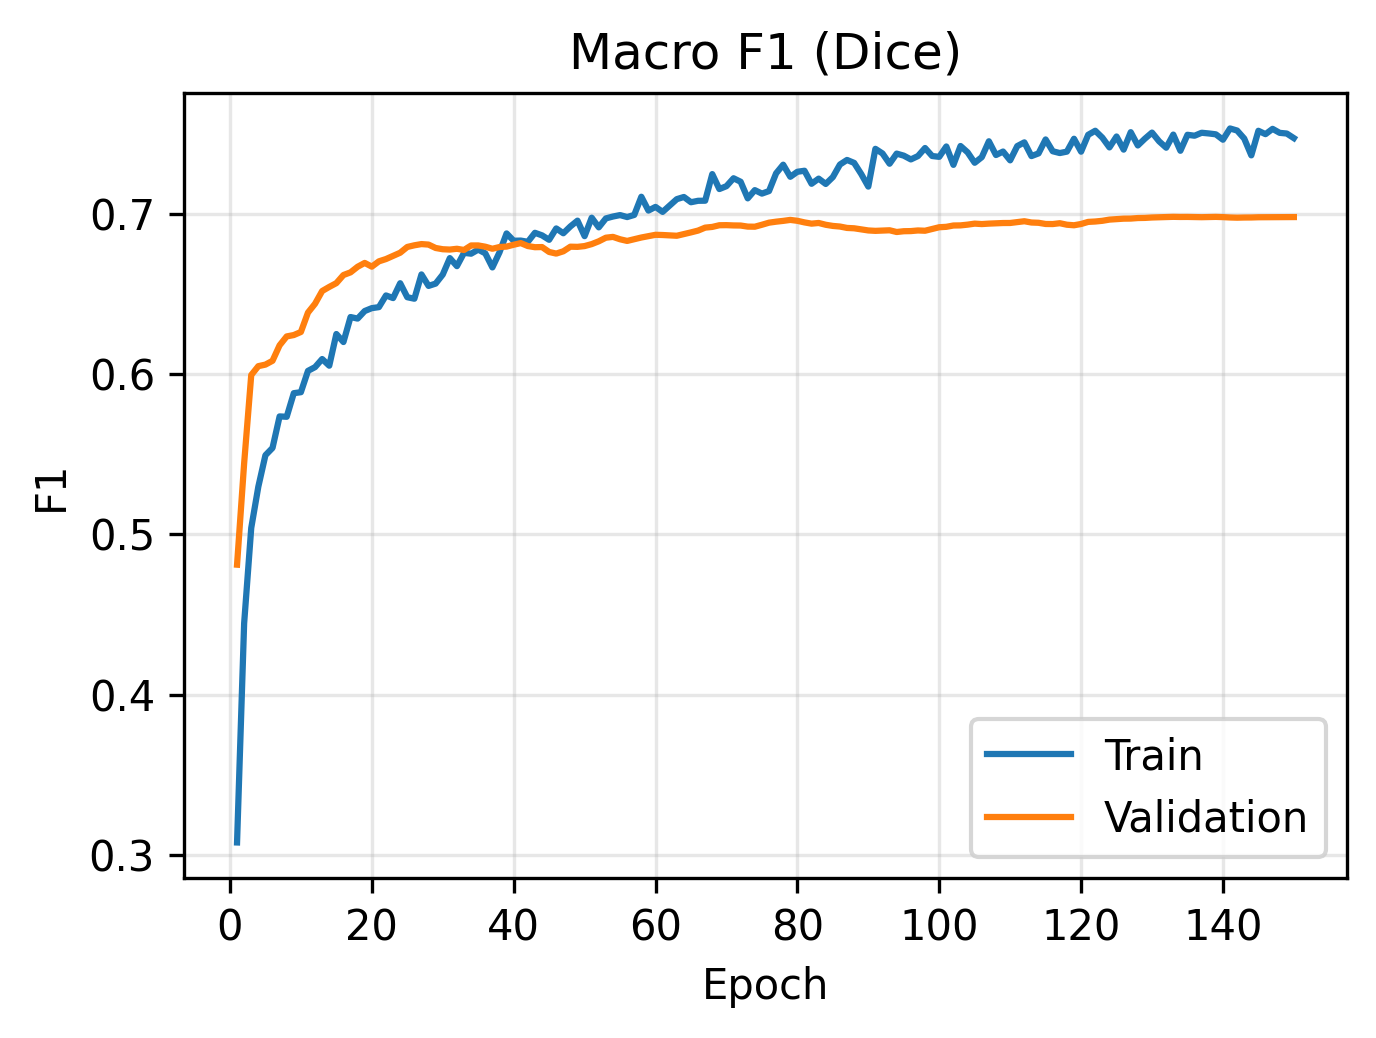

curve_lr


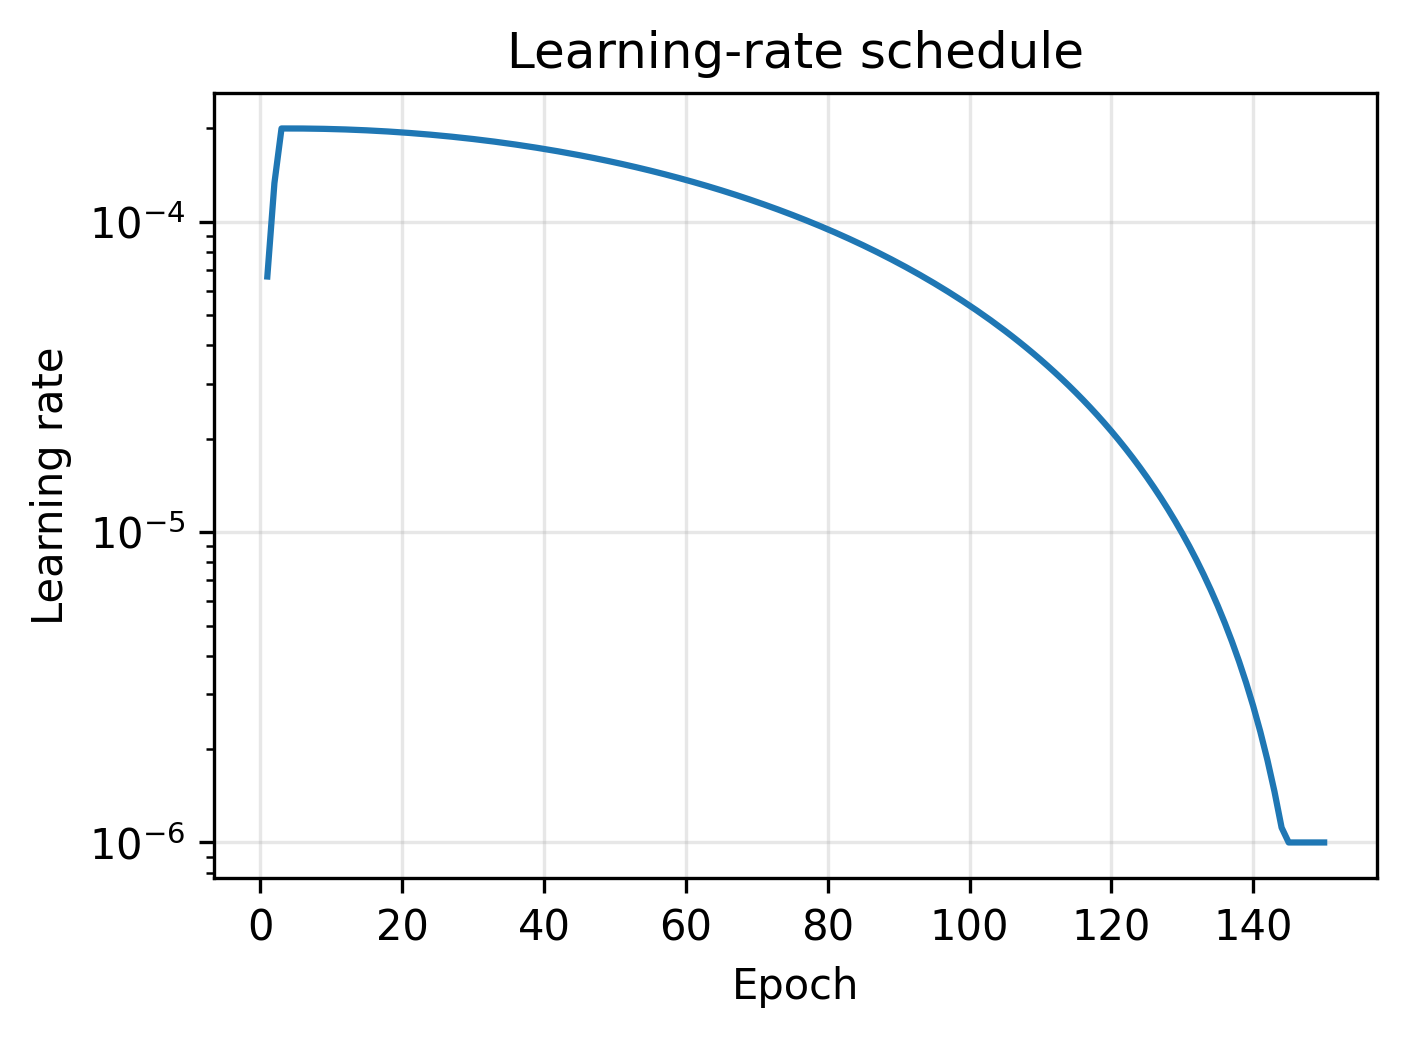

test_confusion_normalized


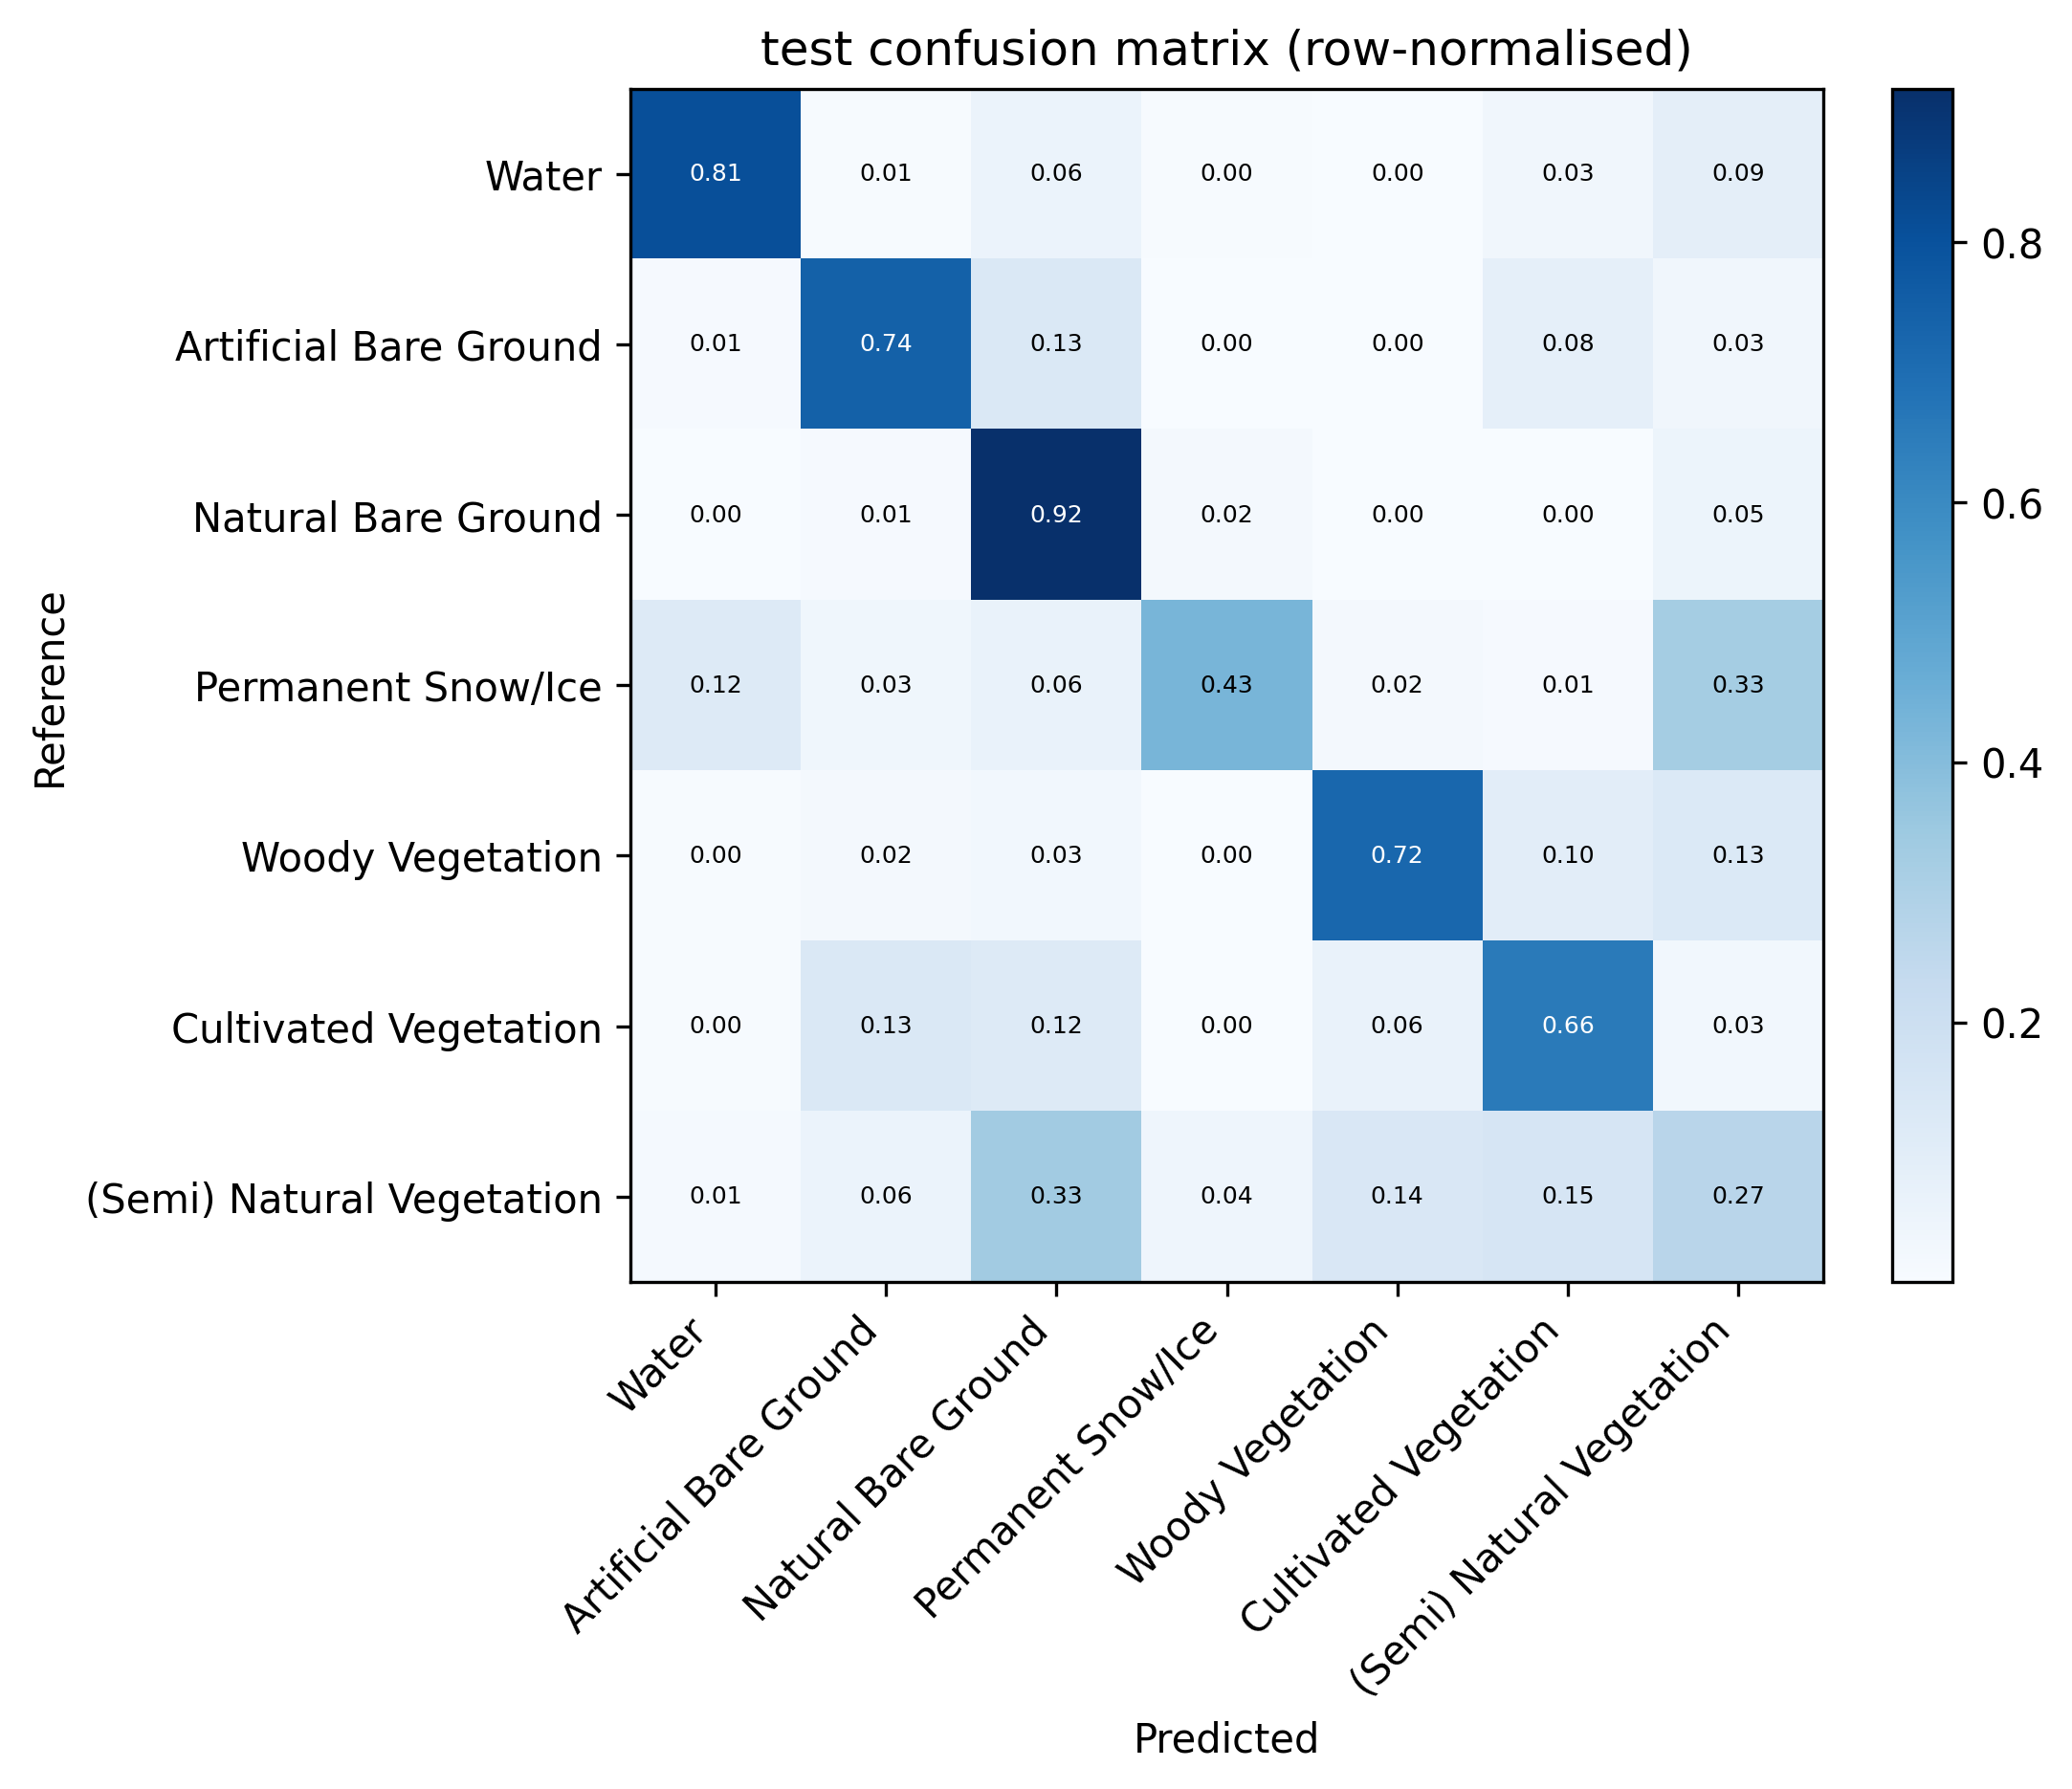

test_per_class_iou


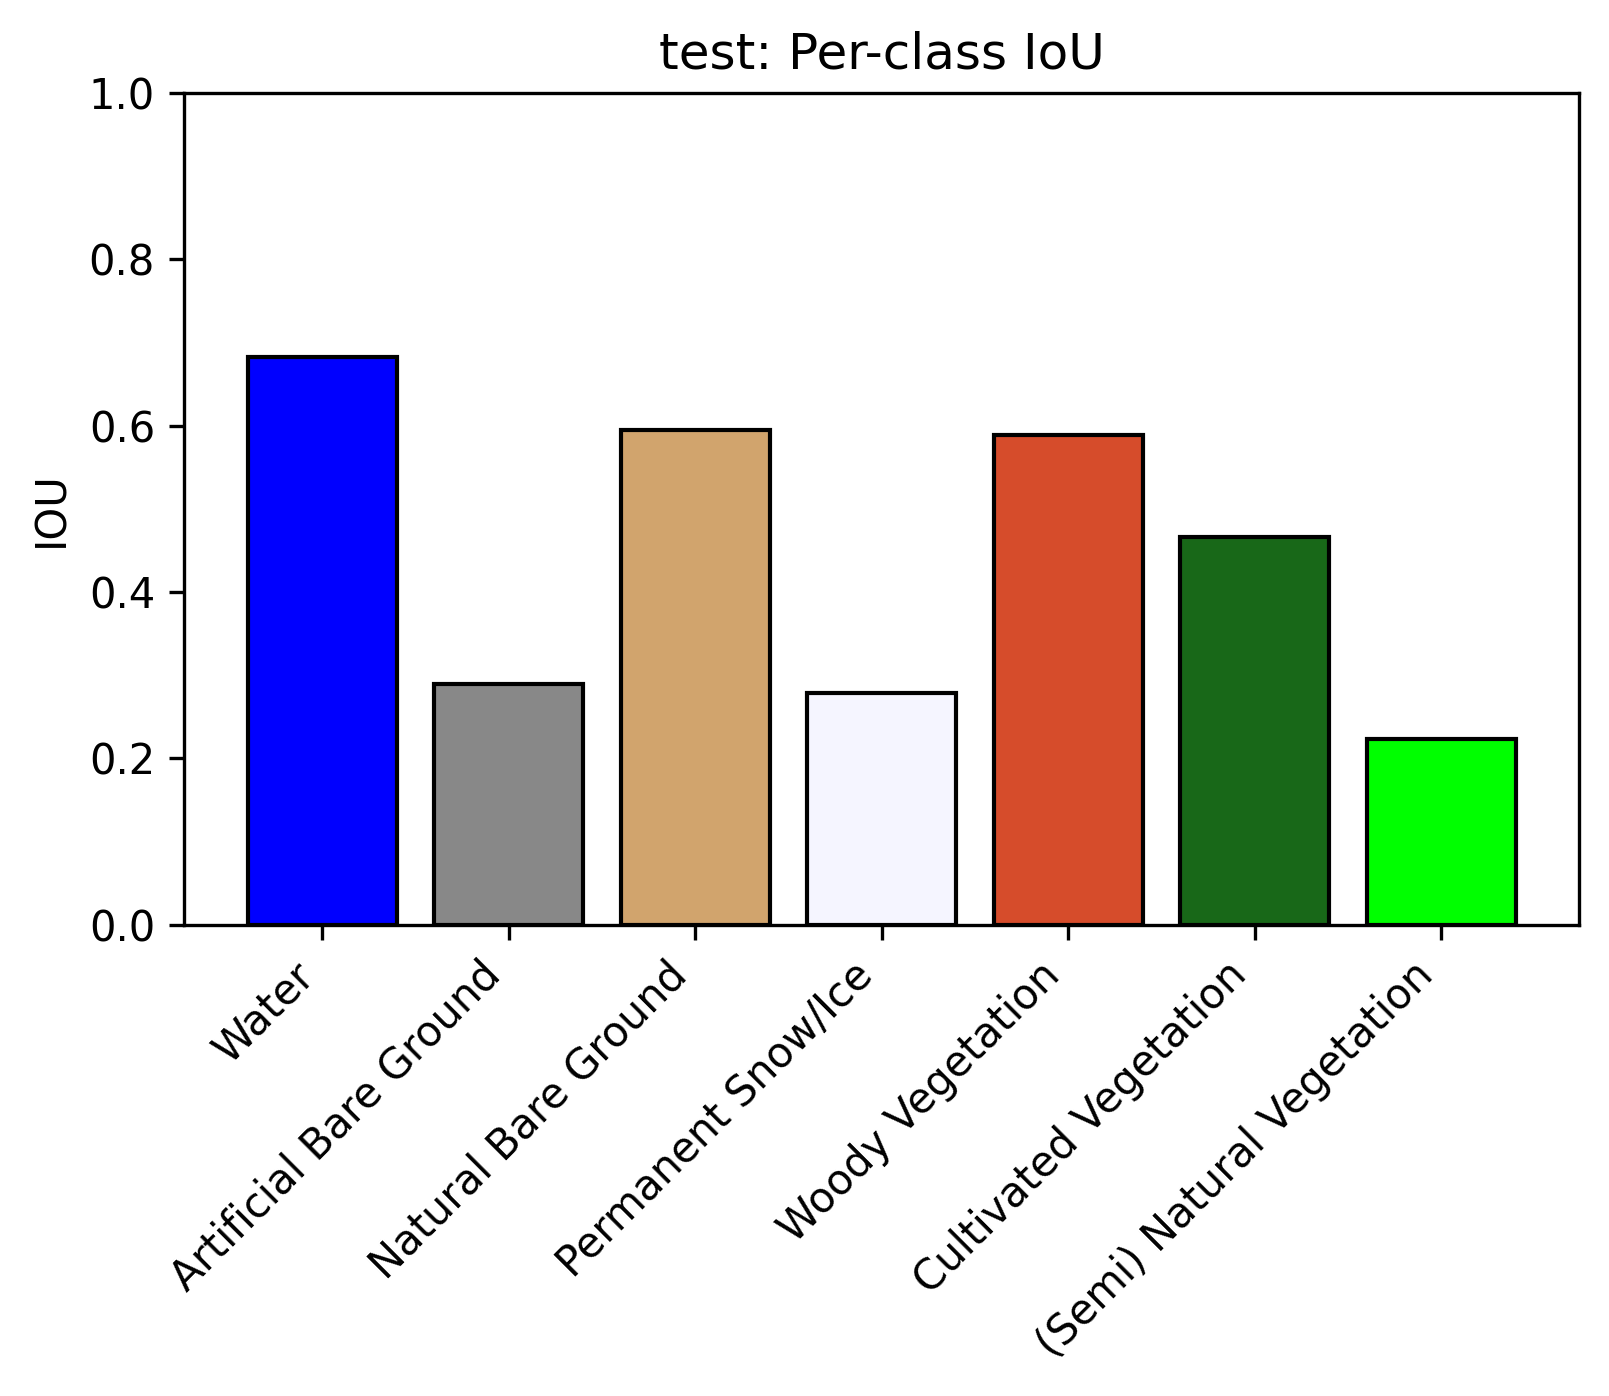

test_per_class_precision_recall


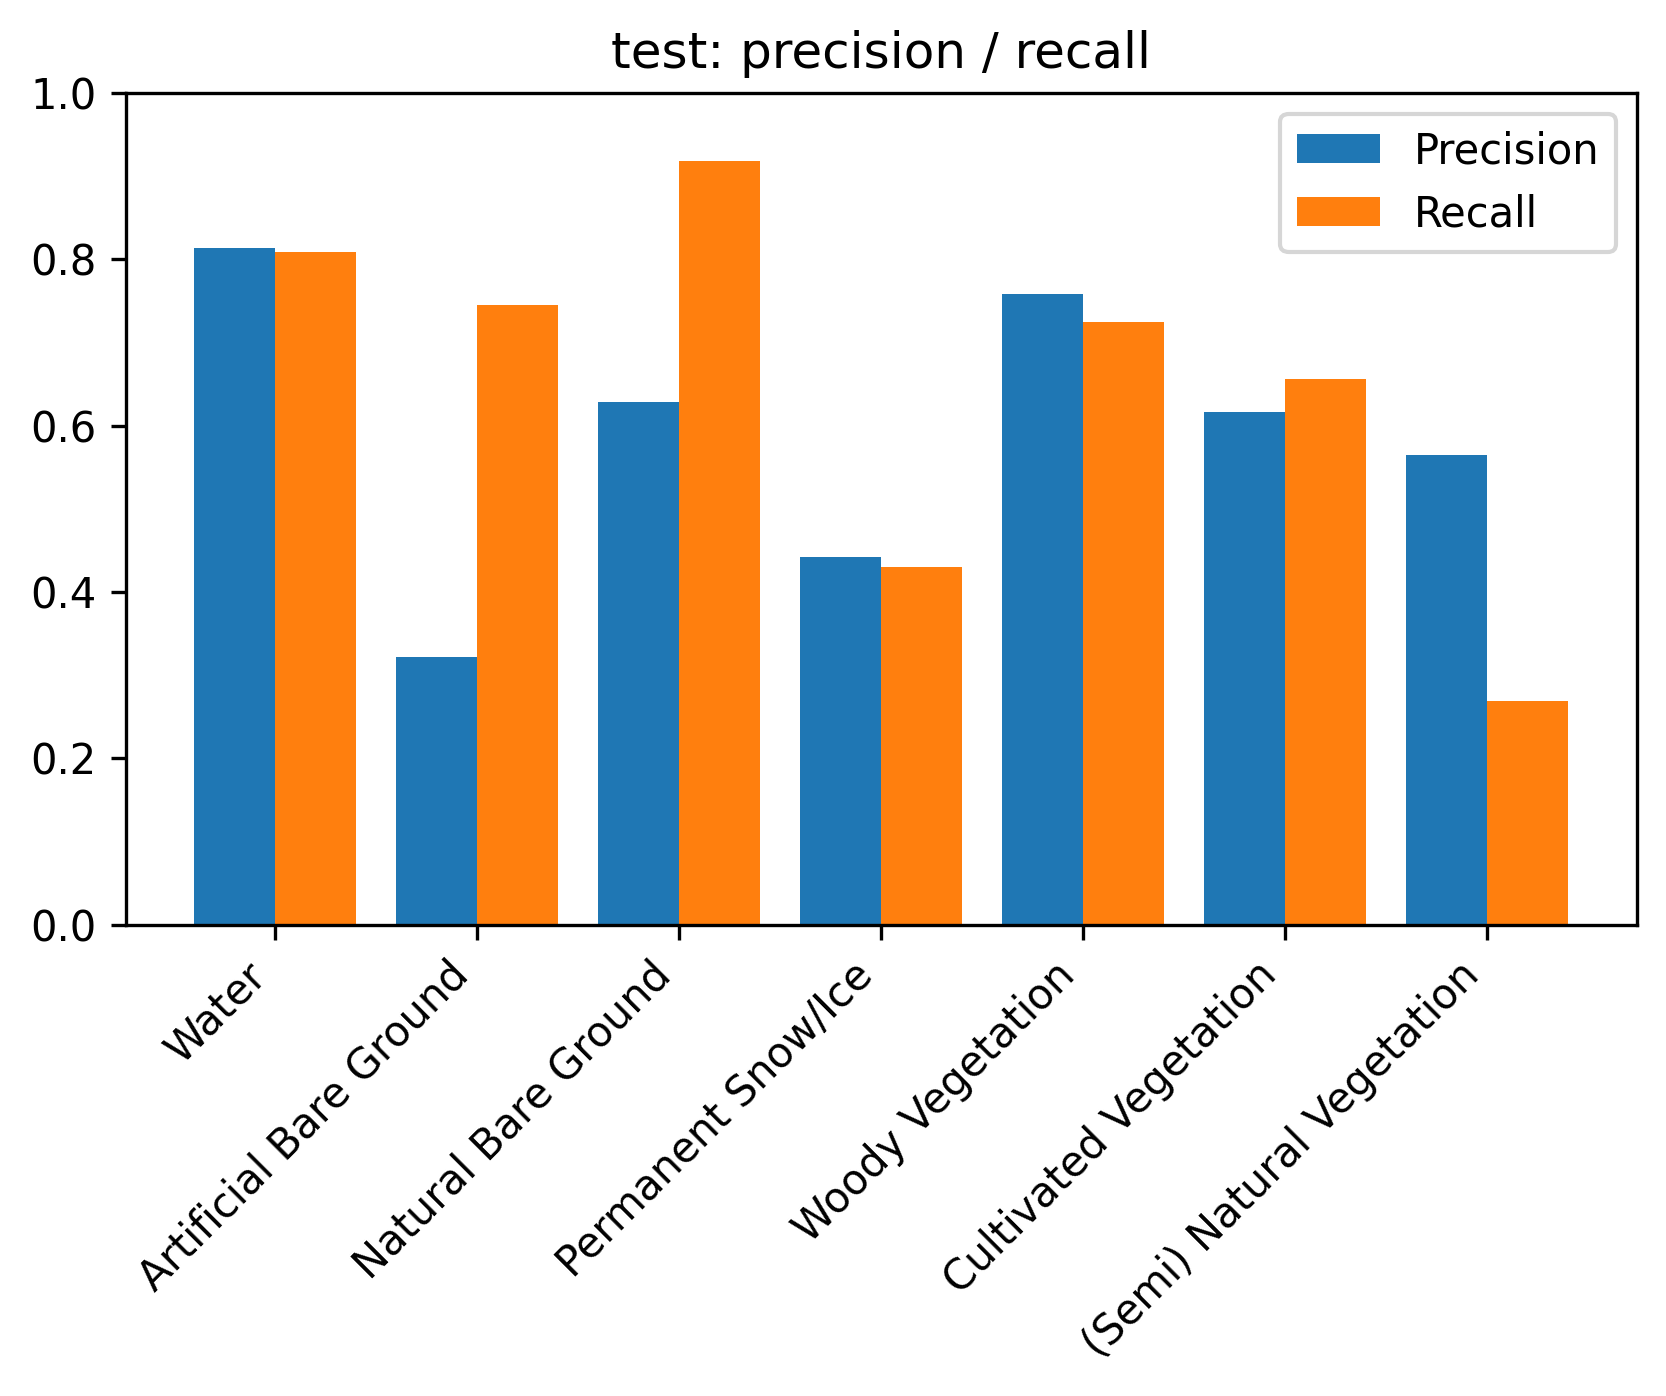

['curve_loss.eps', 'curve_loss.png', 'curve_lr.eps', 'curve_lr.png', 'curve_macro_f1.eps', 'curve_macro_f1.png', 'curve_miou.eps', 'curve_miou.png', 'test_confusion_normalized.eps', 'test_confusion_normalized.png', 'test_confusion_raw.eps', 'test_confusion_raw.png', 'test_per_class_f1_dice.eps', 'test_per_class_f1_dice.png', 'test_per_class_iou.eps', 'test_per_class_iou.png', 'test_per_class_precision_recall.eps', 'test_per_class_precision_recall.png', 'validation_confusion_normalized.eps', 'validation_confusion_normalized.png', 'validation_confusion_raw.eps', 'validation_confusion_raw.png', 'validation_per_class_f1_dice.eps', 'validation_per_class_f1_dice.png', 'validation_per_class_iou.eps', 'validation_per_class_iou.png', 'validation_per_class_precision_recall.eps', 'validation_per_class_precision_recall.png']
[sam_models] drop_path_rate=0.2 -> 23 DropPath modules in the encoder (0 means it was NOT applied)
[sam_models] frozen: patch_embed/pos_embed + blocks 0..4 -> trainable encode

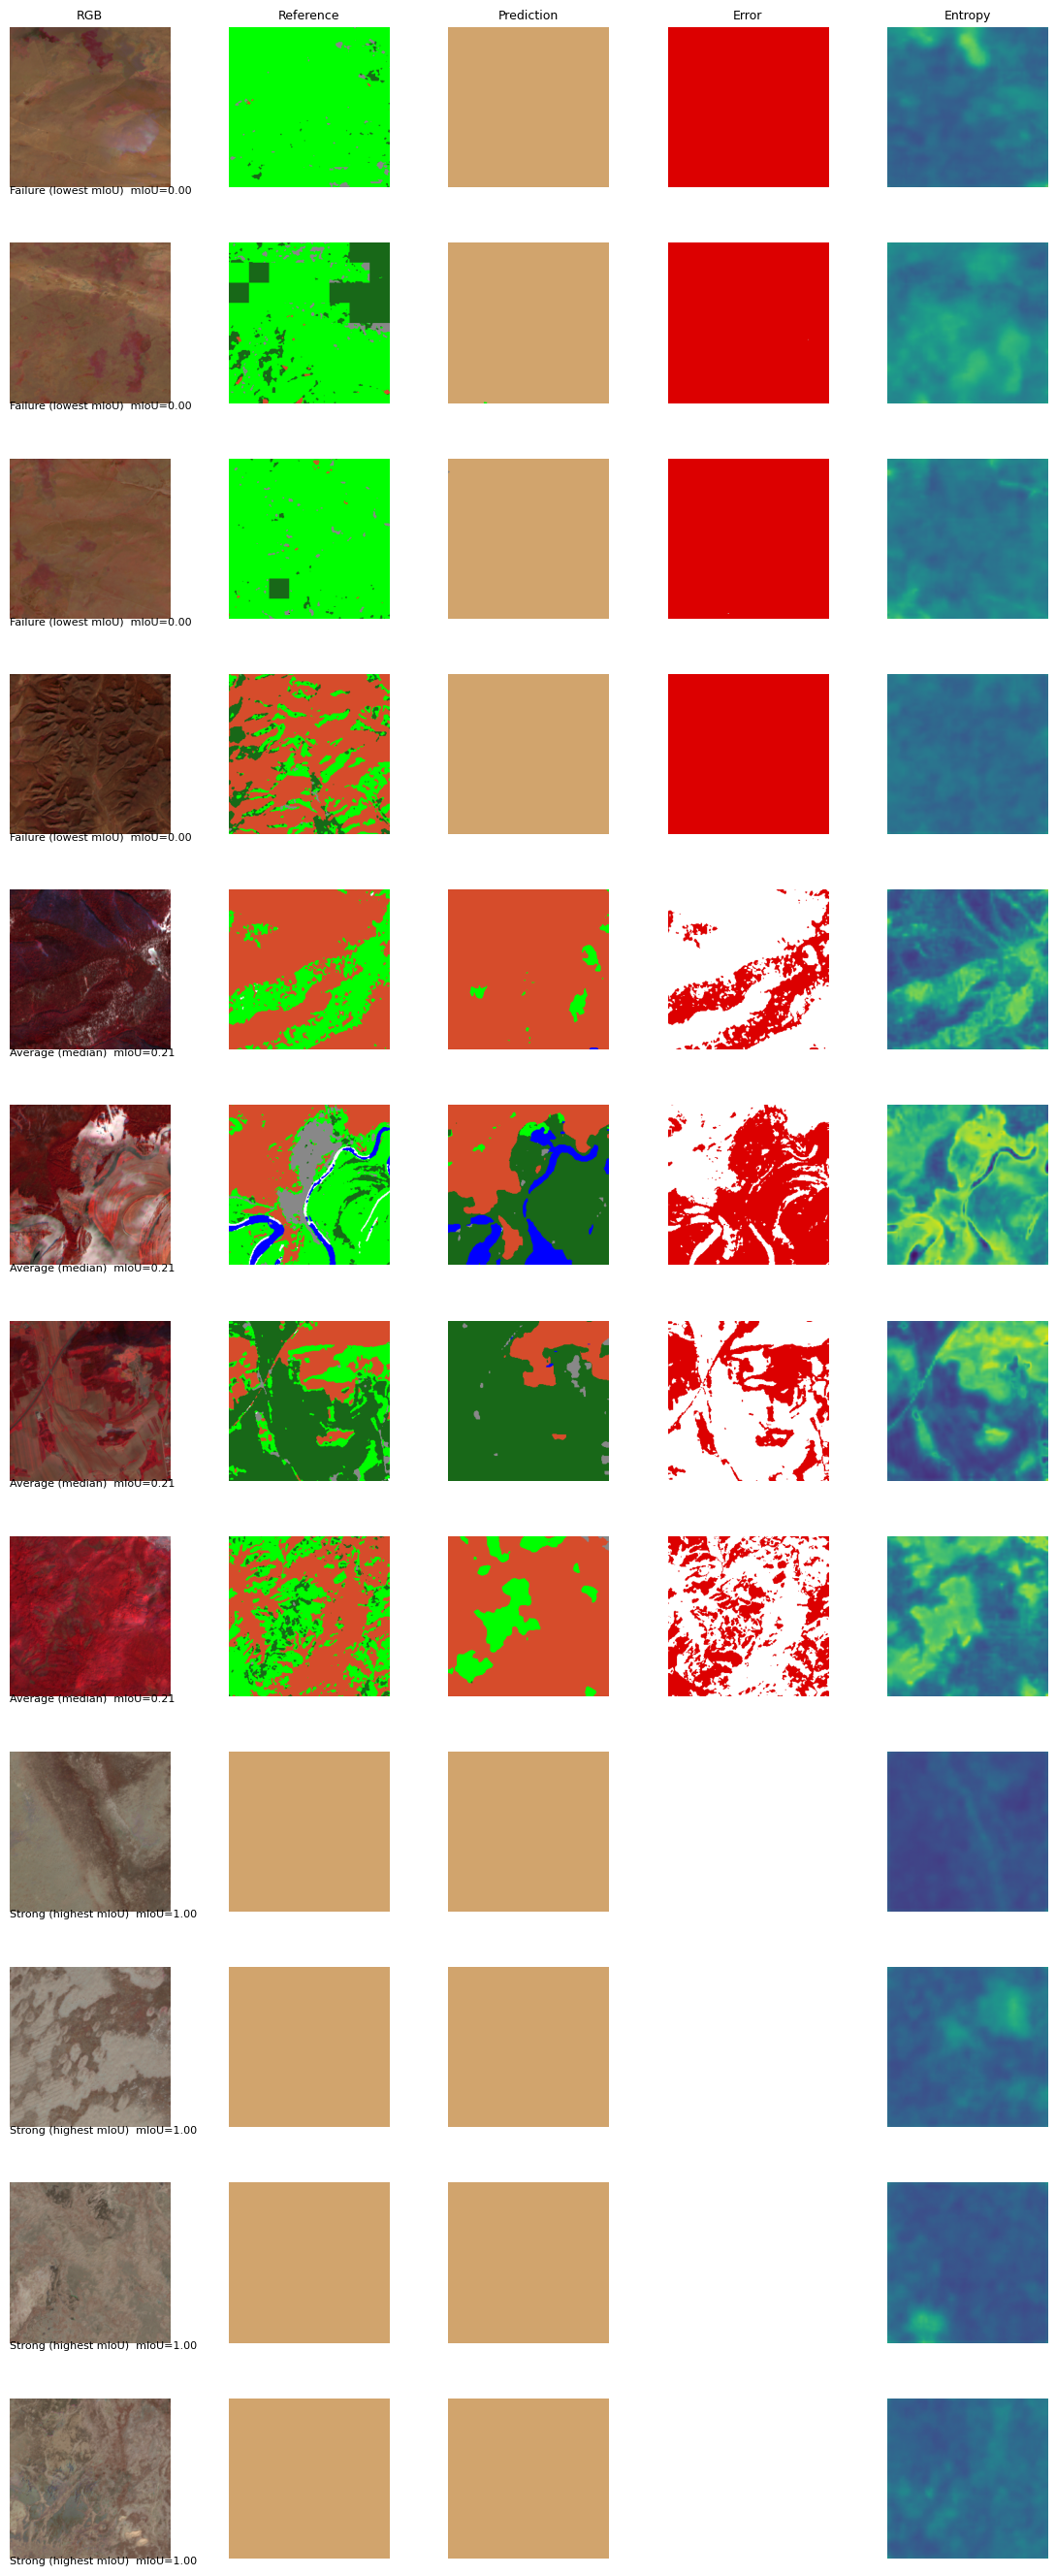

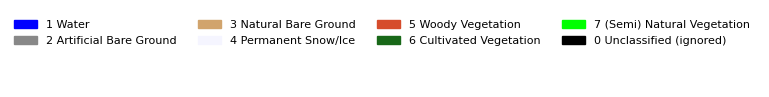

In [26]:
from IPython.display import Image as IPImage, display
fd = f"{c_main['exp_dir']}/figures"
for f in ["curve_loss", "curve_miou", "curve_macro_f1", "curve_lr", "test_confusion_normalized", "test_per_class_iou", "test_per_class_precision_recall"]:
    if os.path.exists(f"{fd}/{f}.png"): print(f); display(IPImage(f"{fd}/{f}.png", width=520))
print(sorted(os.listdir(fd)))

# ---- qualitative examples (strong / average / failure by per-image mIoU)
fd = f"{c_main['exp_dir']}/figures"
try:
    sys.path.insert(0, CODE); import importlib, common as Cm; importlib.reload(Cm)
    import torch, matplotlib.pyplot as plt, torch.nn.functional as F
    dev = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    cfg_m = json.load(open(f"{c_main['exp_dir']}/config.json")); model, _ = Cm.build_model(cfg_m, pretrained=False)
    ck = torch.load(f"{c_main['exp_dir']}/checkpoints/best.pt", map_location=dev, weights_only=False); model.load_state_dict(ck["model"]); model = model.to(dev).eval()
    pi = pd.read_csv(f"{c_main['exp_dir']}/test_per_image_results.csv").dropna(subset=["iou"]).sort_values("iou").reset_index(drop=True)
    pick = {"Failure (lowest mIoU)": pi.iloc[:4], "Average (median)": pi.iloc[len(pi)//2-2:len(pi)//2+2], "Strong (highest mIoU)": pi.iloc[-4:]}
    ds = Cm.LULCDataset(f"{ROOT}/splits/test_manifest.csv", cfg_m, train=False); idmap = {v: i for i, v in enumerate(ds.df.id)}
    fig, axs = plt.subplots(12, 5, figsize=(11, 27)); row = 0
    for title, sub in pick.items():
        for _, r in sub.iterrows():
            x, y, _ = ds[idmap[r.image_id]]
            with torch.no_grad(): lg = model(x.unsqueeze(0).to(dev)).float()
            p = lg.softmax(1)[0]; pred = p.argmax(0).cpu().numpy(); ent = (-(p * (p + 1e-8).log()).sum(0) / np.log(7)).cpu().numpy(); gt = y.numpy()
            rgb = np.clip(x.numpy().transpose(1, 2, 0) * ds.std + ds.mean, 0, 1)
            err = np.full(gt.shape + (3,), 200, np.uint8); v = gt != 255; err[v & (pred == gt)] = 255; err[v & (pred != gt)] = (220, 0, 0)
            for j, (im, t) in enumerate([(rgb, "RGB"), (Cm.colorize(gt), "Reference"), (Cm.colorize(pred), "Prediction"), (err, "Error"), (ent, "Entropy")]):
                axs[row, j].imshow(im, vmin=0, vmax=1) if j == 4 else axs[row, j].imshow(im); axs[row, j].axis("off")
                if row == 0: axs[row, j].set_title(t, fontsize=9)
            axs[row, 0].text(0, -0.05, f"{title}  mIoU={r.iou:.2f}", transform=axs[row, 0].transAxes, fontsize=8, va="bottom"); row += 1
    plt.tight_layout(); fig.savefig(f"{fd}/qualitative_examples.png", dpi=200, bbox_inches="tight"); fig.savefig(f"{fd}/qualitative_examples.eps", bbox_inches="tight"); plt.show()
    from matplotlib.patches import Patch
    fig2, ax2 = plt.subplots(figsize=(7, 1)); ax2.axis("off"); ax2.legend(handles=[Patch(color=np.array(Cm.CLASS_COLORS_SRC[i]) / 255, label=f"{i} {Cm.CLASS_NAMES_SRC[i]}") for i in range(1, 8)] + [Patch(color="black", label="0 Unclassified (ignored)")], ncol=4, frameon=False, fontsize=8)
    fig2.savefig(f"{fd}/legend.png", dpi=300, bbox_inches="tight"); fig2.savefig(f"{fd}/legend.eps", bbox_inches="tight"); plt.show()
    del model; torch.cuda.empty_cache()
except Exception as _e:
    print('Qualitative figure skipped (non-essential):', repr(_e))


## 17. Slim the Output (drop optimiser checkpoints) and list what will be downloaded

In [27]:
# ------------------------------------------------------------------ keep the Output zip small: drop optimiser/full checkpoints (bestmodel.pt has the weights)
for d in glob.glob(f"{ROOT}/experiments/*/"):
    shutil.rmtree(f"{d}checkpoints", ignore_errors=True)
for d in glob.glob(f"{ROOT}/**/__pycache__", recursive=True) + glob.glob("/kaggle/working/inference/__pycache__"):
    shutil.rmtree(d, ignore_errors=True)
assert os.path.getsize("/kaggle/working/bestmodel.pt") > 10 * 2**20, "bestmodel.pt missing or too small"
tot = 0
for dp, _, fs in os.walk("/kaggle/working"):
    tot += sum(os.path.getsize(os.path.join(dp, f)) for f in fs)
print(f"/kaggle/working total size = {tot/2**20:.0f} MiB (this is what the Output zip will contain)\n")
print(subprocess.run("cd /kaggle/working && ls -la bestmodel.pt inference && du -h --max-depth=2 lulc_research | sort -h | tail -12", shell=True, capture_output=True, text=True).stdout)
print("DONE. Download: notebook page > Output tab > 'Download All'. The model is /bestmodel.pt; inference helper is in /inference/predict.py")


/kaggle/working total size = 293 MiB (this is what the Output zip will contain)

-rw-r--r-- 1 root root 278724171 Nov 12 19:16 bestmodel.pt

inference:
total 56
drwxr-xr-x 2 root root  4096 Nov 12 19:16 .
drwxr-xr-x 4 root root  4096 Nov 12 19:16 ..
-rw-r--r-- 1 root root   270 Nov 12 19:16 class_colors.json
-rw-r--r-- 1 root root 23680 Nov 12 19:16 common.py
-rw-r--r-- 1 root root  2614 Nov 12 19:16 io_utils.py
-rw-r--r-- 1 root root  5399 Nov 12 19:16 predict.py
-rw-r--r-- 1 root root  5249 Nov 12 19:16 sam_models.py
12K	lulc_research/reproducibility
24K	lulc_research/preprocessing
68K	lulc_research/code
252K	lulc_research/splits
1.4M	lulc_research/dataset_analysis
21M	lulc_research/experiments
21M	lulc_research/experiments/sam2_semantic_hiera_bplus_seed42_20261112_180029
23M	lulc_research

DONE. Download: notebook page > Output tab > 'Download All'. The model is /bestmodel.pt; inference helper is in /inference/predict.py
